In [342]:
import pandas as pd
import numpy as np 
import hashlib
import matplotlib.pyplot as plt
import re
import seaborn as sns 
import json
import math
import importlib.util

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer   
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.decomposition import PCA 
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_curve,
    classification_report,
    roc_auc_score,
    silhouette_score,
    confusion_matrix,
    f1_score, 
)
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold,cross_val_score
from lightgbm import LGBMClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [343]:
gold_hist = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\df_historico.csv').reset_index()
gold_fight = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutas_finais.csv')
gold_fighter = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutadores.csv')

C:\Users\edude\AppData\Local\Temp\ipykernel_99764\4159661384.py:2: DtypeWarning: Columns (100) have mixed types. Specify dtype option on import or set low_memory=False.
  gold_fight = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutas_finais.csv')


#### Nesse documento qual será o objetivo:

- Exploração de técnicas não supervisionadas e supervisionadas:
    - Objetivo:
        - Clusterização para identificar perfis de luta distintos a partir do histórico de desempenho dos atletas.
        - Anomalias: 
            - Anomalia de lutadores.
            - Anomalia de confrontos.
        - Predição de vencedor.

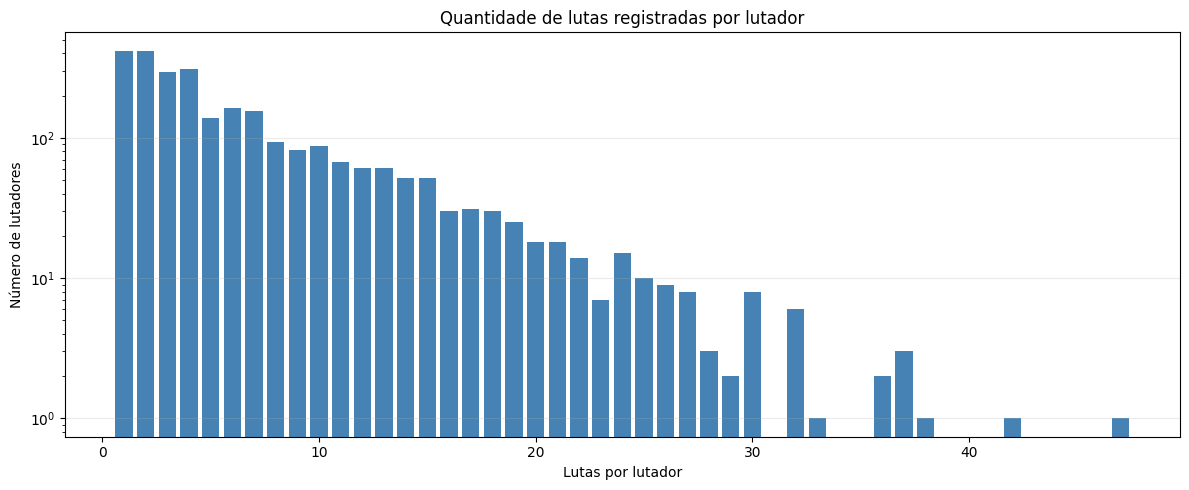

,mínimo_lutas_anteriores,observações_elegíveis,%_observações,lutadores_com_observação_elegível,%_lutadores
0,0,17472,100.0,2693,100.0
1,1,14730,84.3,2271,84.3
2,2,12486,71.5,1860,69.1
3,3,10629,60.8,1564,58.1
4,4,9064,51.9,1255,46.6
5,5,7813,44.7,1117,41.5
6,8,4939,28.3,704,26.1
7,10,3616,20.7,536,19.9


In [344]:
colunas_necessarias = ["fighter_id", "fight_id_hist", "qtd_lutas_anteriores"]
faltando = [col for col in colunas_necessarias if col not in gold_hist.columns]

if faltando:
    raise ValueError(f"Colunas ausentes em gold_hist: {faltando}")

base = gold_hist[colunas_necessarias].copy()

if base[["fighter_id", "fight_id_hist"]].isna().any().any():
    raise ValueError("Há registros sem fighter_id ou fight_id_hist.")

duplicados = base.duplicated(["fighter_id", "fight_id_hist"], keep=False)
if duplicados.any():
    raise ValueError(
        f"Foram encontradas {duplicados.sum()} linhas duplicadas por lutador/luta. "
        "Verifique-as antes de contar as observações."
    )

base["qtd_lutas_anteriores"] = pd.to_numeric(
    base["qtd_lutas_anteriores"], errors="coerce"
)

if base["qtd_lutas_anteriores"].isna().any():
    raise ValueError("qtd_lutas_anteriores contém valores ausentes ou não numéricos.")
 
lutas_por_lutador = (
    base.groupby("fighter_id")["fight_id_hist"]
    .nunique()
    .rename("total_lutas")
)

frequencia = lutas_por_lutador.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(frequencia.index, frequencia.values, color="steelblue")
ax.set_title("Quantidade de lutas registradas por lutador")
ax.set_xlabel("Lutas por lutador")
ax.set_ylabel("Número de lutadores")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
 
total_lutadores = base["fighter_id"].nunique()
total_observacoes = len(base)

limites = [0, 1, 2, 3, 4, 5, 8, 10]
linhas = []

for minimo in limites:
    elegiveis = base.loc[base["qtd_lutas_anteriores"] >= minimo]

    linhas.append({
        "mínimo_lutas_anteriores": minimo,
        "observações_elegíveis": len(elegiveis),
        "%_observações": 100 * len(elegiveis) / total_observacoes,
        "lutadores_com_observação_elegível": elegiveis["fighter_id"].nunique(),
        "%_lutadores": 100 * elegiveis["fighter_id"].nunique() / total_lutadores,
    })

resumo_limites = pd.DataFrame(linhas)
display(resumo_limites.round(1))

In [345]:
colunas_luta = ["red_fighter_id", "blue_fighter_id", "bout_type"]
colunas_faltando = [
    coluna for coluna in colunas_luta
    if coluna not in gold_fight.columns
]
if colunas_faltando:
    raise ValueError(f"Colunas ausentes em gold_fight: {colunas_faltando}")

colunas_fighter = [
    "fighter_id", "height_cm", "peso_kg", "reach_cm"
]
colunas_faltando = [
    coluna for coluna in colunas_fighter
    if coluna not in gold_fighter.columns
]
if colunas_faltando:
    raise ValueError(f"Colunas ausentes em gold_fighter: {colunas_faltando}")

if gold_fighter["fighter_id"].duplicated().any():
    raise ValueError("gold_fighter possui fighter_id duplicado.")

# Coloca red e blue no mesmo formato: uma linha por atleta/luta.
red = gold_fight[["red_fighter_id", "bout_type"]].rename(
    columns={"red_fighter_id": "fighter_id"}
)
blue = gold_fight[["blue_fighter_id", "bout_type"]].rename(
    columns={"blue_fighter_id": "fighter_id"}
)

participacoes = pd.concat([red, blue], ignore_index=True)
participacoes = participacoes.dropna(
    subset=["fighter_id", "bout_type"]
).copy()

# Padroniza o nome da divisão.
participacoes["categoria"] = (
    participacoes["bout_type"]
    .astype("string")
    .str.replace(r"\s+Bout$", "", regex=True)
    .str.strip()
)

# Infere sexo somente quando a categoria dá evidência suficiente.
categoria_minuscula = participacoes["categoria"].str.lower()

divisoes_conhecidas = (
    "strawweight|flyweight|bantamweight|featherweight|"
    "lightweight|welterweight|middleweight|light heavyweight|heavyweight"
)

feminino = categoria_minuscula.str.contains(
    r"women|woman|female",
    regex=True,
    na=False
)
divisao_reconhecida = categoria_minuscula.str.contains(
    divisoes_conhecidas,
    regex=True,
    na=False
)

participacoes["sexo_inferido"] = pd.NA
participacoes.loc[feminino, "sexo_inferido"] = "Feminino"
participacoes.loc[
    ~feminino & divisao_reconhecida,
    "sexo_inferido"
] = "Masculino"

def moda_ou_na(serie):
    modas = serie.mode()
    return modas.iloc[0] if not modas.empty else pd.NA

perfil_categoria = (
    participacoes.groupby("fighter_id")
    .agg(
        categoria_principal=("categoria", moda_ou_na),
        sexo_inferido=("sexo_inferido", moda_ou_na),
        categorias_distintas=("categoria", "nunique"),
        participacoes=("categoria", "size"),
    )
    .reset_index()
)

# Une a categoria inferida com as medidas do lutador.
base_reach = gold_fighter[colunas_fighter].merge(
    perfil_categoria,
    on="fighter_id",
    how="left",
    validate="one_to_one",
)

for coluna in ["height_cm", "peso_kg", "reach_cm"]:
    base_reach[coluna] = pd.to_numeric(
        base_reach[coluna], errors="coerce"
    )

print("Atletas na dimensão:", len(base_reach))
print("Atletas com categoria vinculada:", base_reach["categoria_principal"].notna().sum())
print("Atletas com categoria variada na carreira:", base_reach["categorias_distintas"].gt(1).sum())
print("Atletas com sexo não inferido:", base_reach["sexo_inferido"].isna().sum())

print("\nCategorias mais frequentes:")
display(base_reach["categoria_principal"].value_counts(dropna=False).head(20))

print("\nResumo de height_cm, peso_kg e reach_cm:")
display(
    base_reach[
        ["height_cm", "peso_kg", "reach_cm"]
    ].describe().round(1)
)

# Avalia altura/reach por sexo e categoria.
com_medidas = base_reach.dropna(
    subset=["height_cm", "reach_cm", "sexo_inferido", "categoria_principal"]
).copy()

resumo_grupos = (
    com_medidas.groupby(
        ["sexo_inferido", "categoria_principal"],
        observed=True
    )
    .agg(
        atletas=("fighter_id", "nunique"),
        altura_media_cm=("height_cm", "mean"),
        reach_medio_cm=("reach_cm", "mean"),
        correlacao_altura_reach=(
            "height_cm",
            lambda altura: altura.corr(
                com_medidas.loc[altura.index, "reach_cm"]
            )
        ),
    )
    .reset_index()
    .sort_values(["sexo_inferido", "categoria_principal"])
)

print("\nRelação entre altura e reach por sexo/categoria:")
display(resumo_grupos.round(2))

Atletas na dimensão: 4524
Atletas com categoria vinculada: 2693
Atletas com categoria variada na carreira: 1057
Atletas com sexo não inferido: 1899

Categorias mais frequentes:


categoria_principal
<NA>                             1831
Lightweight                       441
Welterweight                      394
Middleweight                      345
Bantamweight                      269
Featherweight                     264
Heavyweight                       264
Light Heavyweight                 193
Flyweight                         129
Women's Strawweight               100
Open Weight                        76
Women's Bantamweight               72
Women's Flyweight                  70
Catch Weight                       13
UFC Welterweight Title              7
Women's Featherweight               7
UFC Light Heavyweight Title         6
UFC Middleweight Title              5
UFC Heavyweight Title               3
UFC Women's Strawweight Title       3
Name: count, dtype: Int64


Resumo de height_cm, peso_kg e reach_cm:


,height_cm,peso_kg,reach_cm
count,4287.0,3881.0,2835.0
mean,178.1,76.4,181.7
std,9.0,17.8,10.9
min,139.7,47.6,147.3
25%,172.7,65.8,175.3
50%,177.8,70.3,182.9
75%,185.4,83.9,189.9
max,226.1,349.3,213.4



Relação entre altura e reach por sexo/categoria:


c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,sexo_inferido,categoria_principal,atletas,altura_media_cm,reach_medio_cm,correlacao_altura_reach
0,Feminino,Catch Weight,1,175.26,173.99,NaN
1,Feminino,Road to UFC 3 Women's Strawweight Tournament T...,2,163.83,161.29,1.00
2,Feminino,UFC Women's Bantamweight Title,2,171.45,171.45,1.00
3,Feminino,UFC Women's Featherweight Title,1,172.72,172.72,NaN
4,Feminino,UFC Women's Flyweight Title,2,165.10,166.37,NaN
5,Feminino,UFC Women's Strawweight Title,3,165.10,163.41,0.87
6,Feminino,Ultimate Fighter 18 Women's Bantamweight Tourn...,1,170.18,172.72,NaN
7,Feminino,Women's Bantamweight,71,169.54,170.96,0.65
8,Feminino,Women's Featherweight,7,173.45,176.35,0.57
9,Feminino,Women's Flyweight,70,166.70,168.91,0.61


---------------
### Clusterização 
Porém antes de darmos inicio ao clusterização identificamos alguns casos de nulos em informações que iriamos utilizar: 
- Coluna reach_cm, que tem como objetivo trazer o alcante/envergadura do lutador. 
- Idade do lutador na época da luta

Como pensamos em resolver criando, entender se há relação entre variáveis fisicas e de categoria para tentar realizar um preenchimento (na variavel reach). [não deu certo]

- Iremos preencher inicialmente como indefinido e vamos fazer uma clusterização temporal espansiva.
    - `Que é nada mais que uma clusterização que recebe uma quantidade de registro de calibração temporal, com objetivo de acompanhar a transição sem usar o futuro.`
    - `Definimos de primeira mão mão um perfil de lutador, seria lutadores sem experiência para definição de perfil técnico.`
- Features que iremos utilizar na primeira versão:
    - Dados históricos de lutas anteriores.
    - Dados Fisícos dos atletas
    - Sexo e Categoria

In [ ]:
features_antes = [
    "sig_str_min_antes",
    "sig_str_recebidos_min_antes",
    "td_15min_antes",
    "td_tent_15min_antes",
    "sub_15min_antes",
    "rev_15min_antes",
    "kd_15min_antes",
    "ctrl_pct_antes",
    "sig_str_acc_antes",
    "str_def_antes",
    "td_acc_antes",
    "td_def_antes",
]
 
MIN_LUTAS_ANTES = 3
MIN_MINUTOS_ANTES = 15


colunas_obrigatorias = [
    "fighter_id",
    "event_date",
    "qtd_lutas_anteriores",
    "tempo_luta_segundos",
]

faltando = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in gold_hist.columns
]
if faltando:
    raise ValueError(f"Colunas ausentes em gold_hist: {faltando}")

if "fighter_id" not in gold_fighter.columns:
    raise ValueError("gold_fighter não contém fighter_id.")

hist = gold_hist.copy()
cadastro = gold_fighter.copy()

hist["fighter_id"] = (
    hist["fighter_id"].astype("string").str.strip()
)
cadastro["fighter_id"] = (
    cadastro["fighter_id"].astype("string").str.strip()
)

if hist["fighter_id"].isna().any():
    raise ValueError("gold_hist contém fighter_id ausente.")

if cadastro["fighter_id"].isna().any():
    raise ValueError("gold_fighter contém fighter_id ausente.")

if cadastro["fighter_id"].duplicated().any():
    duplicados = cadastro.loc[
        cadastro["fighter_id"].duplicated(keep=False),
        "fighter_id",
    ].unique()

    raise ValueError(
        "gold_fighter contém fighter_id duplicados: "
        f"{duplicados[:10].tolist()}"
    )

hist["event_date"] = pd.to_datetime(
    hist["event_date"],
    errors="coerce",
)
hist["qtd_lutas_anteriores"] = pd.to_numeric(
    hist["qtd_lutas_anteriores"],
    errors="coerce",
)
hist["tempo_luta_segundos"] = pd.to_numeric(
    hist["tempo_luta_segundos"],
    errors="coerce",
)

if hist[
    ["event_date", "qtd_lutas_anteriores", "tempo_luta_segundos"]
].isna().any().any():
    raise ValueError(
        "Há event_date, qtd_lutas_anteriores ou tempo_luta_segundos "
        "ausente ou inválido em gold_hist."
    )

if hist["tempo_luta_segundos"].lt(0).any():
    raise ValueError("gold_hist contém duração negativa.")

# Lutas do mesmo atleta na mesma data são tratadas como um único dia.
hist["event_date"] = hist["event_date"].dt.normalize()

features_antes_disponiveis = [
    coluna for coluna in features_antes
    if coluna in hist.columns
]

if len(features_antes_disponiveis) < 2:
    raise ValueError(
        "gold_hist precisa ter pelo menos duas métricas _antes disponíveis."
    )

flags_disponiveis = [
    f"{coluna}_sem_dado_antes"
    for coluna in features_antes_disponiveis
    if f"{coluna}_sem_dado_antes" in hist.columns
]

for coluna in features_antes_disponiveis:
    hist[coluna] = pd.to_numeric(
        hist[coluna],
        errors="coerce",
    )

for flag in flags_disponiveis:
    hist[flag] = pd.to_numeric(
        hist[flag],
        errors="coerce",
    )

minimo_por_dia = (
    hist.groupby(["fighter_id", "event_date"])["qtd_lutas_anteriores"]
    .transform("min")
)

candidatas = hist.loc[
    hist["qtd_lutas_anteriores"].eq(minimo_por_dia)
].copy()

# Se houver empate, as métricas e flags precisam concordar.
# Sem ordem confiável entre lutas do mesmo dia, não escolhemos arbitrariamente.
colunas_validar_empate = (
    features_antes_disponiveis + flags_disponiveis
)

conflitos = (
    candidatas
    .groupby(["fighter_id", "event_date"])[colunas_validar_empate]
    .nunique(dropna=False)
    .gt(1)
)

dias_com_conflito = conflitos.any(axis=1)

if dias_com_conflito.any():
    exemplos = (
        dias_com_conflito[dias_com_conflito]
        .reset_index()[["fighter_id", "event_date"]]
        .head(10)
    )

    raise ValueError(
        "As métricas pré-luta diferem entre registros empatados no mesmo "
        "lutador-dia. Revise estes casos antes de continuar:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Mantém uma linha por lutador-data.
base_cluster_dia = (
    candidatas
    .sort_values(["fighter_id", "event_date"])
    .drop_duplicates(
        subset=["fighter_id", "event_date"],
        keep="first",
    )
    .copy()
)

# Conta quantas linhas/lutas foram reunidas em cada dia.
contagem_dia = (
    hist.groupby(["fighter_id", "event_date"])
    .size()
    .rename("qtd_lutas_no_dia")
    .reset_index()
)

base_cluster_dia = base_cluster_dia.merge(
    contagem_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 4. Consolidar sexo e categoria observados naquele dia
# ------------------------------------------------------------

coluna_categoria = next(
    (
        coluna for coluna in ["categoria_luta", "bout_type"]
        if coluna in hist.columns
    ),
    None,
)

coluna_sexo = (
    "sexo_luta"
    if "sexo_luta" in hist.columns
    else None
)


def valores_unicos_ou_indef(valores, normalizar_categoria=False):
    conhecidos = valores.dropna().astype("string").str.strip()

    if normalizar_categoria:
        conhecidos = conhecidos.str.replace(
            r"\s+Bout$",
            "",
            regex=True,
        )

    conhecidos = conhecidos[conhecidos.ne("")].unique()

    # Conflitos no mesmo dia ficam explicitamente como indefinidos.
    if len(conhecidos) == 1:
        return conhecidos[0]

    return "indef"


agregacoes_contexto = {}

if coluna_sexo:
    agregacoes_contexto["sexo"] = (
        coluna_sexo,
        valores_unicos_ou_indef,
    )

if coluna_categoria:
    agregacoes_contexto["categoria_luta"] = (
        coluna_categoria,
        lambda valores: valores_unicos_ou_indef(
            valores,
            normalizar_categoria=True,
        ),
    )

if agregacoes_contexto:
    contexto_dia = (
        hist.groupby(["fighter_id", "event_date"])
        .agg(**agregacoes_contexto)
        .reset_index()
    )

    base_cluster_dia = base_cluster_dia.merge(
        contexto_dia,
        on=["fighter_id", "event_date"],
        how="left",
        validate="one_to_one",
    )



# Soma a duração das lutas do atleta no mesmo dia.
duracao_diaria = (
    hist.groupby(["fighter_id", "event_date"], as_index=False)
    .agg(
        tempo_luta_dia_segundos=("tempo_luta_segundos", "sum")
    )
    .sort_values(["fighter_id", "event_date"])
)

# Acumula apenas os dias anteriores; não inclui a duração do dia atual.
duracao_diaria["tempo_historico_min_antes"] = (
    duracao_diaria
    .groupby("fighter_id")["tempo_luta_dia_segundos"]
    .transform(lambda serie: serie.cumsum() - serie)
    / 60
)

base_cluster_dia = base_cluster_dia.merge(
    duracao_diaria[
        ["fighter_id", "event_date", "tempo_historico_min_antes"]
    ],
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)


colunas_fisicas = ["fighter_id"]

for coluna in ["height_cm", "reach_cm"]:
    if coluna in cadastro.columns:
        cadastro[coluna] = pd.to_numeric(
            cadastro[coluna],
            errors="coerce",
        )
        colunas_fisicas.append(coluna)

if "peso_kg" in cadastro.columns:
    cadastro["peso_kg"] = pd.to_numeric(
        cadastro["peso_kg"],
        errors="coerce",
    )
    colunas_fisicas.append("peso_kg")

elif "weight_lbs" in cadastro.columns:
    cadastro["peso_kg"] = (
        pd.to_numeric(cadastro["weight_lbs"], errors="coerce")
        * 0.453592
    )
    colunas_fisicas.append("peso_kg")

if len(colunas_fisicas) == 1:
    print(
        "Aviso: gold_fighter não contém height_cm, reach_cm "
        "ou peso reconhecido."
    )

base_cluster_dia = base_cluster_dia.merge(
    cadastro[colunas_fisicas],
    on="fighter_id",
    how="left",
    validate="many_to_one",
)


# Estreante: nenhuma luta anterior ao dia atual.
base_cluster_dia["sem_historico"] = (
    base_cluster_dia["qtd_lutas_anteriores"].eq(0)
)

# Elegível ao K-means somente se atingir ambos os limites.
base_cluster_dia["historico_suficiente"] = (
    base_cluster_dia["qtd_lutas_anteriores"].ge(MIN_LUTAS_ANTES)
    & base_cluster_dia["tempo_historico_min_antes"].ge(
        MIN_MINUTOS_ANTES
    )
)

# Já lutou antes, mas ainda não atingiu os critérios de elegibilidade.
base_cluster_dia["historico_curto"] = (
    ~base_cluster_dia["sem_historico"]
    & ~base_cluster_dia["historico_suficiente"]
)

base_cluster_dia["grupo_elegibilidade"] = np.select(
    [
        base_cluster_dia["sem_historico"],
        base_cluster_dia["historico_curto"],
    ],
    [
        "Sem histórico",
        "Histórico curto - perfil inconclusivo",
    ],
    default="Histórico suficiente para clusterização",
)

# Só os dias com histórico suficiente entram no K-means.
base_modelo = base_cluster_dia.loc[
    base_cluster_dia["historico_suficiente"]
].copy()

# Preserva base_cluster_dia. Na cópia de modelagem, converte em NaN
# apenas valores que as flags identificam como sem dado.
for coluna in features_antes_disponiveis:
    indicador = f"{coluna}_sem_dado_antes"

    if indicador in base_modelo.columns:
        sem_dado = base_modelo[indicador].eq(1)
        base_modelo.loc[sem_dado, coluna] = np.nan
 

if base_cluster_dia.duplicated(
    subset=["fighter_id", "event_date"]
).any():
    raise ValueError(
        "A base ainda contém mais de uma linha por lutador e data."
    )

print("Linhas diárias:", len(base_cluster_dia))
print("Lutadores únicos:", base_cluster_dia["fighter_id"].nunique())
print(
    "Dias com múltiplas lutas consolidadas:",
    int(base_cluster_dia["qtd_lutas_no_dia"].gt(1).sum()),
)
print(
    "Dias sem histórico:",
    int(base_cluster_dia["sem_historico"].sum()),
)
print(
    "Dias com histórico curto:",
    int(base_cluster_dia["historico_curto"].sum()),
)
print(
    "Dias elegíveis para K-means:",
    int(base_cluster_dia["historico_suficiente"].sum()),
)
print(
    "Lutadores elegíveis:",
    base_modelo["fighter_id"].nunique(),
)
print("Métricas _antes disponíveis:", features_antes_disponiveis)
print("Flags de ausência disponíveis:", flags_disponiveis)

display(
    base_cluster_dia["grupo_elegibilidade"]
    .value_counts()
    .rename_axis("grupo")
    .to_frame("dias")
)

colunas_exemplo = [
    "fighter_id",
    "event_date",
    "qtd_lutas_anteriores",
    "tempo_historico_min_antes",
    "qtd_lutas_no_dia",
    "sem_historico",
    "historico_curto",
    "historico_suficiente",
    *features_antes_disponiveis[:2],
]
colunas_exemplo = [
    coluna for coluna in colunas_exemplo
    if coluna in base_cluster_dia.columns
]

display(base_cluster_dia[colunas_exemplo].head(20))

Linhas diárias: 17393
Lutadores únicos: 2693
Dias com múltiplas lutas consolidadas: 57
Dias sem histórico: 2693
Dias com histórico curto: 4285
Dias elegíveis para K-means: 10415
Lutadores elegíveis: 1530
Métricas _antes disponíveis: ['sig_str_min_antes', 'sig_str_recebidos_min_antes', 'td_15min_antes', 'td_tent_15min_antes', 'sub_15min_antes', 'rev_15min_antes', 'kd_15min_antes', 'ctrl_pct_antes', 'sig_str_acc_antes', 'str_def_antes', 'td_acc_antes', 'td_def_antes']
Flags de ausência disponíveis: ['sig_str_min_antes_sem_dado_antes', 'sig_str_recebidos_min_antes_sem_dado_antes', 'td_15min_antes_sem_dado_antes', 'td_tent_15min_antes_sem_dado_antes', 'sub_15min_antes_sem_dado_antes', 'rev_15min_antes_sem_dado_antes', 'kd_15min_antes_sem_dado_antes', 'ctrl_pct_antes_sem_dado_antes', 'sig_str_acc_antes_sem_dado_antes', 'str_def_antes_sem_dado_antes', 'td_acc_antes_sem_dado_antes', 'td_def_antes_sem_dado_antes']


,dias
grupo,
Histórico suficiente para clusterização,10415
Histórico curto - perfil inconclusivo,4285
Sem histórico,2693


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,qtd_lutas_no_dia,sem_historico,historico_curto,historico_suficiente,sig_str_min_antes,sig_str_recebidos_min_antes
0,001eb2ab0f30e7ea,2025-06-07,0,0.000000,1,True,False,False,0.000000,0.000000
1,002ca196477ce572,2019-07-20,0,0.000000,1,True,False,False,0.000000,0.000000
2,002ca196477ce572,2020-02-29,1,15.000000,1,False,True,False,0.533333,1.000000
3,003d82fa384ca1d0,2020-02-29,0,0.000000,1,True,False,False,0.000000,0.000000
4,003d82fa384ca1d0,2021-03-06,1,1.416667,1,False,True,False,1.411765,14.117647
5,0052de90691d4a93,2017-03-11,0,0.000000,1,True,False,False,0.000000,0.000000
6,0052de90691d4a93,2017-12-09,1,15.000000,1,False,True,False,2.333333,2.600000
7,0052de90691d4a93,2018-05-12,2,25.833333,1,False,True,False,3.483871,3.290323
8,0052de90691d4a93,2018-11-10,3,30.083333,1,False,False,True,3.191136,2.858726
9,0052de90691d4a93,2019-05-18,4,32.033333,1,False,False,True,3.121748,2.715921


Fim da calibração: 2010-09-15
Dias elegíveis na calibração: 1163
Lutadores na calibração: 246


,k,inercia_ponderada,silhouette_1_lutador
0,2,3756.543,0.116
1,3,3441.800,0.101
2,4,3234.061,0.098
3,5,3070.375,0.100
4,6,2932.394,0.084
5,7,2807.110,0.094
6,8,2707.228,0.092


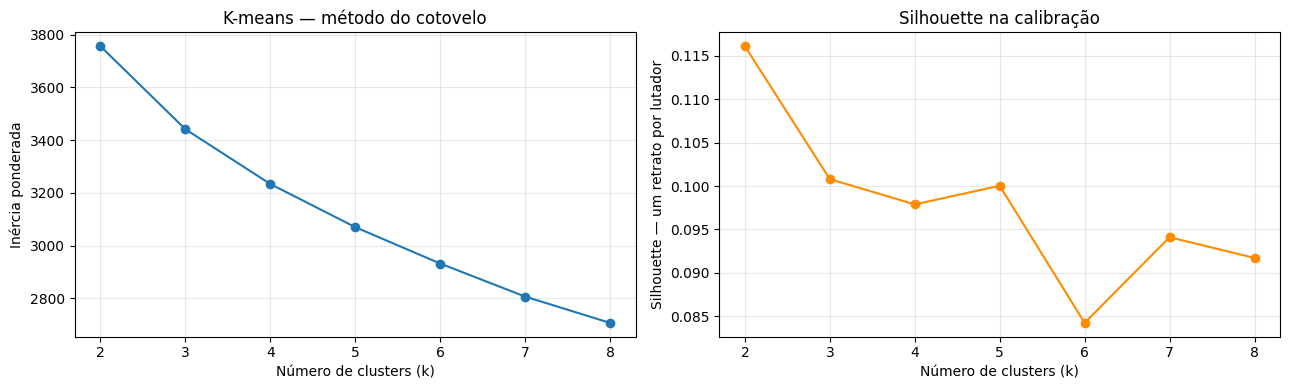

k sugerido para a etapa temporal: 2


In [347]:
dados_modelo = base_modelo.copy()

dados_modelo["fighter_id"] = (
    dados_modelo["fighter_id"].astype("string").str.strip()
)
dados_modelo["event_date"] = pd.to_datetime(
    dados_modelo["event_date"],
    errors="coerce",
).dt.normalize()

if dados_modelo[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError("Há fighter_id ou event_date ausente em base_modelo.")

# Ordenar garante que a calibração fique em ordem cronológica
dados_modelo = (
    dados_modelo
    .sort_values(["event_date", "fighter_id"])
    .reset_index(drop=True)
)

# Variáveis numéricas candidatas
features_numericas_candidatas = [
    *features_antes_disponiveis,
    "qtd_lutas_anteriores",
    "height_cm",
    "peso_kg",
    "reach_cm",
]

features_numericas_candidatas = [
    coluna for coluna in features_numericas_candidatas
    if coluna in dados_modelo.columns
]

# Sexo e categoria são codificados como variáveis categóricas
features_categoricas = [
    coluna for coluna in ["sexo", "categoria_luta"]
    if coluna in dados_modelo.columns
]

if not features_numericas_candidatas and not features_categoricas:
    raise ValueError("Não há variáveis disponíveis para o K-means.")


datas_disponiveis = np.sort(
    dados_modelo["event_date"].dropna().unique()
)

if len(datas_disponiveis) < 3:
    raise ValueError(
        "Há poucas datas elegíveis para calibrar e avaliar o modelo."
    )

# Primeiras 20% das datas elegíveis, não 20% de todas as linhas da base
qtd_datas_calibracao = math.ceil(len(datas_disponiveis) * 0.20)
qtd_datas_calibracao = max(2, qtd_datas_calibracao)
qtd_datas_calibracao = min(
    qtd_datas_calibracao,
    len(datas_disponiveis) - 1,
)

data_fim_calibracao = pd.Timestamp(
    datas_disponiveis[qtd_datas_calibracao - 1]
)

calibracao = dados_modelo.loc[
    dados_modelo["event_date"] <= data_fim_calibracao
].copy()

if calibracao.empty:
    raise ValueError("O período de calibração não contém observações.")

print("Fim da calibração:", data_fim_calibracao.date())
print("Dias elegíveis na calibração:", len(calibracao))
print("Lutadores na calibração:", calibracao["fighter_id"].nunique())

# Descarta variáveis numéricas sem valores observados na calibração
features_numericas = [
    coluna
    for coluna in features_numericas_candidatas
    if pd.to_numeric(
        calibracao[coluna],
        errors="coerce",
    ).notna().any()
]

features_sem_valor_inicial = [
    coluna
    for coluna in features_numericas_candidatas
    if coluna not in features_numericas
]

if features_sem_valor_inicial:
    print(
        "Variáveis numéricas excluídas por não terem valores "
        "na calibração:",
        features_sem_valor_inicial,
    )

X_calibracao_partes = []

if features_numericas:
    imputador = SimpleImputer(strategy="median")

    X_calibracao_numerico = imputador.fit_transform(
        calibracao[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )

    escalador = StandardScaler()
    X_calibracao_numerico = escalador.fit_transform(
        X_calibracao_numerico
    )

    X_calibracao_partes.append(X_calibracao_numerico)


categorias_por_coluna = {}

for coluna in features_categoricas:
    valores = (
        calibracao[coluna]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("indef")
    )

    niveis = sorted(valores.unique().tolist())

    if "__desconhecido__" not in niveis:
        niveis.append("__desconhecido__")

    categorias_por_coluna[coluna] = niveis


def codificar_categorias(df):
    partes = []

    for coluna in features_categoricas:
        if coluna in df.columns:
            valores = (
                df[coluna]
                .astype("string")
                .str.strip()
                .replace("", pd.NA)
                .fillna("indef")
            )
        else:
            valores = pd.Series(
                "indef",
                index=df.index,
                dtype="string",
            )

        niveis = categorias_por_coluna[coluna]
        niveis_conhecidos = [
            nivel for nivel in niveis
            if nivel != "__desconhecido__"
        ]

        valores = valores.where(
            valores.isin(niveis_conhecidos),
            "__desconhecido__",
        )

        categorico = pd.Series(
            pd.Categorical(valores, categories=niveis),
            index=df.index,
        )

        dummies = pd.get_dummies(
            categorico,
            prefix=coluna,
            dtype=float,
        )

        dummies = dummies.reindex(
            columns=[f"{coluna}_{nivel}" for nivel in niveis],
            fill_value=0,
        )

        partes.append(dummies.to_numpy(dtype=float))

    if not partes:
        return np.empty((len(df), 0))

    return np.column_stack(partes)


X_calibracao_categorico = codificar_categorias(calibracao)

if X_calibracao_categorico.shape[1] > 0:
    X_calibracao_partes.append(X_calibracao_categorico)

if not X_calibracao_partes:
    raise ValueError(
        "Não foi possível montar variáveis para o K-means."
    )

X_calibracao = np.column_stack(X_calibracao_partes)

contagem_por_lutador = calibracao["fighter_id"].value_counts()

pesos_calibracao = (
    1 / calibracao["fighter_id"].map(contagem_por_lutador)
).to_numpy(dtype=float)


mascara_representativas = ~calibracao["fighter_id"].duplicated(
    keep="last"
).to_numpy()

posicoes_representativas = np.flatnonzero(mascara_representativas)
X_representativo = X_calibracao[posicoes_representativas]

if len(X_representativo) < 4:
    raise ValueError(
        "Há menos de quatro lutadores na calibração para comparar valores de k."
    )


k_max = min(8, len(X_representativo) - 1)
resultados_k = []

for k in range(2, k_max + 1):
    modelo_teste = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    modelo_teste.fit(
        X_calibracao,
        sample_weight=pesos_calibracao,
    )

    rotulos_representativos = modelo_teste.predict(X_representativo)

    if len(np.unique(rotulos_representativos)) < 2:
        silhouette = np.nan
    else:
        silhouette = silhouette_score(
            X_representativo,
            rotulos_representativos,
            sample_size=min(3000, len(X_representativo)),
            random_state=42,
        )

    resultados_k.append({
        "k": k,
        "inercia_ponderada": modelo_teste.inertia_,
        "silhouette_1_lutador": silhouette,
    })

avaliacao_k_temporal = pd.DataFrame(resultados_k)

if avaliacao_k_temporal.empty:
    raise ValueError("Não foi possível avaliar nenhum valor de k.")

display(avaliacao_k_temporal.round(3))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].plot(
    avaliacao_k_temporal["k"],
    avaliacao_k_temporal["inercia_ponderada"],
    marker="o",
)
eixos[0].set_title("K-means — método do cotovelo")
eixos[0].set_xlabel("Número de clusters (k)")
eixos[0].set_ylabel("Inércia ponderada")
eixos[0].set_xticks(avaliacao_k_temporal["k"])
eixos[0].grid(alpha=0.3)

eixos[1].plot(
    avaliacao_k_temporal["k"],
    avaliacao_k_temporal["silhouette_1_lutador"],
    marker="o",
    color="darkorange",
)
eixos[1].set_title("Silhouette na calibração")
eixos[1].set_xlabel("Número de clusters (k)")
eixos[1].set_ylabel("Silhouette — um retrato por lutador")
eixos[1].set_xticks(avaliacao_k_temporal["k"])
eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Sugestão inicial pelo maior silhouette.
# Confira também o cotovelo e a interpretabilidade dos grupos.
avaliacao_valida = avaliacao_k_temporal.dropna(
    subset=["silhouette_1_lutador"]
)

if avaliacao_valida.empty:
    raise ValueError("Não foi possível calcular silhouette para nenhum k.")

k_sugerido = int(
    avaliacao_valida.loc[
        avaliacao_valida["silhouette_1_lutador"].idxmax(),
        "k",
    ]
)

k_escolhido = k_sugerido

print(f"k sugerido para a etapa temporal: {k_escolhido}")

In [348]:
if k_escolhido < 2:
    raise ValueError("k_escolhido precisa ser pelo menos 2.")

dados_modelo = base_modelo.copy()
dados_modelo["fighter_id"] = (
    dados_modelo["fighter_id"].astype("string").str.strip()
)
dados_modelo["event_date"] = pd.to_datetime(
    dados_modelo["event_date"],
    errors="coerce",
).dt.normalize()

if dados_modelo[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError("Há fighter_id ou event_date ausente em base_modelo.")

if dados_modelo.empty:
    raise ValueError("base_modelo está vazia.")

if len(dados_modelo) < k_escolhido:
    raise ValueError(
        "Há menos linhas elegíveis para modelagem do que clusters escolhidos."
    )

if X_calibracao.shape[0] != len(calibracao):
    raise ValueError(
        "O número de linhas de X_calibracao não corresponde a calibracao. "
        "Reexecute a célula de preparação e seleção de k."
    )

if len(pesos_calibracao) != len(calibracao):
    raise ValueError(
        "pesos_calibracao não corresponde ao número de linhas de calibracao."
    )

if calibracao["fighter_id"].nunique() < k_escolhido:
    raise ValueError(
        "A calibração contém menos lutadores únicos do que k_escolhido."
    )


modelo_temporal = KMeans(
    n_clusters=k_escolhido,
    random_state=42,
    n_init=20,
)

modelo_temporal.fit(
    X_calibracao,
    sample_weight=pesos_calibracao,
)

centros_alinhados = modelo_temporal.cluster_centers_.copy()


resultado_temporal = base_cluster_dia.copy()

resultado_temporal["fighter_id"] = (
    resultado_temporal["fighter_id"].astype("string").str.strip()
)
resultado_temporal["event_date"] = pd.to_datetime(
    resultado_temporal["event_date"],
    errors="coerce",
).dt.normalize()

if resultado_temporal[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em base_cluster_dia."
    )

if "historico_suficiente" not in resultado_temporal.columns:
    raise ValueError(
        "base_cluster_dia não contém historico_suficiente."
    )

if "historico_curto" not in resultado_temporal.columns:
    raise ValueError(
        "base_cluster_dia não contém historico_curto."
    )

if "sem_historico" not in resultado_temporal.columns:
    resultado_temporal["sem_historico"] = (
        pd.to_numeric(
            resultado_temporal["qtd_lutas_anteriores"],
            errors="coerce",
        ).eq(0)
    )

resultado_temporal["cluster_temporal"] = pd.Series(
    pd.NA,
    index=resultado_temporal.index,
    dtype="Int64",
)

# Estreantes e histórico curto compartilham o mesmo código.
inconclusivo = ~resultado_temporal["historico_suficiente"]

resultado_temporal.loc[
    inconclusivo,
    "cluster_temporal",
] = -2

# -1: sem histórico; -2: histórico curto.
resultado_temporal.loc[
    resultado_temporal["sem_historico"],
    "cluster_temporal",
] = -1

resultado_temporal.loc[
    resultado_temporal["historico_curto"],
    "cluster_temporal",
] = -2

# Dias elegíveis posteriores à calibração serão classificados temporalmente.
datas_para_classificar = sorted(
    resultado_temporal.loc[
        (resultado_temporal["event_date"] > data_fim_calibracao)
        & resultado_temporal["historico_suficiente"],
        "event_date",
    ].dropna().unique()
)

for data_atual in datas_para_classificar:
    data_atual = pd.Timestamp(data_atual)

    # Somente observações elegíveis em datas anteriores entram no ajuste.
    treino_passado = dados_modelo.loc[
        dados_modelo["event_date"] < data_atual
    ].copy()

    linhas_atual = resultado_temporal.index[
        resultado_temporal["event_date"].eq(data_atual)
        & resultado_temporal["historico_suficiente"]
    ]

    if len(linhas_atual) == 0:
        continue

    if (
        treino_passado["fighter_id"].nunique() < k_escolhido
        or len(treino_passado) < k_escolhido
    ):
        raise ValueError(
            f"Histórico anterior insuficiente para ajustar k={k_escolhido} "
            f"em {data_atual.date()}."
        )

    # Aplica imputação e escala ajustadas no período de calibração.
    X_treino_numerico = imputador.transform(
        treino_passado[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )
    X_treino_numerico = escalador.transform(X_treino_numerico)

    X_treino_categorico = codificar_categorias(treino_passado)

    X_treino = np.column_stack([
        X_treino_numerico,
        X_treino_categorico,
    ])

    # Cada lutador tem peso total 1 no ajuste, evitando que carreiras
    # com mais observações dominem apenas pelo número de linhas.
    contagem_por_lutador = treino_passado["fighter_id"].value_counts()

    pesos_passado = (
        1 / treino_passado["fighter_id"].map(contagem_por_lutador)
    ).to_numpy(dtype=float)

    # Reajusta o K-means usando somente o passado até a véspera do dia.
    modelo_atual = KMeans(
        n_clusters=k_escolhido,
        init=centros_alinhados,
        n_init=1,
        max_iter=100,
        random_state=42,
    )

    modelo_atual.fit(
        X_treino,
        sample_weight=pesos_passado,
    )

    # Alinha os rótulos novos aos centróides anteriores para reduzir
    # trocas arbitrárias entre Perfil 0, Perfil 1 etc.
    distancias = cdist(
        centros_alinhados,
        modelo_atual.cluster_centers_,
        metric="euclidean",
    )

    indices_anteriores, indices_atuais = linear_sum_assignment(distancias)

    mapa_rotulos = np.empty(k_escolhido, dtype=int)
    mapa_rotulos[indices_atuais] = indices_anteriores

    centros_novos_alinhados = np.empty_like(
        modelo_atual.cluster_centers_
    )
    centros_novos_alinhados[indices_anteriores] = (
        modelo_atual.cluster_centers_[indices_atuais]
    )

    # Transforma e classifica os retratos elegíveis deste dia.
    linhas_df = resultado_temporal.loc[linhas_atual]

    X_dia_numerico = imputador.transform(
        linhas_df[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )
    X_dia_numerico = escalador.transform(X_dia_numerico)

    X_dia_categorico = codificar_categorias(linhas_df)

    X_dia = np.column_stack([
        X_dia_numerico,
        X_dia_categorico,
    ])

    rotulos_brutos = modelo_atual.predict(X_dia)
    rotulos_alinhados = mapa_rotulos[rotulos_brutos]

    resultado_temporal.loc[
        linhas_atual,
        "cluster_temporal",
    ] = rotulos_alinhados

    centros_alinhados = centros_novos_alinhados


resultado_temporal["grupo_temporal"] = pd.Series(
    pd.NA,
    index=resultado_temporal.index,
    dtype="string",
)

# Estreantes + histórico curto em um grupo único
resultado_temporal.loc[
    inconclusivo,
    "grupo_temporal",
] = "Perfil inconclusivo"

# Linhas elegíveis usadas para iniciar os perfis
em_calibracao = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].le(data_fim_calibracao)
)

resultado_temporal.loc[
    em_calibracao,
    "grupo_temporal",
] = "Calibração - não classificado"

# Perfis atribuídos pelo K-means após a calibração
tem_perfil = resultado_temporal["cluster_temporal"].ge(0)

resultado_temporal.loc[
    tem_perfil,
    "grupo_temporal",
] = (
    "Perfil "
    + resultado_temporal.loc[tem_perfil, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# Dias elegíveis até a data final da calibração ficam sem perfil temporal.
em_calibracao = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].le(data_fim_calibracao)
)

resultado_temporal.loc[
    em_calibracao,
    "grupo_temporal",
] = "Calibração - não classificado"

# Não deixar dias elegíveis posteriores sem classificação silenciosamente.
sem_classificacao_depois = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].gt(data_fim_calibracao)
    & resultado_temporal["cluster_temporal"].isna()
)

if sem_classificacao_depois.any():
    exemplos = resultado_temporal.loc[
        sem_classificacao_depois,
        ["fighter_id", "event_date"],
    ].head(10)

    raise ValueError(
        "Há dias elegíveis posteriores à calibração sem cluster:\n"
        f"{exemplos.to_string(index=False)}"
    )


print("Fim da calibração:", data_fim_calibracao.date())
print("Total de dias lutador-data:", len(resultado_temporal))
print("Dias classificados em perfis técnicos:", int(tem_perfil.sum()))
print(
    "Lutadores que receberam perfil técnico:",
    resultado_temporal.loc[tem_perfil, "fighter_id"].nunique(),
)

print("Distribuição dos estados e perfis:")
display(
    resultado_temporal["grupo_temporal"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

display(
    resultado_temporal[
        [
            "fighter_id",
            "event_date",
            "qtd_lutas_anteriores",
            "tempo_historico_min_antes",
            "sem_historico",
            "historico_curto",
            "historico_suficiente",
            "cluster_temporal",
            "grupo_temporal",
        ]
    ].head(20)
)

Fim da calibração: 2010-09-15
Total de dias lutador-data: 17393
Dias classificados em perfis técnicos: 9252
Lutadores que receberam perfil técnico: 1427
Distribuição dos estados e perfis:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,sem_historico,historico_curto,historico_suficiente,cluster_temporal,grupo_temporal
0,001eb2ab0f30e7ea,2025-06-07,0,0.000000,True,False,False,-1,Perfil inconclusivo
1,002ca196477ce572,2019-07-20,0,0.000000,True,False,False,-1,Perfil inconclusivo
2,002ca196477ce572,2020-02-29,1,15.000000,False,True,False,-2,Perfil inconclusivo
3,003d82fa384ca1d0,2020-02-29,0,0.000000,True,False,False,-1,Perfil inconclusivo
4,003d82fa384ca1d0,2021-03-06,1,1.416667,False,True,False,-2,Perfil inconclusivo
5,0052de90691d4a93,2017-03-11,0,0.000000,True,False,False,-1,Perfil inconclusivo
6,0052de90691d4a93,2017-12-09,1,15.000000,False,True,False,-2,Perfil inconclusivo
7,0052de90691d4a93,2018-05-12,2,25.833333,False,True,False,-2,Perfil inconclusivo
8,0052de90691d4a93,2018-11-10,3,30.083333,False,False,True,1,Perfil 1
9,0052de90691d4a93,2019-05-18,4,32.033333,False,False,True,1,Perfil 1


In [349]:
print("Total de linhas:", len(resultado_temporal))

print("Linhas sem cluster por situação:")
display(
    resultado_temporal
    .groupby("grupo_temporal")
    .agg(
        linhas=("fighter_id", "size"),
        lutadores=("fighter_id", "nunique"),
        primeira_data=("event_date", "min"),
        ultima_data=("event_date", "max"),
    )
)

print("Linhas sem cluster após o fim da calibração:")
display(
    resultado_temporal.loc[
        resultado_temporal["cluster_temporal"].isna()
        & (resultado_temporal["event_date"] > data_fim_calibracao),
        [
            "fighter_id",
            "event_date",
            "qtd_lutas_anteriores",
            "tempo_historico_min_antes",
            "historico_suficiente",
        ],
    ].head(20)
)

Total de linhas: 17393
Linhas sem cluster por situação:


,linhas,lutadores,primeira_data,ultima_data
grupo_temporal,,,,
Calibração - não classificado,1163,246,1995-04-07,2010-09-15
Perfil 0,4239,666,2010-09-25,2026-06-27
Perfil 1,5013,917,2010-09-25,2026-06-27
Perfil inconclusivo,6978,2693,1994-03-11,2026-06-27


Linhas sem cluster após o fim da calibração:


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,historico_suficiente


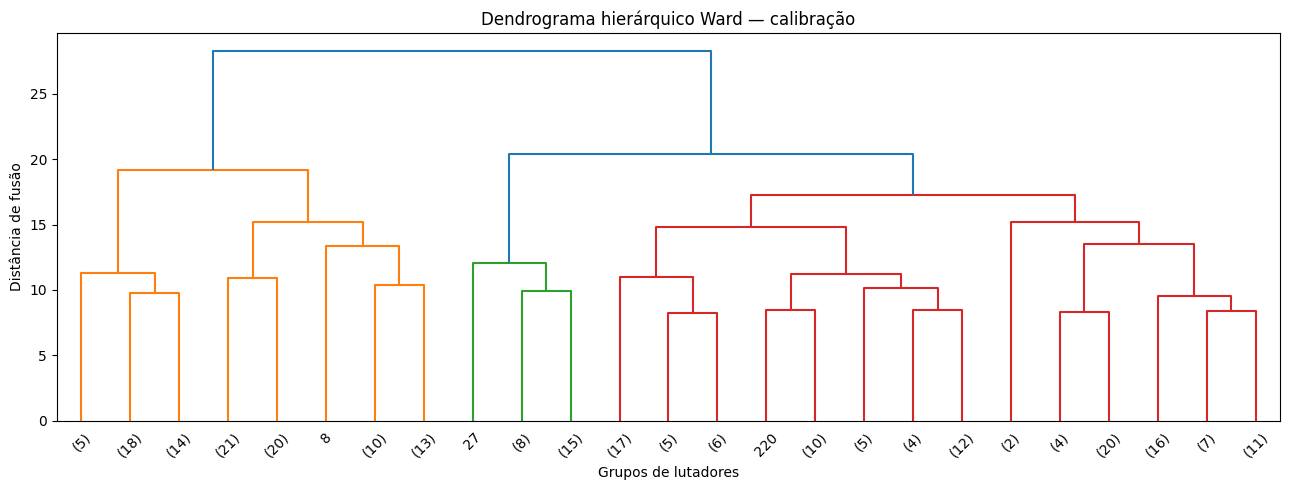

,k,silhouette
0,2,0.098
1,3,0.085
2,4,0.067
3,5,0.067
4,6,0.060
5,7,0.064
6,8,0.070


Grupos hierárquicos na calibração, com k=2:


,lutadores
grupo,
Perfil 0,144
Perfil 1,102


,fighter_id,event_date,cluster_hierarquico,grupo_hierarquico
0,1dc56b59cb28425d,1995-12-16,0,Perfil 0
1,07a18ae55dfc3cd9,1996-12-07,0,Perfil 0
2,271fe91f4ba9d2c5,1996-12-07,0,Perfil 0
3,1c3f5e85b59ec710,1997-07-27,0,Perfil 0
4,93892752c5fc23ca,1999-01-08,0,Perfil 0


In [350]:
posicoes = np.flatnonzero(
    ~calibracao["fighter_id"].duplicated(keep="last").to_numpy()
)

X_hierarquico = X_calibracao[posicoes]
calibracao_hierarquica = (
    calibracao.iloc[posicoes]
    .reset_index(drop=True)
    .copy()
)

if len(X_hierarquico) <= k_escolhido:
    raise ValueError(
        "Há poucos lutadores únicos na calibração para avaliar esse k."
    )

# Hierárquico Ward aplicado aos perfis da calibração
arvore = linkage(X_hierarquico, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(
    arvore,
    truncate_mode="lastp",
    p=25,
    show_leaf_counts=True,
)
plt.title("Dendrograma hierárquico Ward — calibração")
plt.xlabel("Grupos de lutadores")
plt.ylabel("Distância de fusão")
plt.tight_layout()
plt.show()

# Compara silhouette para diferentes números de clusters
resultados_hierarquico = []
k_max_hierarquico = min(8, len(X_hierarquico) - 1)

for k in range(2, k_max_hierarquico + 1):
    rotulos = cut_tree(arvore, n_clusters=k).ravel()

    resultados_hierarquico.append({
        "k": k,
        "silhouette": silhouette_score(
            X_hierarquico,
            rotulos,
            sample_size=min(3000, len(X_hierarquico)),
            random_state=42,
        ),
    })

avaliacao_hierarquico = pd.DataFrame(resultados_hierarquico)
display(avaliacao_hierarquico.round(3))

# Compara o resultado hierárquico com o k escolhido para o K-means
rotulos_hierarquicos_calibracao = cut_tree(
    arvore,
    n_clusters=k_escolhido,
).ravel()

resultado_hierarquico_calibracao = calibracao_hierarquica[
    ["fighter_id", "event_date"]
].copy()

resultado_hierarquico_calibracao["cluster_hierarquico"] = (
    rotulos_hierarquicos_calibracao
)
resultado_hierarquico_calibracao["grupo_hierarquico"] = (
    "Perfil "
    + resultado_hierarquico_calibracao["cluster_hierarquico"].astype(str)
)

print(f"Grupos hierárquicos na calibração, com k={k_escolhido}:")
display(
    resultado_hierarquico_calibracao["grupo_hierarquico"]
    .value_counts()
    .rename_axis("grupo")
    .to_frame("lutadores")
)

display(resultado_hierarquico_calibracao.head())

In [351]:
rotulos_kmeans_calibracao = modelo_temporal.predict(X_hierarquico)

print("Comparação dos agrupamentos na calibração:")
display(
    pd.crosstab(
        pd.Series(rotulos_hierarquicos_calibracao, name="Hierárquico"),
        pd.Series(rotulos_kmeans_calibracao, name="K-means"),
        normalize="index",
    ).round(3)
)

Comparação dos agrupamentos na calibração:


K-means,0,1
Hierárquico,,
0,0.875,0.125
1,0.206,0.794


Variância explicada pelas duas componentes: 34.6%


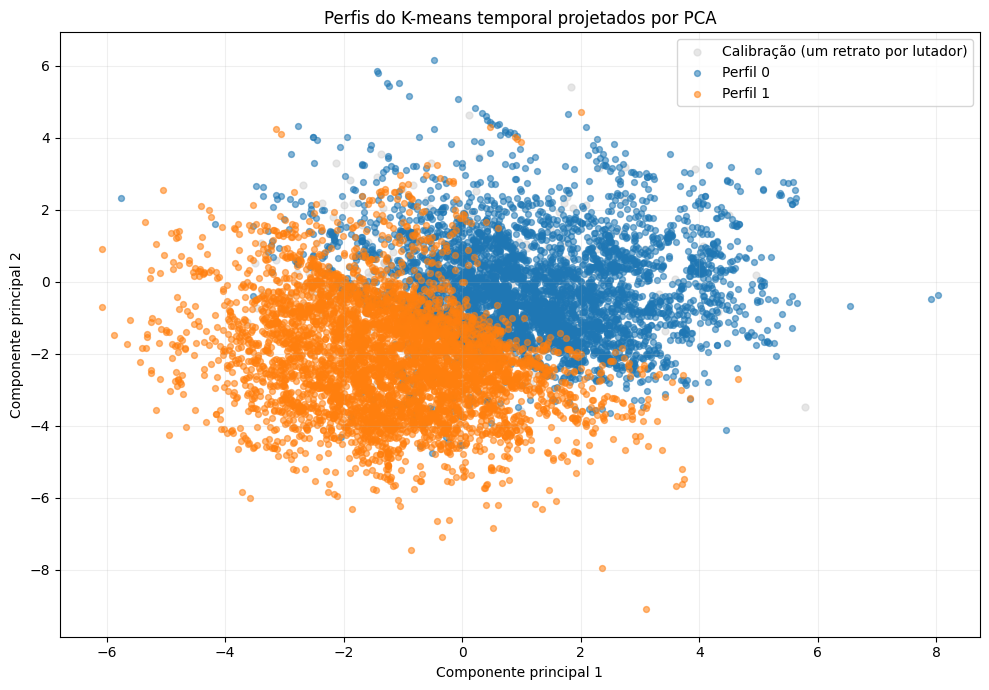

In [352]:

posicoes_calibracao = np.flatnonzero(
    ~calibracao["fighter_id"]
    .duplicated(keep="last")
    .to_numpy()
)

X_calibracao_pca = X_calibracao[posicoes_calibracao]

if min(X_calibracao_pca.shape) < 2:
    raise ValueError(
        "São necessárias pelo menos duas observações e duas variáveis "
        "para projetar os dados em duas componentes."
    )
 
pca = PCA(n_components=2)
pca.fit(X_calibracao_pca)
 
linhas_plot = resultado_temporal.loc[
    resultado_temporal["cluster_temporal"].notna()
    & resultado_temporal["cluster_temporal"].ge(0)
].copy()

if linhas_plot.empty:
    raise ValueError(
        "Não há linhas pós-calibração com perfil técnico para plotar."
    )
 
X_plot_numerico = imputador.transform(
    linhas_plot[features_numericas].apply(
        pd.to_numeric,
        errors="coerce",
    )
)
X_plot_numerico = escalador.transform(X_plot_numerico)

X_plot_categorico = codificar_categorias(linhas_plot)

X_plot = np.column_stack([
    X_plot_numerico,
    X_plot_categorico,
])

if X_plot.shape[1] != X_calibracao.shape[1]:
    raise ValueError(
        "A matriz dos dados posteriores não tem o mesmo número de "
        "variáveis da calibração."
    )

coordenadas_plot = pca.transform(X_plot)
coordenadas_calibracao = pca.transform(X_calibracao_pca)

print(
    "Variância explicada pelas duas componentes:",
    f"{pca.explained_variance_ratio_.sum():.1%}",
)

# Mostra a calibração como referência neutra e os perfis posteriores
# com cores distintas.
plt.figure(figsize=(10, 7))

plt.scatter(
    coordenadas_calibracao[:, 0],
    coordenadas_calibracao[:, 1],
    color="lightgray",
    alpha=0.55,
    s=24,
    label="Calibração (um retrato por lutador)",
)

rotulos_presentes = sorted(
    linhas_plot["cluster_temporal"].astype(int).unique()
)

for rotulo in rotulos_presentes:
    mascara = linhas_plot["cluster_temporal"].astype(int).eq(rotulo)

    plt.scatter(
        coordenadas_plot[mascara.to_numpy(), 0],
        coordenadas_plot[mascara.to_numpy(), 1],
        alpha=0.55,
        s=18,
        label=f"Perfil {rotulo}",
    )

plt.title("Perfis do K-means temporal projetados por PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

### Resultado da clusterização temporal

A expectativa inicial era identificar diferentes perfis estratégicos a partir do histórico dos lutadores. Com as variáveis, os critérios de elegibilidade e o método utilizados nesta análise, foram identificados dois perfis técnicos. Os rótulos abaixo são interpretações provisórias e devem ser entendidos junto às métricas que caracterizam cada grupo.

- **Perfil inconclusivo:** observações de estreantes ou de lutadores que ainda não atingiram o mínimo definido para atribuição de um perfil técnico — pelo menos 3 lutas anteriores e 15 minutos acumulados de combate.
- **Perfil 0 — possível predominância de trocação (interpretação provisória):** hipótese a ser sustentada pelas métricas técnicas do grupo.
- **Perfil 1 — possível predominância de grappling (interpretação provisória):** hipótese a ser sustentada pelas métricas técnicas do grupo.
- **Calibração — sem perfil atribuído:** período inicial usado para estabelecer os perfis de referência. Essas observações não são um cluster técnico e não entram na análise de transições temporais.

Na execução atual, a base contém 17.393 observações lutador-data: 4.239 classificadas como Perfil 0, 5.013 como Perfil 1, 6.978 como inconclusivas e 1.163 no período de calibração. Assim, a calibração representa aproximadamente 6,7% das observações, não 6% dos lutadores únicos.

Os perfis são atribuídos ao longo do tempo com base nas informações disponíveis antes de cada data. As transições indicam mudanças de atribuição entre os perfis do modelo; por si só, não comprovam uma mudança definitiva de estratégia do lutador.

In [353]:
# 1. Preparar os rótulos temporais por lutador e dia
# ------------------------------------------------------------

colunas_resultado = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
    "grupo_temporal",
]

faltando = [
    coluna for coluna in colunas_resultado
    if coluna not in resultado_temporal.columns
]
if faltando:
    raise ValueError(
        f"Colunas ausentes em resultado_temporal: {faltando}"
    )

rotulos_dia = resultado_temporal[colunas_resultado].copy()

rotulos_dia["fighter_id"] = (
    rotulos_dia["fighter_id"].astype("string").str.strip()
)
rotulos_dia["event_date"] = pd.to_datetime(
    rotulos_dia["event_date"],
    errors="coerce",
).dt.normalize()
rotulos_dia["cluster_temporal"] = pd.to_numeric(
    rotulos_dia["cluster_temporal"],
    errors="coerce",
).astype("Int64")

if rotulos_dia[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em resultado_temporal."
    )

if rotulos_dia.duplicated(["fighter_id", "event_date"]).any():
    raise ValueError(
        "resultado_temporal precisa ter uma linha por fighter_id e data."
    )

# Unifica estreantes (-1) e histórico curto (-2) num único estado.
# Os dois são situações sem perfil técnico disponível.
inconclusivo = rotulos_dia["cluster_temporal"].isin([-1, -2])

rotulos_dia.loc[inconclusivo, "cluster_temporal"] = -2
rotulos_dia.loc[inconclusivo, "grupo_temporal"] = "Perfil inconclusivo"

# Confere se há dias elegíveis posteriores à calibração sem cluster.
# Os estados inconclusivos já foram tratados; cluster nulo restante
# representa a calibração ou uma linha que precisa ser investigada.
if "historico_suficiente" in resultado_temporal.columns:
    suficiente = resultado_temporal["historico_suficiente"].to_numpy()
    depois_calibracao = (
        pd.to_datetime(
            resultado_temporal["event_date"],
            errors="coerce",
        ).dt.normalize()
        > data_fim_calibracao
    ).to_numpy()

    sem_cluster_pos_calibracao = (
        suficiente
        & depois_calibracao
        & rotulos_dia["cluster_temporal"].isna().to_numpy()
    )

    if sem_cluster_pos_calibracao.any():
        raise ValueError(
            "Há dias com histórico suficiente após a calibração, "
            "mas sem cluster atribuído."
        )

# Cluster técnico não nulo deve ter rótulo Perfil N
tem_cluster_tecnico = rotulos_dia["cluster_temporal"].ge(0)
rotulos_dia.loc[tem_cluster_tecnico, "grupo_temporal"] = (
    "Perfil "
    + rotulos_dia.loc[tem_cluster_tecnico, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# ------------------------------------------------------------
# 2. Calcular transições por lutador-dia
# ------------------------------------------------------------

rotulos_dia = rotulos_dia.sort_values(
    ["fighter_id", "event_date"]
).reset_index(drop=True)

# Estado do dia anterior do mesmo lutador:
# >= 0 = perfil técnico; -2 = inconclusivo; nulo = calibração/sem observação.
rotulos_dia["cluster_anterior"] = (
    rotulos_dia.groupby("fighter_id")["cluster_temporal"]
    .shift(1)
    .astype("Int64")
)

rotulos_dia["grupo_anterior"] = (
    rotulos_dia.groupby("fighter_id")["grupo_temporal"]
    .shift(1)
    .astype("string")
)

cluster_atual = rotulos_dia["cluster_temporal"]
cluster_anterior = rotulos_dia["cluster_anterior"]

# Mudança de perfil significa mudança entre dois perfis técnicos.
rotulos_dia["alterou_perfil_desde_ultima"] = (
    cluster_atual.ge(0)
    & cluster_anterior.ge(0)
    & cluster_atual.ne(cluster_anterior)
).fillna(False)

# Entrada em um perfil técnico depois de uma observação inconclusiva.
rotulos_dia["entrou_em_perfil_tecnico"] = (
    cluster_atual.ge(0)
    & cluster_anterior.eq(-2)
).fillna(False)

# Contagem acumulada de mudanças técnicas, incluindo o dia atual.
rotulos_dia["qtd_transicoes_ate_dia"] = (
    rotulos_dia.groupby("fighter_id")[
        "alterou_perfil_desde_ultima"
    ].cumsum()
)

rotulos_dia["houve_transicao_ate_dia"] = (
    rotulos_dia["qtd_transicoes_ate_dia"] > 0
)

# Também cria uma descrição legível da passagem entre estados.
rotulos_dia["transicao_desde_ultima"] = "sem mudança entre perfis"

primeira_observacao = rotulos_dia["cluster_anterior"].isna()
rotulos_dia.loc[
    primeira_observacao,
    "transicao_desde_ultima",
] = "primeira observação"

mudou = rotulos_dia["alterou_perfil_desde_ultima"]
rotulos_dia.loc[mudou, "transicao_desde_ultima"] = (
    rotulos_dia.loc[mudou, "grupo_anterior"]
    + " -> "
    + rotulos_dia.loc[mudou, "grupo_temporal"]
)

entrou = rotulos_dia["entrou_em_perfil_tecnico"]
rotulos_dia.loc[entrou, "transicao_desde_ultima"] = (
    "Perfil inconclusivo -> "
    + rotulos_dia.loc[entrou, "grupo_temporal"]
)

# ------------------------------------------------------------
# 3. Levar os rótulos diários para cada linha de gold_hist
# ------------------------------------------------------------

historico = gold_hist.copy()

historico["fighter_id"] = (
    historico["fighter_id"].astype("string").str.strip()
)
historico["_event_date_dia"] = pd.to_datetime(
    historico["event_date"],
    errors="coerce",
).dt.normalize()

if historico[["fighter_id", "_event_date_dia"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em gold_hist."
    )

colunas_transicao = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
    "grupo_temporal",
    "cluster_anterior",
    "grupo_anterior",
    "alterou_perfil_desde_ultima",
    "entrou_em_perfil_tecnico",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
    "transicao_desde_ultima",
]

mapa_transicoes = rotulos_dia[colunas_transicao].rename(
    columns={"event_date": "_event_date_dia"}
)

gold_hist_clusterizado = historico.merge(
    mapa_transicoes,
    on=["fighter_id", "_event_date_dia"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

sem_correspondencia = gold_hist_clusterizado["_merge"].ne("both")
if sem_correspondencia.any():
    exemplos = gold_hist_clusterizado.loc[
        sem_correspondencia,
        ["fighter_id", "_event_date_dia"],
    ].head(10)

    raise ValueError(
        "Algumas linhas de gold_hist não encontraram rótulo temporal:\n"
        f"{exemplos.to_string(index=False)}"
    )

gold_hist_clusterizado = gold_hist_clusterizado.drop(
    columns=["_event_date_dia", "_merge"]
)

# ------------------------------------------------------------
# 4. Conferir distribuição e transições
# ------------------------------------------------------------

print("Linhas originais:", len(gold_hist))
print("Linhas com rótulo temporal:", len(gold_hist_clusterizado))
print("\nDistribuição por estado/perfil:")
display(
    rotulos_dia["grupo_temporal"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

print("\nLutadores únicos por estado/perfil (podem aparecer em vários):")
display(
    rotulos_dia.groupby("grupo_temporal", dropna=False)["fighter_id"]
    .nunique()
    .rename("lutadores")
    .to_frame()
)

print("\nTransições entre perfis técnicos:")
display(
    rotulos_dia.loc[rotulos_dia["alterou_perfil_desde_ultima"]]
    .groupby(["grupo_anterior", "grupo_temporal"])
    .size()
    .rename("quantidade")
    .reset_index()
)

print("\nExemplo da base final:")
display(
    gold_hist_clusterizado[
        [
            "fighter_id",
            "event_date",
            "cluster_temporal",
            "grupo_temporal",
            "cluster_anterior",
            "alterou_perfil_desde_ultima",
            "houve_transicao_ate_dia",
            "transicao_desde_ultima",
        ]
    ].head(20)
)

Linhas originais: 17472
Linhas com rótulo temporal: 17472

Distribuição por estado/perfil:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163



Lutadores únicos por estado/perfil (podem aparecer em vários):


,lutadores
grupo_temporal,
Calibração - não classificado,246
Perfil 0,666
Perfil 1,917
Perfil inconclusivo,2693



Transições entre perfis técnicos:


,grupo_anterior,grupo_temporal,quantidade
0,Perfil 0,Perfil 1,78
1,Perfil 1,Perfil 0,127



Exemplo da base final:


,fighter_id,event_date,cluster_temporal,grupo_temporal,cluster_anterior,alterou_perfil_desde_ultima,houve_transicao_ate_dia,transicao_desde_ultima
0,95aff2fd8d09a5f0,2026-06-27,-2,Perfil inconclusivo,-2,False,False,sem mudança entre perfis
1,36b8f265bcd1b7a4,2026-06-27,0,Perfil 0,0,False,False,sem mudança entre perfis
2,8d3273573b85be09,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
3,a4dc0f2b95df4cc1,2026-06-27,1,Perfil 1,-2,False,False,Perfil inconclusivo -> Perfil 1
4,70dd69b6a703257e,2026-06-27,-2,Perfil inconclusivo,-2,False,False,sem mudança entre perfis
5,c88f8a9c1ea7165d,2026-06-27,-2,Perfil inconclusivo,<NA>,False,False,primeira observação
6,b07aed698fba8624,2026-06-27,0,Perfil 0,-2,False,False,Perfil inconclusivo -> Perfil 0
7,7facc9c45d792985,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
8,ff62013d2fce6d13,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
9,49d2a08964c5eb11,2026-06-27,0,Perfil 0,0,False,False,sem mudança entre perfis


In [354]:

# ------------------------------------------------------------
# 1. Preparar os rótulos temporais, uma linha por lutador-dia
# ------------------------------------------------------------

colunas_rotulos = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
]

faltando = [
    coluna for coluna in colunas_rotulos
    if coluna not in resultado_temporal.columns
]
if faltando:
    raise ValueError(
        f"Colunas ausentes em resultado_temporal: {faltando}"
    )

rotulos_dia = resultado_temporal.copy()

rotulos_dia["fighter_id"] = (
    rotulos_dia["fighter_id"].astype("string").str.strip()
)
rotulos_dia["event_date"] = pd.to_datetime(
    rotulos_dia["event_date"],
    errors="coerce",
).dt.normalize()
rotulos_dia["cluster_temporal"] = pd.to_numeric(
    rotulos_dia["cluster_temporal"],
    errors="coerce",
).astype("Int64")

if rotulos_dia[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em resultado_temporal."
    )

if rotulos_dia.duplicated(["fighter_id", "event_date"]).any():
    raise ValueError(
        "resultado_temporal deve ter apenas uma linha por lutador e dia."
    )

# Une estreantes (-1) e histórico curto (-2) num estado único.
rotulos_dia.loc[
    rotulos_dia["cluster_temporal"].isin([-1, -2]),
    "cluster_temporal",
] = -2

# Define os rótulos finais a partir do código do cluster.
rotulos_dia["grupo"] = pd.Series(
    pd.NA,
    index=rotulos_dia.index,
    dtype="string",
)

inconclusivo = rotulos_dia["cluster_temporal"].eq(-2)
rotulos_dia.loc[inconclusivo, "grupo"] = "Perfil inconclusivo"

tem_cluster_tecnico = rotulos_dia["cluster_temporal"].ge(0)
rotulos_dia.loc[tem_cluster_tecnico, "grupo"] = (
    "Perfil "
    + rotulos_dia.loc[tem_cluster_tecnico, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# Cluster nulo representa calibração, conforme o resultado temporal.
sem_cluster = rotulos_dia["cluster_temporal"].isna()
rotulos_dia.loc[
    sem_cluster,
    "grupo",
] = "Calibração - não classificado"

# Se houver a flag, garante que não estamos escondendo linhas elegíveis
# posteriores à calibração sem classificação.
if "historico_suficiente" in rotulos_dia.columns:
    datas = rotulos_dia["event_date"]

    elegivel_sem_cluster_pos_calibracao = (
        rotulos_dia["historico_suficiente"].fillna(False)
        & sem_cluster
        & (datas > data_fim_calibracao)
    )

    if elegivel_sem_cluster_pos_calibracao.any():
        exemplos = rotulos_dia.loc[
            elegivel_sem_cluster_pos_calibracao,
            ["fighter_id", "event_date"],
        ].head(10)

        raise ValueError(
            "Há observações elegíveis após a calibração sem cluster:\n"
            f"{exemplos.to_string(index=False)}"
        )


# ------------------------------------------------------------
# 2. Comparar apenas perfis técnicos consecutivos
# ------------------------------------------------------------

# A sequência de transições considera somente dias com Perfil 0, Perfil 1...
# Portanto, ignora Perfil inconclusivo e calibração entre dois perfis técnicos.
historico_tecnico = (
    rotulos_dia.loc[rotulos_dia["cluster_temporal"].ge(0)]
    .sort_values(["fighter_id", "event_date"])
    .copy()
)

historico_tecnico["cluster_anterior_tecnico"] = (
    historico_tecnico.groupby("fighter_id")["cluster_temporal"]
    .shift(1)
    .astype("Int64")
)

historico_tecnico["mudou_perfil_tecnico"] = (
    historico_tecnico["cluster_anterior_tecnico"].notna()
    & historico_tecnico["cluster_temporal"].ne(
        historico_tecnico["cluster_anterior_tecnico"]
    )
)

historico_tecnico["transicao_perfil_tecnico"] = pd.Series(
    "Manteve perfil técnico",
    index=historico_tecnico.index,
    dtype="string",
)

mudou = historico_tecnico["mudou_perfil_tecnico"]

historico_tecnico.loc[mudou, "transicao_perfil_tecnico"] = (
    "Perfil "
    + historico_tecnico.loc[
        mudou, "cluster_anterior_tecnico"
    ].astype(int).astype(str)
    + " -> Perfil "
    + historico_tecnico.loc[
        mudou, "cluster_temporal"
    ].astype(int).astype(str)
)

historico_tecnico["qtd_transicoes_tecnicas_ate_dia"] = (
    historico_tecnico.groupby("fighter_id")[
        "mudou_perfil_tecnico"
    ].cumsum()
)

# Tabela diária de transições para juntar tanto às linhas técnicas
# quanto às demais linhas daquele mesmo lutador-dia.
colunas_transicoes = [
    "fighter_id",
    "event_date",
    "cluster_anterior_tecnico",
    "mudou_perfil_tecnico",
    "transicao_perfil_tecnico",
    "qtd_transicoes_tecnicas_ate_dia",
]

transicoes_dia = historico_tecnico[colunas_transicoes].copy()


# ------------------------------------------------------------
# 3. Construir gold_hist_clusterizado
# ------------------------------------------------------------

gold_hist_clusterizado = gold_hist.copy()

gold_hist_clusterizado["fighter_id"] = (
    gold_hist_clusterizado["fighter_id"]
    .astype("string")
    .str.strip()
)
gold_hist_clusterizado["event_date"] = pd.to_datetime(
    gold_hist_clusterizado["event_date"],
    errors="coerce",
).dt.normalize()

if gold_hist_clusterizado[
    ["fighter_id", "event_date"]
].isna().any().any():
    raise ValueError("gold_hist contém fighter_id ou event_date ausente.")

# Prepara os rótulos que serão anexados às lutas.
rotulos_para_merge = rotulos_dia[
    ["fighter_id", "event_date", "cluster_temporal", "grupo"]
].rename(columns={
    "cluster_temporal": "cluster",
})

gold_hist_clusterizado = gold_hist_clusterizado.merge(
    rotulos_para_merge,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
    indicator="_merge_cluster",
)

sem_rotulo = gold_hist_clusterizado["_merge_cluster"].ne("both")

if sem_rotulo.any():
    exemplos = gold_hist_clusterizado.loc[
        sem_rotulo,
        ["fighter_id", "event_date"],
    ].head(10)

    raise ValueError(
        "Algumas linhas de gold_hist não encontraram cluster por "
        "fighter_id e event_date:\n"
        f"{exemplos.to_string(index=False)}"
    )

gold_hist_clusterizado = gold_hist_clusterizado.drop(
    columns="_merge_cluster"
)

# Anexa a informação de transição do dia.
gold_hist_clusterizado = gold_hist_clusterizado.merge(
    transicoes_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
)

# Para linhas sem perfil técnico nesse dia, não ocorreu uma transição
# técnica naquela linha. O cluster anterior técnico fica ausente.
gold_hist_clusterizado["mudou_perfil_tecnico"] = (
    gold_hist_clusterizado["mudou_perfil_tecnico"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# 4. Resumir transições por lutador
# ------------------------------------------------------------

resumo_transicoes = (
    historico_tecnico.groupby("fighter_id")
    .agg(
        dias_com_perfil_tecnico=("cluster_temporal", "size"),
        perfis_tecnicos_visitados=(
            "cluster_temporal",
            lambda valores: sorted(
                valores.dropna().astype(int).unique()
            ),
        ),
        quantidade_transicoes=("mudou_perfil_tecnico", "sum"),
    )
    .reset_index()
)

resumo_transicoes["transitou_entre_perfis"] = (
    resumo_transicoes["perfis_tecnicos_visitados"].str.len() > 1
)

# Acrescenta os nomes, se disponíveis.
if "fighter_name" in gold_fighter.columns:
    cadastro_nomes = gold_fighter[
        ["fighter_id", "fighter_name"]
    ].copy()

    cadastro_nomes["fighter_id"] = (
        cadastro_nomes["fighter_id"].astype("string").str.strip()
    )

    if cadastro_nomes["fighter_id"].duplicated().any():
        raise ValueError("gold_fighter tem fighter_id duplicado.")

    resumo_transicoes = resumo_transicoes.merge(
        cadastro_nomes,
        on="fighter_id",
        how="left",
        validate="one_to_one",
    )


# ------------------------------------------------------------
# 5. Conferir distribuição e transições
# ------------------------------------------------------------

print("Distribuição por estado/perfil:")
display(
    rotulos_dia["grupo"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

print("Resumo de transições entre perfis técnicos:")
display(
    resumo_transicoes["transitou_entre_perfis"]
    .value_counts()
    .rename(index={
        False: "Não transitou entre perfis técnicos",
        True: "Transitou entre perfis técnicos",
    })
    .to_frame("lutadores")
)

print("Lutadores que transitaram entre perfis técnicos:")
display(
    resumo_transicoes.loc[
        resumo_transicoes["transitou_entre_perfis"]
    ]
    .sort_values(
        ["quantidade_transicoes", "fighter_id"],
        ascending=[False, True],
    )
    .head(30)
)

print("Transições observadas:")
display(
    historico_tecnico.loc[historico_tecnico["mudou_perfil_tecnico"]]
    .groupby([
        "cluster_anterior_tecnico",
        "cluster_temporal",
    ])
    .size()
    .rename("quantidade")
    .reset_index()
)

print("Exemplo da base com cluster e transição por luta:")
display(
    gold_hist_clusterizado[
        [
            "fighter_id",
            "event_date",
            "cluster",
            "grupo",
            "cluster_anterior_tecnico",
            "mudou_perfil_tecnico",
            "transicao_perfil_tecnico",
            "qtd_transicoes_tecnicas_ate_dia",
        ]
    ].head(20)
)

Distribuição por estado/perfil:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163


Resumo de transições entre perfis técnicos:


,lutadores
transitou_entre_perfis,
Não transitou entre perfis técnicos,1271
Transitou entre perfis técnicos,156


Lutadores que transitaram entre perfis técnicos:


,fighter_id,dias_com_perfil_tecnico,perfis_tecnicos_visitados,quantidade_transicoes,transitou_entre_perfis,fighter_name
314,396fe87b84ac2e1c,8,"[0, 1]",5,True,Lerone Murphy
672,7aa3d6964eff4877,27,"[0, 1]",4,True,Alex Caceres
198,275aca31f61ba28c,15,"[0, 1]",3,True,Islam Makhachev
212,29af297d9f1de0f8,11,"[0, 1]",3,True,Damon Jackson
448,523fa774700d7d3f,21,"[0, 1]",3,True,Court McGee
546,64facb6cc564262d,8,"[0, 1]",3,True,Punahele Soriano
875,9cdd2da1a9104a0b,11,"[0, 1]",3,True,Macy Chiasson
907,a26198ba5093147e,7,"[0, 1]",3,True,TJ Grant
936,a8283a4f415e1eb9,23,"[0, 1]",3,True,Francisco Trinaldo
1287,e64b96c07d7ce999,15,"[0, 1]",3,True,Li Jingliang


Transições observadas:


,cluster_anterior_tecnico,cluster_temporal,quantidade
0,0,1,78
1,1,0,127


Exemplo da base com cluster e transição por luta:


,fighter_id,event_date,cluster,grupo,cluster_anterior_tecnico,mudou_perfil_tecnico,transicao_perfil_tecnico,qtd_transicoes_tecnicas_ate_dia
0,95aff2fd8d09a5f0,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
1,36b8f265bcd1b7a4,2026-06-27,0,Perfil 0,0,False,Manteve perfil técnico,0
2,8d3273573b85be09,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
3,a4dc0f2b95df4cc1,2026-06-27,1,Perfil 1,<NA>,False,Manteve perfil técnico,0
4,70dd69b6a703257e,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
5,c88f8a9c1ea7165d,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
6,b07aed698fba8624,2026-06-27,0,Perfil 0,<NA>,False,Manteve perfil técnico,0
7,7facc9c45d792985,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
8,ff62013d2fce6d13,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
9,49d2a08964c5eb11,2026-06-27,0,Perfil 0,0,False,Manteve perfil técnico,0


####
Interessante com esse resultado é ver alguns lutadores que já foram campeões da sua categoria, mostrando que as vezes essa transição de estilos faz sentido para chegar ao topo.

Lutadores como: Edson Barboza, Belal Muhaammad, Charles Oliveira, Diego Lopes

#### Conclusão clusterização.

O objetivo inicial era:
- Identificar perfis distintos a partir do desempenho de lutas históricas do lutador. 

Resultado:

Clusterização concluida e atualmente temos 2 grupos técnicos definidos e 1 grupo de lutadores inconclusivos (que não obtiveram minimo de lutas para detectar um estilo ou estreantes).


### Clusterização a partir da primeira luta de todos os lutadores

In [355]:
# Colunas de desempenho disponíveis em gold_hist
colunas_luta = [
    "fighter_id",
    "fight_id_hist",
    "event_date",
    "tempo_luta_segundos",
    "result",  # preservada para análise, não será variável do cluster
    "kd",
    "sig_str_landed",
    "sig_str_attempted",
    "td_landed",
    "td_attempted",
    "sub_att",
    "rev",
    "ctrl_segundo",
]

faltando = [c for c in colunas_luta if c not in gold_hist.columns]
if faltando:
    raise ValueError(f"Colunas ausentes em gold_hist: {faltando}")

historico = gold_hist[colunas_luta].copy()

historico["fighter_id"] = (
    historico["fighter_id"].astype("string").str.strip()
)
historico["event_date"] = pd.to_datetime(
    historico["event_date"],
    errors="coerce",
).dt.normalize()
historico["fight_id_hist"] = pd.to_numeric(
    historico["fight_id_hist"],
    errors="coerce",
)

if historico[
    ["fighter_id", "event_date", "fight_id_hist"]
].isna().any().any():
    raise ValueError(
        "Há fighter_id, event_date ou fight_id_hist ausente/inválido."
    )

# Conta casos em que mais de uma luta aparece na primeira data do atleta.
primeira_data = historico.groupby("fighter_id")["event_date"].transform("min")
empates_primeira_data = (
    historico.loc[historico["event_date"].eq(primeira_data)]
    .groupby("fighter_id")
    .size()
    .gt(1)
)

print(
    "Lutadores com várias lutas na primeira data registrada:",
    int(empates_primeira_data.sum()),
)

# Critério determinístico para desempatar: menor fight_id_hist.
historico = historico.sort_values(
    ["fighter_id", "event_date", "fight_id_hist"],
    kind="stable",
)

primeira_luta_por_lutador = (
    historico.drop_duplicates("fighter_id", keep="first").copy()
)

print("Linhas selecionadas:", len(primeira_luta_por_lutador))
print(
    "Lutadores únicos:",
    primeira_luta_por_lutador["fighter_id"].nunique(),
)

Lutadores com várias lutas na primeira data registrada: 36
Linhas selecionadas: 2693
Lutadores únicos: 2693


In [356]:
# Normaliza e seleciona os dados físicos
cadastro = gold_fighter.copy()

if "fighter_id" not in cadastro.columns:
    raise ValueError("gold_fighter não contém fighter_id.")

cadastro["fighter_id"] = (
    cadastro["fighter_id"].astype("string").str.strip()
)

if cadastro["fighter_id"].duplicated().any():
    raise ValueError("gold_fighter possui fighter_id duplicado.")

if "peso_kg" not in cadastro.columns and "weight_lbs" in cadastro.columns:
    cadastro["peso_kg"] = (
        pd.to_numeric(cadastro["weight_lbs"], errors="coerce") * 0.453592
    )

colunas_fisicas = ["fighter_id", "height_cm", "peso_kg", "reach_cm"]
faltando = [c for c in colunas_fisicas if c not in cadastro.columns]
if faltando:
    raise ValueError(f"Colunas físicas ausentes em gold_fighter: {faltando}")

for coluna in ["height_cm", "peso_kg", "reach_cm"]:
    cadastro[coluna] = pd.to_numeric(cadastro[coluna], errors="coerce")

base_primeira_luta = primeira_luta_por_lutador.merge(
    cadastro[colunas_fisicas],
    on="fighter_id",
    how="left",
    validate="one_to_one",
)

colunas_medidas = [
    "tempo_luta_segundos",
    "kd",
    "sig_str_landed",
    "sig_str_attempted",
    "td_landed",
    "td_attempted",
    "sub_att",
    "rev",
    "ctrl_segundo",
]

for coluna in colunas_medidas:
    base_primeira_luta[coluna] = pd.to_numeric(
        base_primeira_luta[coluna],
        errors="coerce",
    )

duracao_segundos = base_primeira_luta["tempo_luta_segundos"]
duracao_minutos = duracao_segundos.div(60)

def taxa_por_15_minutos(coluna):
    return (
        base_primeira_luta[coluna]
        .div(duracao_minutos.where(duracao_minutos > 0))
        * 15
    )

base_primeira_luta["kd_15min"] = taxa_por_15_minutos("kd")
base_primeira_luta["sig_str_landed_15min"] = taxa_por_15_minutos(
    "sig_str_landed"
)
base_primeira_luta["sig_str_attempted_15min"] = taxa_por_15_minutos(
    "sig_str_attempted"
)
base_primeira_luta["td_landed_15min"] = taxa_por_15_minutos("td_landed")
base_primeira_luta["td_attempted_15min"] = taxa_por_15_minutos(
    "td_attempted"
)
base_primeira_luta["sub_att_15min"] = taxa_por_15_minutos("sub_att")
base_primeira_luta["rev_15min"] = taxa_por_15_minutos("rev")

base_primeira_luta["ctrl_pct"] = (
    base_primeira_luta["ctrl_segundo"]
    .div(duracao_segundos.where(duracao_segundos > 0))
)

base_primeira_luta["sig_str_acc"] = (
    base_primeira_luta["sig_str_landed"]
    .div(
        base_primeira_luta["sig_str_attempted"].where(
            base_primeira_luta["sig_str_attempted"] > 0
        )
    )
)

base_primeira_luta["td_acc"] = (
    base_primeira_luta["td_landed"]
    .div(
        base_primeira_luta["td_attempted"].where(
            base_primeira_luta["td_attempted"] > 0
        )
    )
)

# Físicas + desempenho técnico observado na primeira luta
features_cluster = [
    "height_cm",
    "peso_kg",
    "reach_cm",
    "kd_15min",
    "sig_str_landed_15min",
    "sig_str_attempted_15min",
    "td_landed_15min",
    "td_attempted_15min",
    "sub_att_15min",
    "rev_15min",
    "ctrl_pct",
    "sig_str_acc",
    "td_acc",
]

display(
    base_primeira_luta[features_cluster]
    .isna()
    .sum()
    .rename("ausentes_antes_da_imputacao")
    .to_frame()
)

,ausentes_antes_da_imputacao
height_cm,0
peso_kg,0
reach_cm,492
kd_15min,0
sig_str_landed_15min,0
sig_str_attempted_15min,0
td_landed_15min,0
td_attempted_15min,0
sub_att_15min,0
rev_15min,0


In [357]:
X_original = base_primeira_luta[features_cluster].copy()

for coluna in features_cluster:
    X_original[coluna] = pd.to_numeric(
        X_original[coluna],
        errors="coerce",
    )

X_original = X_original.replace([np.inf, -np.inf], np.nan)

# Flags de auditoria, sem incluí-las entre as features
for coluna in features_cluster:
    base_primeira_luta[f"{coluna}_foi_imputado"] = X_original[coluna].isna()

medianas = X_original.median()
colunas_sem_valor = medianas[medianas.isna()].index.tolist()

if colunas_sem_valor:
    raise ValueError(
        "Não há valores observados para calcular a mediana de: "
        f"{colunas_sem_valor}"
    )

X_imputado = X_original.fillna(medianas)

imputador = SimpleImputer(strategy="median")
escalador = StandardScaler()

X_cluster = escalador.fit_transform(
    imputador.fit_transform(X_imputado)
)

if not np.isfinite(X_cluster).all():
    raise ValueError("A matriz preparada contém valores não finitos.")

print("Matriz para os dois algoritmos:", X_cluster.shape)
print("Ausências restantes:", int(X_imputado.isna().sum().sum()))
print("Mediana usada por variável:")
display(medianas.rename("mediana").to_frame())

Matriz para os dois algoritmos: (2693, 13)
Ausências restantes: 0
Mediana usada por variável:


,mediana
height_cm,177.800000
peso_kg,70.306760
reach_cm,182.880000
kd_15min,0.000000
sig_str_landed_15min,40.363636
sig_str_attempted_15min,92.000000
td_landed_15min,0.000000
td_attempted_15min,2.000000
sub_att_15min,0.000000
rev_15min,0.000000


In [358]:
resultados_kmeans = []
k_max = min(8, len(X_cluster) - 1)

for k in range(2, k_max + 1):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )
    rotulos = modelo.fit_predict(X_cluster)

    resultados_kmeans.append({
        "k": k,
        "silhouette": silhouette_score(
            X_cluster,
            rotulos,
            sample_size=min(1000, len(X_cluster)),
            random_state=42,
        ),
        "inercia": modelo.inertia_,
    })

avaliacao_kmeans = (
    pd.DataFrame(resultados_kmeans)
    .sort_values("silhouette", ascending=False)
    .reset_index(drop=True)
)

display(avaliacao_kmeans.round(3))

,k,silhouette,inercia
0,2,0.209,30585.538
1,3,0.206,27016.014
2,5,0.181,22132.685
3,4,0.171,23677.403
4,6,0.134,20893.449
5,7,0.133,19578.691
6,8,0.131,18550.402


In [359]:
resultados_dbscan = []

for min_samples in [5, 10, 15]:
    vizinhos = NearestNeighbors(
        n_neighbors=min_samples,
        metric="euclidean",
    ).fit(X_cluster)

    distancias, _ = vizinhos.kneighbors(X_cluster)
    distancias_k = distancias[:, -1]

    eps_candidatos = np.unique(
        np.quantile(
            distancias_k,
            [0.05, 0.10, 0.20, 0.30, 0.50, 0.70, 0.90],
        )
    )

    for eps in eps_candidatos:
        rotulos = DBSCAN(
            eps=float(eps),
            min_samples=min_samples,
            metric="euclidean",
        ).fit_predict(X_cluster)

        clusters = set(rotulos) - {-1}
        mascara = rotulos != -1
        tamanhos = pd.Series(rotulos[mascara]).value_counts()

        resultados_dbscan.append({
            "min_samples": min_samples,
            "eps": float(eps),
            "qtd_clusters": len(clusters),
            "pct_ruido": float((rotulos == -1).mean()),
            "menor_cluster": int(tamanhos.min()) if not tamanhos.empty else 0,
            "maior_cluster": int(tamanhos.max()) if not tamanhos.empty else 0,
        })

avaliacao_dbscan = (
    pd.DataFrame(resultados_dbscan)
    .sort_values(
        ["qtd_clusters", "pct_ruido"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(avaliacao_dbscan.round(3))

,min_samples,eps,qtd_clusters,pct_ruido,menor_cluster,maior_cluster
0,5,0.905,11,0.707,4,707
1,5,0.758,11,0.829,5,345
2,5,1.021,10,0.589,4,1003
3,5,0.667,10,0.908,4,162
4,5,1.243,7,0.383,3,1619
5,10,0.817,6,0.876,10,240
6,10,1.054,4,0.660,6,874
7,10,0.907,4,0.788,10,426
8,10,1.192,3,0.534,10,1195
9,15,0.919,3,0.848,22,356


In [360]:
modelo_dbscan_teste = DBSCAN(
    eps=0.905,
    min_samples=5,
    metric="euclidean",
)

rotulos_teste = modelo_dbscan_teste.fit_predict(X_cluster)

print("Parâmetros usados:", modelo_dbscan_teste.get_params())
print("Formato de X_cluster:", X_cluster.shape)
print("\nTamanho dos rótulos:")
display(
    pd.Series(rotulos_teste)
    .value_counts()
    .sort_index()
    .rename_axis("rotulo")
    .to_frame("lutadores")
)

print(
    "\nTamanho do menor cluster, sem contar ruído:",
    pd.Series(rotulos_teste[rotulos_teste != -1])
    .value_counts()
    .min(),
)

Parâmetros usados: {'algorithm': 'auto', 'eps': 0.905, 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'min_samples': 5, 'n_jobs': None, 'p': None}
Formato de X_cluster: (2693, 13)

Tamanho dos rótulos:


,lutadores
rotulo,
-1,1905
0,705
1,32
2,4
3,10
4,4
5,6
6,6
7,5



Tamanho do menor cluster, sem contar ruído: 4


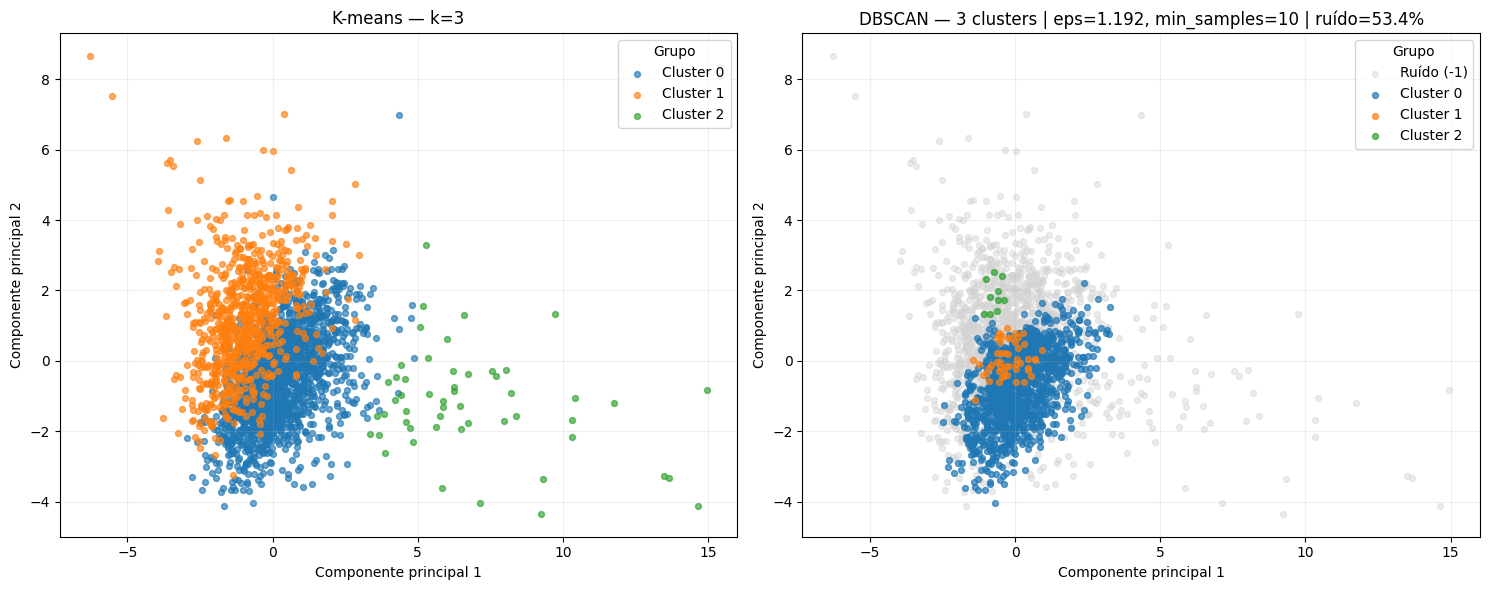

K-means — lutadores por cluster:


,lutadores
cluster,
0,1853
1,788
2,52


DBSCAN — lutadores por rótulo:


,lutadores
rótulo (-1 = ruído),
-1,1438
0,1195
1,50
2,10


In [361]:
# Configuração do DBSCAN que encontrou 3 clusters
opcoes = avaliacao_dbscan.loc[
    avaliacao_dbscan["min_samples"].eq(10)
    & avaliacao_dbscan["qtd_clusters"].eq(3)
].sort_values("pct_ruido")

if opcoes.empty:
    raise ValueError(
        "Não encontrei uma configuração do DBSCAN com 3 clusters "
        "e min_samples=10."
    )

config = opcoes.iloc[0]
eps_dbscan = float(config["eps"])
min_samples_dbscan = int(config["min_samples"])

# Ajusta os dois métodos sobre a mesma matriz
rotulos_kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20,
).fit_predict(X_cluster)

rotulos_dbscan_3 = DBSCAN(
    eps=eps_dbscan,
    min_samples=min_samples_dbscan,
    metric="euclidean",
).fit_predict(X_cluster)

qtd_clusters_dbscan = len(set(rotulos_dbscan_3) - {-1})
if qtd_clusters_dbscan != 3:
    raise ValueError(
        f"O DBSCAN encontrou {qtd_clusters_dbscan} clusters, não 3."
    )

# PCA serve somente para projetar os pontos em 2D no gráfico.
X_2d = PCA(n_components=2).fit_transform(X_cluster)

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))

# K-means
for cluster in sorted(np.unique(rotulos_kmeans_3)):
    mascara = rotulos_kmeans_3 == cluster
    eixos[0].scatter(
        X_2d[mascara, 0],
        X_2d[mascara, 1],
        s=18,
        alpha=0.65,
        label=f"Cluster {cluster}",
    )

eixos[0].set_title("K-means — k=3")
eixos[0].set_xlabel("Componente principal 1")
eixos[0].set_ylabel("Componente principal 2")
eixos[0].legend(title="Grupo")
eixos[0].grid(alpha=0.2)

# DBSCAN: -1 é ruído
ruido = rotulos_dbscan_3 == -1
eixos[1].scatter(
    X_2d[ruido, 0],
    X_2d[ruido, 1],
    color="lightgray",
    s=18,
    alpha=0.45,
    label="Ruído (-1)",
)

for cluster in sorted(set(rotulos_dbscan_3) - {-1}):
    mascara = rotulos_dbscan_3 == cluster
    eixos[1].scatter(
        X_2d[mascara, 0],
        X_2d[mascara, 1],
        s=18,
        alpha=0.7,
        label=f"Cluster {cluster}",
    )

eixos[1].set_title(
    f"DBSCAN — 3 clusters | eps={eps_dbscan:.3f}, "
    f"min_samples={min_samples_dbscan} | ruído={ruido.mean():.1%}"
)
eixos[1].set_xlabel("Componente principal 1")
eixos[1].set_ylabel("Componente principal 2")
eixos[1].legend(title="Grupo")
eixos[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("K-means — lutadores por cluster:")
display(
    pd.Series(rotulos_kmeans_3)
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("lutadores")
)

print("DBSCAN — lutadores por rótulo:")
display(
    pd.Series(rotulos_dbscan_3)
    .value_counts()
    .sort_index()
    .rename_axis("rótulo (-1 = ruído)")
    .to_frame("lutadores")
)

#### Resultado da clusterização da primeira luta

A expectativa inicial era entender se conseguimos identificar um perfil, utilizando dbscan ou kmeans.
Porém não tivemos tanto sucesso no desenvolvimento, tivemos os mesmo 2 grupos que já tinhamos com a clusterização temporal e com menos variáveis que agregem o dataset.

### Após a clusterização, próximos passo:
- Criar uma nova variavel na tabela de luta, sendo cluster_anterior daquele fighter_id, para os caso que não são estreantes. para o que são estreantes é sem registro. 
- Criar uma nova variavel na tabela de luta, se houve transição em algum momento da carreira 


Então basicamente vamos ter o cenário:
- Cluster analisando o passado daquela linha
- Mais variaveis analisando uma antes do passado contra a luta passada, para entender se estamos tendo uma mudança de estratégia.

In [362]:
df_transicoes = gold_hist_clusterizado.copy()

df_transicoes["fighter_id"] = (
    df_transicoes["fighter_id"].astype("string").str.strip()
)
df_transicoes["event_date"] = pd.to_datetime(
    df_transicoes["event_date"],
    errors="coerce",
).dt.normalize()
df_transicoes["cluster"] = pd.to_numeric(
    df_transicoes["cluster"],
    errors="coerce",
).astype("Int64")

colunas_obrigatorias = [
    "fight_id_hist",
    "fighter_id",
    "event_date",
    "corner",
    "cluster",
]
faltando = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in df_transicoes.columns
]
if faltando:
    raise ValueError(f"Colunas ausentes: {faltando}")

# Não rejeitamos cluster ausente: pode identificar o período de calibração.
if df_transicoes[["fight_id_hist", "fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fight_id_hist, fighter_id ou event_date ausente."
    )

# Confirma que as observações do mesmo lutador e dia têm um único estado.
conflitos = (
    df_transicoes.groupby(["fighter_id", "event_date"])["cluster"]
    .nunique(dropna=False)
    .gt(1)
)
if conflitos.any():
    exemplos = conflitos[conflitos].reset_index().head(10)
    raise ValueError(
        "Um lutador tem clusters diferentes no mesmo dia. "
        "Investigue esses registros antes de continuar:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Uma linha por lutador-dia: o cluster já foi validado como consistente.
por_dia = (
    df_transicoes[
        ["fighter_id", "event_date", "cluster"]
    ]
    .drop_duplicates()
    .sort_values(["fighter_id", "event_date"])
    .reset_index(drop=True)
    .rename(columns={"cluster": "cluster_dia"})
)

# Cluster e perfil técnico do dia anterior.
por_dia["cluster_anterior_dia"] = (
    por_dia.groupby("fighter_id")["cluster_dia"]
    .shift(1)
    .astype("Int64")
)

atual = por_dia["cluster_dia"]
anterior = por_dia["cluster_anterior_dia"]

# Só conta transição quando ambos os dias têm perfil técnico.
por_dia["alterou_perfil_desde_ultima"] = (
    atual.ge(0)
    & anterior.ge(0)
    & atual.ne(anterior)
).fillna(False)

# Entrada em perfil técnico após um estado inconclusivo (-2).
por_dia["entrou_em_perfil_tecnico"] = (
    atual.ge(0)
    & anterior.eq(-2)
).fillna(False)

# Acumulado até a data atual, incluindo a transição dessa data.
por_dia["qtd_transicoes_ate_dia"] = (
    por_dia.groupby("fighter_id")["alterou_perfil_desde_ultima"]
    .cumsum()
)
por_dia["houve_transicao_ate_dia"] = (
    por_dia["qtd_transicoes_ate_dia"] > 0
)

# Repete o estado diário em cada linha de participação/luta.
df_transicoes = df_transicoes.merge(
    por_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
)

print("Linhas com transições:", len(df_transicoes))
print("Dias lutador-data:", len(por_dia))
print("Dias com transição técnica:",
      int(por_dia["alterou_perfil_desde_ultima"].sum()))

Linhas com transições: 17472
Dias lutador-data: 17393
Dias com transição técnica: 205


In [363]:
df_transicoes[df_transicoes['fighter_id']=='d71d968dc6ecfdaf']

,index,Unnamed: 0,fight_id_hist,event_date,tempo_luta_segundos,fighter_id,result,corner,categoria_luta,sexo_luta,...,cluster_anterior_tecnico,mudou_perfil_tecnico,transicao_perfil_tecnico,qtd_transicoes_tecnicas_ate_dia,cluster_dia,cluster_anterior_dia,alterou_perfil_desde_ultima,entrou_em_perfil_tecnico,qtd_transicoes_ate_dia,houve_transicao_ate_dia
8536,8536,8536,8536,1999-11-19,492.0,d71d968dc6ecfdaf,W,red,Open Weight,Masculino,...,<NA>,False,<NA>,<NA>,-2,<NA>,False,False,0,False
17274,17274,17274,8538,1999-11-19,555.0,d71d968dc6ecfdaf,L,blue,Ultimate Japan 2 Heavyweight Tournament Title,Masculino,...,<NA>,False,<NA>,<NA>,-2,<NA>,False,False,0,False


In [364]:
datas = (
    pd.to_datetime(gold_hist["event_date"], errors="coerce")
    .dropna()
    .dt.normalize()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

if len(datas) < 2:
    raise ValueError("São necessárias pelo menos duas datas distintas.")

posicao_corte = int(len(datas) * 0.80)
posicao_corte = min(max(posicao_corte, 1), len(datas) - 1)

data_corte = datas.iloc[posicao_corte]

treino = gold_hist[
    pd.to_datetime(gold_hist["event_date"], errors="coerce") < data_corte
].copy()

teste = gold_hist[
    pd.to_datetime(gold_hist["event_date"], errors="coerce") >= data_corte
].copy()

print(f"Data de corte: {data_corte.date()}")
print(f"Treino: {len(treino):,} linhas")
print(f"Teste:  {len(teste):,} linhas")
print(
    "Período de treino:",
    treino["event_date"].min(),
    "até",
    treino["event_date"].max(),
)
print(
    "Período de teste:",
    teste["event_date"].min(),
    "até",
    teste["event_date"].max(),
)

Data de corte: 2022-11-05
Treino: 13,680 linhas
Teste:  3,792 linhas
Período de treino: 1994-03-11 até 2022-10-29
Período de teste: 2022-11-05 até 2026-06-27


In [365]:

if "cluster_temporal" in gold_hist_clusterizado.columns:
    coluna_cluster = "cluster_temporal"
elif "cluster" in gold_hist_clusterizado.columns:
    coluna_cluster = "cluster"
else:
    raise ValueError(
        "gold_hist_clusterizado não contém cluster_temporal nem cluster."
    )

colunas_hist = ["fighter_id", "event_date", coluna_cluster]
faltando_hist = [
    coluna for coluna in colunas_hist
    if coluna not in gold_hist_clusterizado.columns
]
if faltando_hist:
    raise ValueError(
        f"Colunas ausentes em gold_hist_clusterizado: {faltando_hist}"
    )

df_transicoes = gold_hist_clusterizado[
    colunas_hist
].copy()

df_transicoes["fighter_id"] = (
    df_transicoes["fighter_id"].astype("string").str.strip()
)
df_transicoes["event_date"] = pd.to_datetime(
    df_transicoes["event_date"],
    errors="coerce",
).dt.normalize()
df_transicoes["cluster_dia"] = pd.to_numeric(
    df_transicoes[coluna_cluster],
    errors="coerce",
).astype("Int64")

if df_transicoes[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente/inválido em "
        "gold_hist_clusterizado."
    ) 
df_transicoes.loc[
    df_transicoes["cluster_dia"].isin([-1, -2]),
    "cluster_dia",
] = -2

# O estado deve ser igual em todas as linhas do mesmo lutador-dia.
conflitos = (
    df_transicoes
    .groupby(["fighter_id", "event_date"])["cluster_dia"]
    .nunique(dropna=False)
    .gt(1)
)

if conflitos.any():
    exemplos = conflitos[conflitos].reset_index().head(10)
    raise ValueError(
        "Há estados diferentes para o mesmo lutador e data. "
        "Revise antes do merge:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Uma linha por lutador-data. Nulos são calibração.
df_transicoes = (
    df_transicoes[
        ["fighter_id", "event_date", "cluster_dia"]
    ]
    .drop_duplicates(["fighter_id", "event_date"])
    .sort_values(["fighter_id", "event_date"])
    .reset_index(drop=True)
)

df_transicoes["grupo_temporal"] = pd.Series(
    "Calibração - não classificado",
    index=df_transicoes.index,
    dtype="string",
)

inconclusivo = df_transicoes["cluster_dia"].eq(-2)
df_transicoes.loc[inconclusivo, "grupo_temporal"] = "Perfil inconclusivo"

tecnico = df_transicoes["cluster_dia"].ge(0)
df_transicoes.loc[tecnico, "grupo_temporal"] = (
    "Perfil "
    + df_transicoes.loc[tecnico, "cluster_dia"].astype(int).astype(str)
)


# ------------------------------------------------------------
# 2. Calcular transições entre perfis técnicos
# ------------------------------------------------------------

# Compara somente observações técnicas consecutivas.
# Perfil inconclusivo e calibração não são tratados como estilos.
historico_tecnico = (
    df_transicoes.loc[df_transicoes["cluster_dia"].ge(0)]
    .sort_values(["fighter_id", "event_date"])
    .copy()
)

historico_tecnico["cluster_anterior_tecnico"] = (
    historico_tecnico.groupby("fighter_id")["cluster_dia"]
    .shift(1)
    .astype("Int64")
)

historico_tecnico["alterou_perfil_desde_ultima"] = (
    historico_tecnico["cluster_anterior_tecnico"].notna()
    & historico_tecnico["cluster_dia"].ne(
        historico_tecnico["cluster_anterior_tecnico"]
    )
)

historico_tecnico["qtd_transicoes_ate_dia"] = (
    historico_tecnico.groupby("fighter_id")[
        "alterou_perfil_desde_ultima"
    ].cumsum()
)

historico_tecnico["houve_transicao_ate_dia"] = (
    historico_tecnico["qtd_transicoes_ate_dia"] > 0
)

colunas_transicao = [
    "fighter_id",
    "event_date",
    "cluster_anterior_tecnico",
    "alterou_perfil_desde_ultima",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
]

df_transicoes = df_transicoes.merge(
    historico_tecnico[colunas_transicao],
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)

# Dias sem perfil técnico atual não são uma transição técnica.
df_transicoes["alterou_perfil_desde_ultima"] = (
    df_transicoes["alterou_perfil_desde_ultima"]
    .fillna(False)
    .astype(bool)
)
df_transicoes["houve_transicao_ate_dia"] = (
    df_transicoes["houve_transicao_ate_dia"]
    .fillna(False)
    .astype(bool)
)

# Mantém a contagem acumulada conhecida até dias sem perfil técnico.
df_transicoes = df_transicoes.sort_values(
    ["fighter_id", "event_date"]
).reset_index(drop=True)

df_transicoes["qtd_transicoes_ate_dia"] = (
    df_transicoes.groupby("fighter_id")["qtd_transicoes_ate_dia"]
    .ffill()
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# 3. Limpar gold_fight e preparar as chaves de cruzamento
# ------------------------------------------------------------

gold_fight_limpo = gold_fight.copy()

colunas_unnamed = [
    coluna for coluna in gold_fight_limpo.columns
    if str(coluna).startswith("Unnamed")
]
gold_fight_limpo = gold_fight_limpo.drop(columns=colunas_unnamed)

colunas_chave_luta = [
    "event_date",
    "red_fighter_id",
    "blue_fighter_id",
]
faltando_luta = [
    coluna for coluna in colunas_chave_luta
    if coluna not in gold_fight_limpo.columns
]
if faltando_luta:
    raise ValueError(
        f"Colunas ausentes em gold_fight: {faltando_luta}"
    )

gold_fight_limpo["_linha_fight"] = np.arange(len(gold_fight_limpo))
gold_fight_limpo["event_date"] = pd.to_datetime(
    gold_fight_limpo["event_date"],
    errors="coerce",
).dt.normalize()

for coluna in ["red_fighter_id", "blue_fighter_id"]:
    gold_fight_limpo[coluna] = (
        gold_fight_limpo[coluna].astype("string").str.strip()
    )

if gold_fight_limpo[
    ["event_date", "red_fighter_id", "blue_fighter_id"]
].isna().any().any():
    raise ValueError(
        "Há event_date ou ID de lutador ausente em gold_fight."
    )


# ------------------------------------------------------------
# 4. Juntar os atributos de transição para cada canto
# ------------------------------------------------------------

features_para_merge = [
    "cluster_dia",
    "grupo_temporal",
    "cluster_anterior_tecnico",
    "alterou_perfil_desde_ultima",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
]

lutas_com_transicoes = gold_fight_limpo.copy()

for canto, coluna_id in [
    ("red", "red_fighter_id"),
    ("blue", "blue_fighter_id"),
]:
    lado = lutas_com_transicoes[
        ["_linha_fight", "event_date", coluna_id]
    ].rename(columns={
        coluna_id: "fighter_id",
    })

    lado["fighter_id"] = lado["fighter_id"].astype("string").str.strip()

    lado = lado.merge(
        df_transicoes[
            ["fighter_id", "event_date", *features_para_merge]
        ],
        on=["fighter_id", "event_date"],
        how="left",
        validate="many_to_one",
        indicator="_merge_transicao",
    )

    lado[f"{canto}_transicao_encontrada"] = (
        lado["_merge_transicao"].eq("both")
    )

    lado = lado[
        [
            "_linha_fight",
            *features_para_merge,
            f"{canto}_transicao_encontrada",
        ]
    ].rename(columns={
        coluna: f"{canto}_{coluna}"
        for coluna in features_para_merge
    })

    lutas_com_transicoes = lutas_com_transicoes.merge(
        lado,
        on="_linha_fight",
        how="left",
        validate="one_to_one",
    ) 

gold_fight_com_transicoes = lutas_com_transicoes.drop(
    columns="_linha_fight"
)

print("Colunas Unnamed removidas:", colunas_unnamed)
print("Lutas na base original:", len(gold_fight))
print("Lutas após o merge:", len(gold_fight_com_transicoes))
print("\nCobertura do cruzamento:")
print(
    "Red encontrou estado:",
    int(gold_fight_com_transicoes["red_transicao_encontrada"].sum()),
    "de",
    len(gold_fight_com_transicoes),
)
print(
    "Blue encontrou estado:",
    int(gold_fight_com_transicoes["blue_transicao_encontrada"].sum()),
    "de",
    len(gold_fight_com_transicoes),
)

print("\nExemplo das colunas adicionadas:")
display(
    gold_fight_com_transicoes[
        [
            "event_date",
            "red_fighter_id",
            "red_grupo_temporal",
            "red_cluster_anterior_tecnico",
            "red_alterou_perfil_desde_ultima",
            "blue_fighter_id",
            "blue_grupo_temporal",
            "blue_cluster_anterior_tecnico",
            "blue_alterou_perfil_desde_ultima",
        ]
    ].head()
)

Colunas Unnamed removidas: ['Unnamed: 0']
Lutas na base original: 8736
Lutas após o merge: 8736

Cobertura do cruzamento:
Red encontrou estado: 8736 de 8736
Blue encontrou estado: 8736 de 8736

Exemplo das colunas adicionadas:


,event_date,red_fighter_id,red_grupo_temporal,red_cluster_anterior_tecnico,red_alterou_perfil_desde_ultima,blue_fighter_id,blue_grupo_temporal,blue_cluster_anterior_tecnico,blue_alterou_perfil_desde_ultima
0,2026-06-27,95aff2fd8d09a5f0,Perfil inconclusivo,<NA>,False,6add18754930182b,Perfil 0,<NA>,False
1,2026-06-27,36b8f265bcd1b7a4,Perfil 0,0,False,0d65c432720accb9,Perfil 0,0,False
2,2026-06-27,8d3273573b85be09,Perfil 1,1,False,814e5233e2acf2ee,Perfil 1,1,False
3,2026-06-27,a4dc0f2b95df4cc1,Perfil 1,<NA>,False,ffd3224638c01b57,Perfil 1,1,False
4,2026-06-27,70dd69b6a703257e,Perfil inconclusivo,<NA>,False,a726c784676a50b6,Perfil inconclusivo,<NA>,False


--------------
### Modelo

A mudança recente de perfil técnico, estimada a partir do histórico pré-luta, melhora a previsão do vencedor em comparação com as variáveis pré-luta convencionais?



------------------------------------------
Nosso objetivo será:
- Encontrar um modelo que prevê a vitória de um dos lutadores, com a nossa base inicial e entender se tivemos uma melhora significativa na predição após o tratamento e o enriquecimento das variáveis.
- Serão dois modelos:
    - Antes da luta, com variáveis históricas.
    - Com o desempenho da luta, será que temos uma boa predição. (Entender quais variáveis são mais importantes para o modelo)

------------------------------------------
Ponto importante, iremos fazer o processo de análise dos modelso com duas bases:
- Base crua - Dados gold_fight
- Base enriquecida - Dados com a clusterização e tratamento das variáveis.

##### _Preparação:_ Base crua: referência sem seleção por multicolinearidade

A tabela original será preservada. Nesta etapa não serão criadas precisões por alvo nem removidas estatísticas redundantes. Pearson e VIF serão usados apenas como diagnóstico. Resultados e estatísticas da luta corrente não são entradas válidas para prever essa mesma luta antes do combate.

In [366]:
gold_fight = pd.read_csv(
    "base_dados/processed_gold/tabela_lutas_finais.csv"
)
gold_fight_crua = gold_fight.copy(deep=True)


C:\Users\edude\AppData\Local\Temp\ipykernel_99764\1019445708.py:1: DtypeWarning: Columns (100) have mixed types. Specify dtype option on import or set low_memory=False.
  gold_fight = pd.read_csv(


In [367]:
pd.testing.assert_frame_equal(gold_fight, gold_fight_crua)
print("Base crua preservada:", gold_fight_crua.shape)


Base crua preservada: (8736, 118)


In [368]:
numeric_cols = gold_fight_crua.select_dtypes(exclude='object')
object_cols = gold_fight_crua.select_dtypes(include='object')

print(f'colunas numericas da nossa base de dados: {list(numeric_cols)}')
print(f'quantidade de colunas numericas: {numeric_cols.shape[1]}')
print(f'colunas categóricas da nossa base de dados: {list(object_cols)}')
print(f'quantidade de colunas categoricas: {object_cols.shape[1]}')


colunas numericas da nossa base de dados: ['Unnamed: 0', 'round', 'bonus', 'red_fighter_kd', 'blue_fighter_kd', 'red_fighter_sig_str_pct', 'blue_fighter_sig_str_pct', 'red_fighter_sub_att', 'blue_fighter_sub_att', 'red_fighter_rev', 'blue_fighter_rev', 'red_fighter_sig_str_head_pct', 'blue_fighter_sig_str_head_pct', 'red_fighter_sig_str_body_pct', 'blue_fighter_sig_str_body_pct', 'red_fighter_sig_str_leg_pct', 'blue_fighter_sig_str_leg_pct', 'red_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_distance_pct', 'red_fighter_sig_str_clinch_pct', 'blue_fighter_sig_str_clinch_pct', 'red_fighter_sig_str_ground_pct', 'blue_fighter_sig_str_ground_pct', 'time_seconds', 'red_fighter_sig_str_landed', 'red_fighter_sig_str_attempted', 'blue_fighter_sig_str_landed', 'blue_fighter_sig_str_attempted', 'red_fighter_sig_str_pct_num', 'blue_fighter_sig_str_pct_num', 'red_fighter_total_str_landed', 'red_fighter_total_str_attempted', 'blue_fighter_total_str_landed', 'blue_fighter_total_str_attempted', 

red_fighter_result
W     5498
L     3083
NC      90
D       65
Name: count, dtype: int64
red_fighter_result
W     0.629350
L     0.352908
NC    0.010302
D     0.007440
Name: proportion, dtype: float64


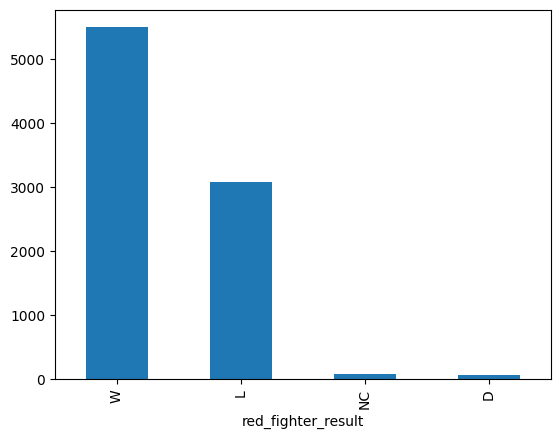

In [369]:
 
gold_fight_crua['red_fighter_result'].value_counts().plot(kind='bar')
print(gold_fight_crua['red_fighter_result'].value_counts())
print(gold_fight_crua['red_fighter_result'].value_counts(normalize=True))
plt.show()

In [370]:
decisivas_crua = (
    (gold_fight_crua["red_fighter_result"].eq("W")
     & gold_fight_crua["blue_fighter_result"].eq("L"))
    | (gold_fight_crua["red_fighter_result"].eq("L")
       & gold_fight_crua["blue_fighter_result"].eq("W"))
)
base_crua = gold_fight_crua.loc[decisivas_crua].copy()
base_crua["alvo_red_vence"] = (
    base_crua["red_fighter_result"].eq("W").astype("int8")
)
print("Lutas na referência:", len(gold_fight_crua))
print("Lutas com vitória/derrota consistentes:", len(base_crua))
print("Demais resultados excluídos do recorte:", int((~decisivas_crua).sum()))


Lutas na referência: 8736
Lutas com vitória/derrota consistentes: 8581
Demais resultados excluídos do recorte: 155


alvo_red_vence
1    5498
0    3083
Name: count, dtype: int64
alvo_red_vence
1    0.640718
0    0.359282
Name: proportion, dtype: float64


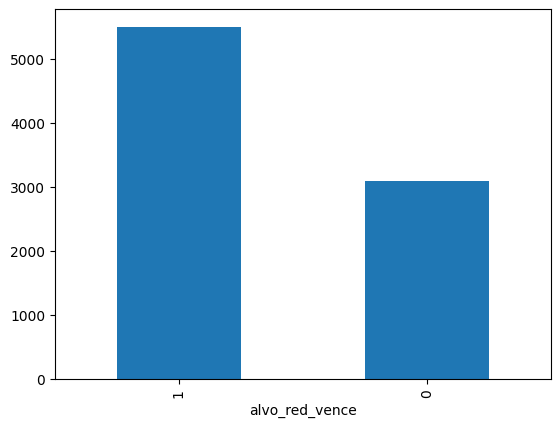

In [371]:
base_crua['alvo_red_vence'].value_counts().plot(kind='bar')
print(base_crua['alvo_red_vence'].value_counts())
print(base_crua['alvo_red_vence'].value_counts(normalize=True))
plt.show()

In [372]:
metricas_gerais = [
    "kd",
    "sig_str_landed",
    "sig_str_attempted",
    "td_landed",
    "td_attempted",
    "sub_att",
    "rev",
    "ctrl_segundo",
]

numericas_crua = [
    f"{cor}_fighter_{metrica}"
    for cor in ["red", "blue"]
    for metrica in metricas_gerais
]
 
categoricas_crua = [ 
    "bout_type",
    "better_rank",
]
 
base_crua = base_crua[
    numericas_crua
    + categoricas_crua
    + ["alvo_red_vence"]
].copy()
 
numericas = base_crua[numericas_crua].copy()

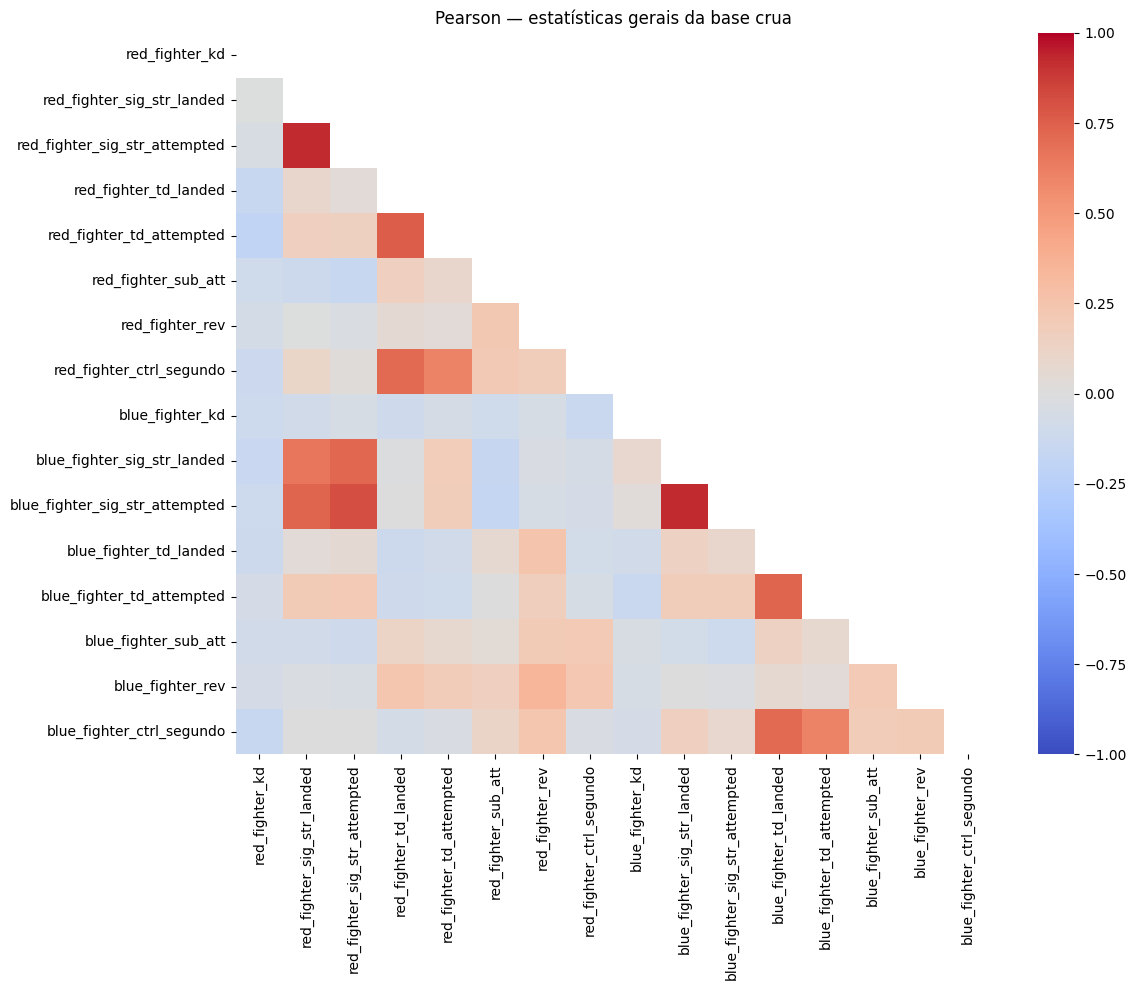

,variavel,VIF
0,red_fighter_sig_str_attempted,10.763146
1,blue_fighter_sig_str_attempted,10.349410
2,red_fighter_sig_str_landed,8.112545
3,blue_fighter_sig_str_landed,7.763900
4,red_fighter_td_landed,3.321191
5,blue_fighter_td_landed,2.991727
6,red_fighter_td_attempted,2.794339
7,blue_fighter_td_attempted,2.491148
8,red_fighter_ctrl_segundo,2.471590
9,blue_fighter_ctrl_segundo,2.421898


In [373]:
 
X_diagnostico = (
    X_crua[features_numericas_crua]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
 
X_diagnostico = X_diagnostico.loc[
    :, X_diagnostico.nunique(dropna=True).gt(1)
]

X_diagnostico = X_diagnostico.fillna(X_diagnostico.median())

# Pearson
plt.figure(figsize=(12, 10))
sns.heatmap(
    X_diagnostico.corr(),
    mask=np.triu(
        np.ones((X_diagnostico.shape[1],) * 2, dtype=bool)
    ),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Pearson — estatísticas gerais da base crua")
plt.tight_layout()
plt.show()

# VIF
X_vif = add_constant(X_diagnostico, has_constant="add")

resultado_vif = pd.DataFrame({
    "variavel": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.to_numpy(dtype=float), i
        )
        for i in range(X_vif.shape[1])
    ],
})

resultado_vif = (
    resultado_vif.loc[resultado_vif["variavel"].ne("const")]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(resultado_vif)

In [374]:
base_crua["better_rank"] = (
    base_crua["better_rank"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "0": "Sem melhor ranking definido",
        "0.0": "Sem melhor ranking definido",
        "neither": "Sem melhor ranking definido",
        "red": "Red",
        "blue": "Blue",
        # Recupera o rótulo sugerido anteriormente, se já aplicado
        "sem informação": "Sem melhor ranking definido",
    })
    .fillna("Sem melhor ranking definido")
)

display(
    base_crua["better_rank"].value_counts(
        normalize=True,
        dropna=False,
    )
)

better_rank
Sem melhor ranking definido    0.771938
Red                            0.217341
Blue                           0.010721
Name: proportion, dtype: Float64

better_rank
Sem melhor ranking definido    6624
Red                            1865
Blue                             92
Name: count, dtype: Int64
better_rank
Sem melhor ranking definido    0.771938
Red                            0.217341
Blue                           0.010721
Name: proportion, dtype: Float64


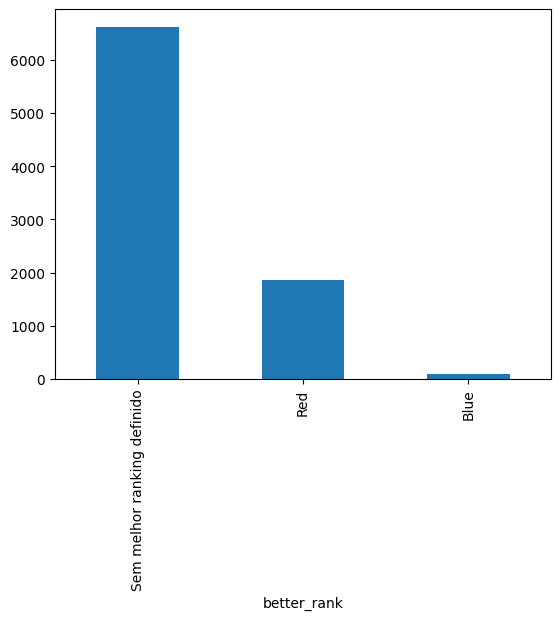

In [375]:
base_crua['better_rank'].value_counts().plot(kind='bar')
print(base_crua['better_rank'].value_counts())
print(base_crua['better_rank'].value_counts(normalize=True))
plt.show()

###### Decisões iniciais

- A gold_fight e sua cópia gold_fight_crua preservam todas as colunas e valores originais. A base_crua contém apenas lutas com resultados W/L complementares e recebe o alvo binário. NC, empates e outros resultados ficam fora desse recorte, mas permanecem na referência.
- A escolha das variaveis agrupada será o objetivo, pois será o modelo com base crua.
- Tratamento da coluna `better_rank` necessária.
- Teremos então uma base com 20 features

In [376]:
numeric_cols = base_crua.select_dtypes(exclude='object')
object_cols = base_crua.select_dtypes(include='object')

print(f'colunas numericas da nossa base de dados: {list(numeric_cols)}')
print(f'quantidade de colunas numericas: {numeric_cols.shape[1]}')
print(f'colunas categóricas da nossa base de dados: {list(object_cols)}')
print(f'quantidade de colunas categoricas: {object_cols.shape[1]}')


colunas numericas da nossa base de dados: ['red_fighter_kd', 'red_fighter_sig_str_landed', 'red_fighter_sig_str_attempted', 'red_fighter_td_landed', 'red_fighter_td_attempted', 'red_fighter_sub_att', 'red_fighter_rev', 'red_fighter_ctrl_segundo', 'blue_fighter_kd', 'blue_fighter_sig_str_landed', 'blue_fighter_sig_str_attempted', 'blue_fighter_td_landed', 'blue_fighter_td_attempted', 'blue_fighter_sub_att', 'blue_fighter_rev', 'blue_fighter_ctrl_segundo', 'better_rank', 'alvo_red_vence']
quantidade de colunas numericas: 18
colunas categóricas da nossa base de dados: ['bout_type']
quantidade de colunas categoricas: 1


##### _Preparação:_ base enriquecida com detalhes e diferenças

A base crua usa estatísticas gerais individuais. Na enriquecida, cada diferença vermelho menos azul substitui suas duas fontes. Mantemos o detalhe dos golpes por alvo e posição, além dos clusters e das transições. A fonte gold_fight_com_transicoes permanece preservada.

As contagens agregadas sig_str_landed/attempted e total_str_landed/attempted, incluindo suas diferenças, ficam fora desta versão. total_str inclui golpes não significativos; sua retirada é uma escolha da representação detalhada.

Para evitar a identidade entre duas decomposições completas, ground é usado como referência: nas contagens observadas completas e consistentes, diff_ground = diff_head + diff_body + diff_leg - diff_distance - diff_clinch. Assim, retiramos apenas diff_sig_str_ground_landed/attempted das entradas, preservando as cinco demais regiões por medida.

Nos percentuais individuais, retiramos head_pct do grupo de alvos e ground_pct do grupo de posições, em ambos os lutadores. Esses percentuais representam distribuição, não precisão. Arredondamento, zero acertos e ausências impedem afirmar que o componente retirado seja sempre exatamente 100 menos os demais.
 

In [411]:
numeric_cols = gold_fight_com_transicoes.select_dtypes(exclude='object')
object_cols = gold_fight_com_transicoes.select_dtypes(include='object')

print(f'colunas numericas da nossa base de dados: {list(numeric_cols)}')
print(f'quantidade de colunas numericas: {numeric_cols.shape[1]}')
print(f'colunas categóricas da nossa base de dados: {list(object_cols)}')
print(f'quantidade de colunas categoricas: {object_cols.shape[1]}')


colunas numericas da nossa base de dados: ['event_date', 'round', 'bonus', 'red_fighter_kd', 'blue_fighter_kd', 'red_fighter_sig_str_pct', 'blue_fighter_sig_str_pct', 'red_fighter_sub_att', 'blue_fighter_sub_att', 'red_fighter_rev', 'blue_fighter_rev', 'red_fighter_sig_str_head_pct', 'blue_fighter_sig_str_head_pct', 'red_fighter_sig_str_body_pct', 'blue_fighter_sig_str_body_pct', 'red_fighter_sig_str_leg_pct', 'blue_fighter_sig_str_leg_pct', 'red_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_distance_pct', 'red_fighter_sig_str_clinch_pct', 'blue_fighter_sig_str_clinch_pct', 'red_fighter_sig_str_ground_pct', 'blue_fighter_sig_str_ground_pct', 'time_seconds', 'red_fighter_sig_str_landed', 'red_fighter_sig_str_attempted', 'blue_fighter_sig_str_landed', 'blue_fighter_sig_str_attempted', 'red_fighter_sig_str_pct_num', 'blue_fighter_sig_str_pct_num', 'red_fighter_total_str_landed', 'red_fighter_total_str_attempted', 'blue_fighter_total_str_landed', 'blue_fighter_total_str_attempted', 

In [417]:
# Reconstruir a partir da tabela com clusters para recuperar os detalhes.
base_enriquecida = gold_fight_com_transicoes.copy(deep=True)

# Precisão pode ser adicionada, mas não substitui acertos nem tentativas.
INCLUIR_ACCURACY = True

# Mesmo recorte binário da base crua.
decisivas = (
    (base_enriquecida["red_fighter_result"].eq("W")
     & base_enriquecida["blue_fighter_result"].eq("L"))
    | (base_enriquecida["red_fighter_result"].eq("L")
       & base_enriquecida["blue_fighter_result"].eq("W"))
)
base_enriquecida = base_enriquecida.loc[decisivas].copy()
base_enriquecida["alvo_red_vence"] = (
    base_enriquecida["red_fighter_result"].eq("W").astype("int8")
)

regioes_golpes = ["head", "body", "leg", "distance", "clinch", "ground"]
metricas_golpes_detalhados = [
    f"sig_str_{regiao}_{medida}"
    for regiao in regioes_golpes
    for medida in ["landed", "attempted"]
]

# Calcular as diferenças antes de retirar suas colunas-fonte na próxima célula.
pares_diferencas = {
    "kd": "diff_kd",
    "sig_str_pct_num": "diff_sig_str_pct",
    "td_pct_num": "diff_td_pct",
    "sub_att": "diff_sub_att",
    "rev": "diff_rev",
    "ctrl_segundo": "diff_ctrl",
}
for metrica in [
    "td_landed", "td_attempted",
    *metricas_golpes_detalhados,
]:
    pares_diferencas[metrica] = f"diff_{metrica}"

for metrica, nome_diff in pares_diferencas.items():
    coluna_red = f"red_fighter_{metrica}"
    coluna_blue = f"blue_fighter_{metrica}"
    # Ausência em qualquer lado permanece NaN; não inventar diferença zero.
    base_enriquecida[nome_diff] = (
        pd.to_numeric(base_enriquecida[coluna_red], errors="coerce")
        - pd.to_numeric(base_enriquecida[coluna_blue], errors="coerce")
    )

if INCLUIR_ACCURACY:
    for cor in ["red", "blue"]:
        for regiao in regioes_golpes:
            prefixo = f"{cor}_fighter_sig_str_{regiao}"
            acertos = pd.to_numeric(
                base_enriquecida[f"{prefixo}_landed"], errors="coerce"
            )
            tentativas = pd.to_numeric(
                base_enriquecida[f"{prefixo}_attempted"], errors="coerce"
            )
            base_enriquecida[f"{prefixo}_accuracy"] = (
                acertos.div(tentativas.where(tentativas.gt(0))) * 100
            )

    for regiao in regioes_golpes:
        base_enriquecida[f"diff_sig_str_{regiao}_accuracy"] = (
            base_enriquecida[f"red_fighter_sig_str_{regiao}_accuracy"]
            - base_enriquecida[f"blue_fighter_sig_str_{regiao}_accuracy"]
        )

print("Lutas na base enriquecida:", len(base_enriquecida))
print("Diferenças disponíveis:", list(pares_diferencas.values()))
print("Accuracy incluída:", INCLUIR_ACCURACY)


Lutas na base enriquecida: 8581
Diferenças disponíveis: ['diff_kd', 'diff_sig_str_pct', 'diff_td_pct', 'diff_sub_att', 'diff_rev', 'diff_ctrl', 'diff_td_landed', 'diff_td_attempted', 'diff_sig_str_head_landed', 'diff_sig_str_head_attempted', 'diff_sig_str_body_landed', 'diff_sig_str_body_attempted', 'diff_sig_str_leg_landed', 'diff_sig_str_leg_attempted', 'diff_sig_str_distance_landed', 'diff_sig_str_distance_attempted', 'diff_sig_str_clinch_landed', 'diff_sig_str_clinch_attempted', 'diff_sig_str_ground_landed', 'diff_sig_str_ground_attempted']
Accuracy incluída: True


In [418]:
# Excluir textos que repetem acertos/tentativas já separados em números.
metricas_textuais = [
    "sig_str", "td", "sig_str_head", "sig_str_body", "sig_str_leg",
    "sig_str_distance", "sig_str_clinch", "sig_str_ground",
]
colunas_remover = [
    f"{cor}_fighter_{metrica}"
    for cor in ["red", "blue"]
    for metrica in metricas_textuais
]
colunas_remover += [
    "event_name", "red_fighter_name", "blue_fighter_name", "event_location",
    "red_key", "blue_key", "date_key", "country_location", "Unnamed: 0",
    "red_fighter_result", "blue_fighter_result", "bonus", "method",
    "red_fighter_pts_mean", "blue_fighter_pts_mean",
]
# Cada diferença substitui as duas colunas que a originaram.
colunas_fonte_diferencas = [
    f"{cor}_fighter_{metrica}"
    for metrica, nome_diff in pares_diferencas.items()
    if nome_diff in base_enriquecida.columns
    for cor in ["red", "blue"]
]

# O percentual geral sem _num é uma cópia da fonte de diff_sig_str_pct.
if "diff_sig_str_pct" in base_enriquecida.columns:
    colunas_fonte_diferencas += [
        "red_fighter_sig_str_pct", "blue_fighter_sig_str_pct",
    ]

# Mesmo critério para a accuracy, quando sua diferença foi criada.
if INCLUIR_ACCURACY:
    colunas_fonte_diferencas += [
        f"{cor}_fighter_sig_str_{regiao}_accuracy"
        for regiao in regioes_golpes
        if f"diff_sig_str_{regiao}_accuracy" in base_enriquecida.columns
        for cor in ["red", "blue"]
    ]

colunas_remover += colunas_fonte_diferencas

# A versão detalhada não usará contagens agregadas de golpes.
# total_str inclui golpes não significativos: sua retirada é uma escolha
# de escopo, não uma identidade com a soma das regiões significativas.
metricas_totais_golpes = [
    "sig_str_landed", "sig_str_attempted",
    "total_str_landed", "total_str_attempted",
]
colunas_totais_golpes = [
    f"{cor}_fighter_{metrica}"
    for cor in ["red", "blue"]
    for metrica in metricas_totais_golpes
] + [f"diff_{metrica}" for metrica in metricas_totais_golpes]
colunas_remover += colunas_totais_golpes

# Referências para as duas decomposições dos mesmos golpes.
# Nas contagens observadas completas e consistentes:
# ground = head + body + leg - distance - clinch.
# Remover só ground elimina a identidade exata, mantendo as demais regiões.
colunas_referencia_enriquecida = [
    "diff_sig_str_ground_landed",
    "diff_sig_str_ground_attempted",
    # Uma referência por trio de percentuais, para cada lutador.
    "red_fighter_sig_str_head_pct",
    "blue_fighter_sig_str_head_pct",
    "red_fighter_sig_str_ground_pct",
    "blue_fighter_sig_str_ground_pct",
]
# Percentuais são composições arredondadas; com zero acertos podem somar 0.
# A retirada da referência não pressupõe reconstrução exata por 100 - demais.
colunas_remover += colunas_referencia_enriquecida
# IDs e data ficam disponíveis para auditoria; o pré-processamento os exclui.
base_enriquecida = base_enriquecida.drop(
    columns=colunas_remover, errors="ignore"
)

# Mesmo tratamento de ranking aplicado na base crua.
base_enriquecida["better_rank"] = (
    base_enriquecida["better_rank"].astype("string").str.strip().str.lower()
    .replace({
        "0": "Sem melhor ranking definido",
        "0.0": "Sem melhor ranking definido",
        "neither": "Sem melhor ranking definido",
        "sem informação": "Sem melhor ranking definido",
        "sem melhor ranking definido": "Sem melhor ranking definido",
        "red": "Red", "blue": "Blue",
    })
    .fillna("Sem melhor ranking definido")
)


In [419]:
# Diagnóstico da enriquecida, sem reutilizar a matriz da base crua.
# Trata-se de exploração; seleção definitiva deve usar somente o treino.
metadados_diagnostico_enriquecida = [
    "alvo_red_vence", "red_fighter_id", "blue_fighter_id", "event_date", "round",
    *[
        f"{cor}_{campo}"
        for cor in ["red", "blue"]
        for campo in ["cluster_dia", "grupo_temporal", "cluster_anterior_tecnico"]
    ],
]
numericas_enriquecida = (
    base_enriquecida.select_dtypes(include="number")
    .drop(columns=metadados_diagnostico_enriquecida, errors="ignore")
)
X_diagnostico_enriquecida = (
    numericas_enriquecida.astype(float)
    .replace([np.inf, -np.inf], np.nan)
)
X_diagnostico_enriquecida = X_diagnostico_enriquecida.loc[
    :, X_diagnostico_enriquecida.nunique(dropna=True).gt(1)
]
X_diagnostico_enriquecida = X_diagnostico_enriquecida.fillna(
    X_diagnostico_enriquecida.median()
)
print("As diferenças substituem seus pares individuais. Avaliar relações entre totais e componentes.")


As diferenças substituem seus pares individuais. Avaliar relações entre totais e componentes.


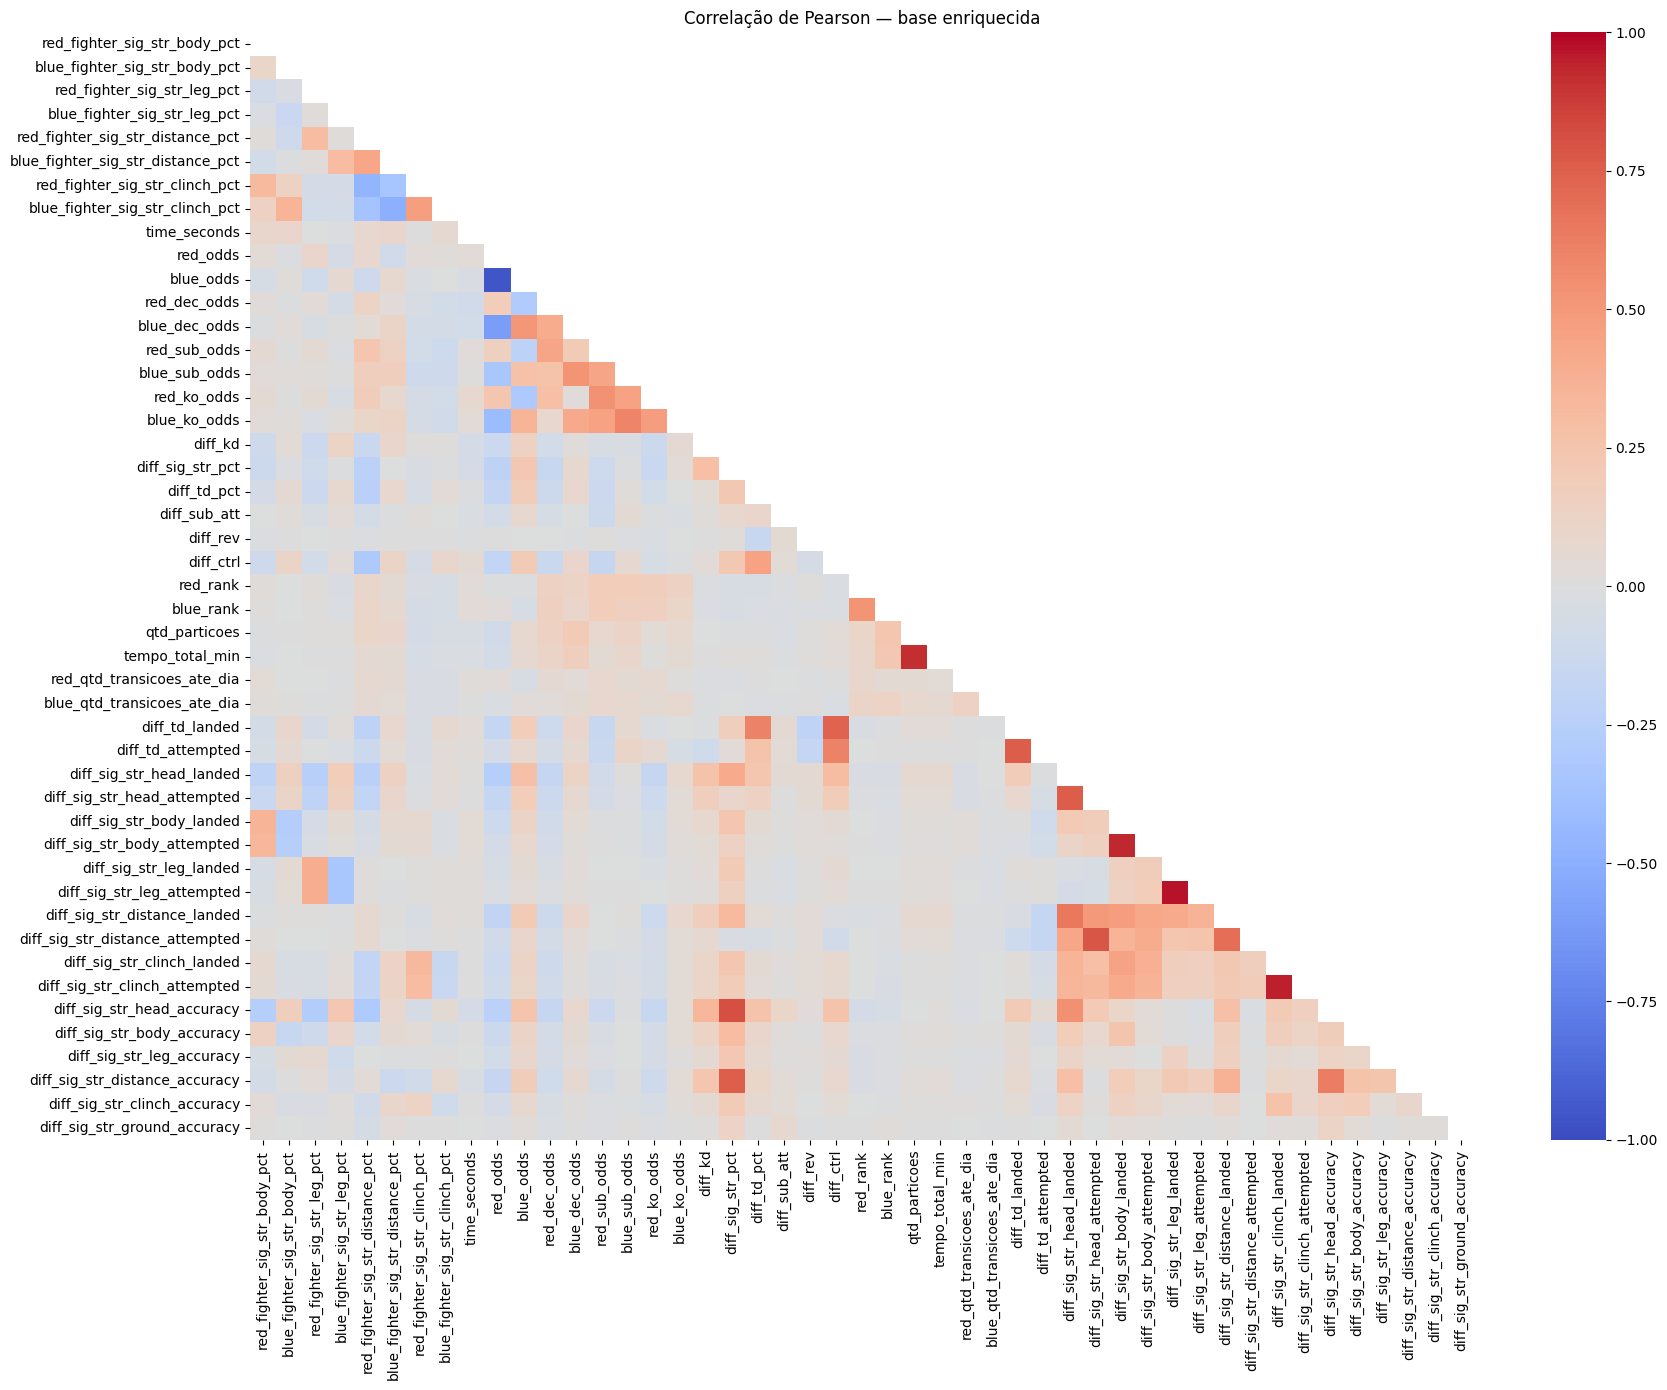

,variavel_1,variavel_2,correlacao,correlacao_absoluta
1015,diff_sig_str_leg_landed,diff_sig_str_leg_attempted,0.971074,0.971074
378,red_odds,blue_odds,-0.956010,0.956010
1053,diff_sig_str_clinch_landed,diff_sig_str_clinch_attempted,0.949978,0.949978
990,diff_sig_str_body_landed,diff_sig_str_body_attempted,0.932284,0.932284
850,qtd_particoes,tempo_total_min,0.921639,0.921639
697,diff_sig_str_pct,diff_sig_str_head_accuracy,0.810296,0.810296
981,diff_sig_str_head_attempted,diff_sig_str_distance_attempted,0.782995,0.782995
928,diff_td_landed,diff_td_attempted,0.761492,0.761492
961,diff_sig_str_head_landed,diff_sig_str_head_attempted,0.759160,0.759160
700,diff_sig_str_pct,diff_sig_str_distance_accuracy,0.754846,0.754846


In [420]:
# 1. Correlação de Pearson
matriz_corr = X_diagnostico_enriquecida.corr(method="pearson")

plt.figure(figsize=(18, 14))

sns.heatmap(
    matriz_corr,
    mask=np.triu(np.ones_like(matriz_corr, dtype=bool)),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
)

plt.title("Correlação de Pearson — base enriquecida")
plt.tight_layout()
plt.show()

# Pares com maior correlação absoluta
triangulo = matriz_corr.where(
    np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)
)

pares_corr = (
    triangulo.stack()
    .rename("correlacao")
    .rename_axis(["variavel_1", "variavel_2"])
    .reset_index()
)

pares_corr["correlacao_absoluta"] = pares_corr["correlacao"].abs()

display(
    pares_corr
    .sort_values("correlacao_absoluta", ascending=False)
    .head(20)
)


In [421]:

# 2. VIF
X_vif_enriquecida = add_constant(X_diagnostico_enriquecida, has_constant="add")

resultado_vif_enriquecida = pd.DataFrame({
    "variavel": X_vif_enriquecida.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_enriquecida.to_numpy(dtype=float), i
        )
        for i in range(X_vif_enriquecida.shape[1])
    ],
})

resultado_vif_enriquecida = (
    resultado_vif_enriquecida
    .loc[lambda tabela: tabela["variavel"].ne("const")]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(resultado_vif_enriquecida)

print("Variáveis com VIF acima de 5:")
display(
    resultado_vif_enriquecida.loc[
        resultado_vif_enriquecida["VIF"].gt(5)
    ]
)
# VIF infinito remanescente pode refletir totais e decomposições das diferenças.
# As fontes red/blue dos pares já foram excluídas na preparação.


,variavel,VIF
0,diff_sig_str_head_attempted,98.887081
1,diff_sig_str_distance_attempted,86.808806
2,diff_sig_str_head_landed,67.355825
3,diff_sig_str_distance_landed,56.225268
4,diff_sig_str_leg_landed,39.550310
5,diff_sig_str_leg_attempted,34.493421
6,diff_sig_str_body_landed,25.447376
7,diff_sig_str_clinch_landed,23.516427
8,diff_sig_str_body_attempted,21.965472
9,diff_sig_str_clinch_attempted,20.282247


Variáveis com VIF acima de 5:


,variavel,VIF
0,diff_sig_str_head_attempted,98.887081
1,diff_sig_str_distance_attempted,86.808806
2,diff_sig_str_head_landed,67.355825
3,diff_sig_str_distance_landed,56.225268
4,diff_sig_str_leg_landed,39.550310
5,diff_sig_str_leg_attempted,34.493421
6,diff_sig_str_body_landed,25.447376
7,diff_sig_str_clinch_landed,23.516427
8,diff_sig_str_body_attempted,21.965472
9,diff_sig_str_clinch_attempted,20.282247


In [422]:
numeric_cols = base_enriquecida.select_dtypes(exclude='object')
object_cols = base_enriquecida.select_dtypes(include='object')

print(f'colunas numericas da nossa base de dados: {list(numeric_cols)}')
print(f'quantidade de colunas numericas: {numeric_cols.shape[1]}')
print(f'colunas categóricas da nossa base de dados: {list(object_cols)}')
print(f'quantidade de colunas categoricas: {object_cols.shape[1]}')


colunas numericas da nossa base de dados: ['event_date', 'round', 'red_fighter_sig_str_body_pct', 'blue_fighter_sig_str_body_pct', 'red_fighter_sig_str_leg_pct', 'blue_fighter_sig_str_leg_pct', 'red_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_distance_pct', 'red_fighter_sig_str_clinch_pct', 'blue_fighter_sig_str_clinch_pct', 'time_seconds', 'red_odds', 'blue_odds', 'red_dec_odds', 'blue_dec_odds', 'red_sub_odds', 'blue_sub_odds', 'red_ko_odds', 'blue_ko_odds', 'better_rank', 'red_fighter_id', 'blue_fighter_id', 'diff_kd', 'diff_sig_str_pct', 'diff_td_pct', 'diff_sub_att', 'diff_rev', 'diff_ctrl', 'red_rank', 'blue_rank', 'qtd_particoes', 'tempo_total_min', 'red_cluster_dia', 'red_grupo_temporal', 'red_cluster_anterior_tecnico', 'red_alterou_perfil_desde_ultima', 'red_qtd_transicoes_ate_dia', 'red_houve_transicao_ate_dia', 'red_transicao_encontrada', 'blue_cluster_dia', 'blue_grupo_temporal', 'blue_cluster_anterior_tecnico', 'blue_alterou_perfil_desde_ultima', 'blue_qtd_transic

#### Modelo Pós Evento
- Predição da luta com base no desempenho do evento atual, para entendermos quem deveria ser o vencedor

##### Modelo - Base Crua

In [423]:
treino_crua, teste_crua = train_test_split(
    base_crua,
    test_size=0.20,
    random_state=42,
    stratify=base_crua["alvo_red_vence"],
)

In [424]:
categoricas_crua = ["better_rank", "bout_type"]
features_crua = numericas_crua + categoricas_crua
alvo = "alvo_red_vence"

preprocessamento_crua = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="median")),
                ("escala", StandardScaler()),
            ]),
            numericas_crua,
        ),
        (
            "cat",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                )),
            ]),
            categoricas_crua,
        ),
    ],
    remainder="drop",
)
 
classificadores = {
    "Logística": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    ),
}

modelos_crua = {}
resultados_crua = []
for nome, classificador in classificadores.items():
    modelo = Pipeline([
        ("preprocessamento", clone(preprocessamento_crua)),
        ("classificador", classificador),
    ])

    modelo.fit(
        treino_crua[features_crua],
        treino_crua[alvo],
    )

    previsoes = modelo.predict(teste_crua[features_crua])

    matriz = confusion_matrix(
        teste_crua[alvo],
        previsoes,
        labels=[0, 1],
    )

    print(f"Matriz de confusão — {nome}")
    display(pd.DataFrame(
        matriz,
        index=["Real: azul venceu", "Real: vermelho venceu"],
        columns=["Previsto: azul venceu", "Previsto: vermelho venceu"],
    ))
        
    probabilidades = modelo.predict_proba(
        teste_crua[features_crua]
    )[:, 1]

    resultados_crua.append({
        "modelo": nome,
        "acuracia": accuracy_score(teste_crua[alvo], previsoes),
        "acuracia_balanceada": balanced_accuracy_score(
            teste_crua[alvo], previsoes
        ),
        "roc_auc": roc_auc_score(
            teste_crua[alvo], probabilidades
        ),
    })

    modelos_crua[nome] = modelo

avaliacao_crua = pd.DataFrame(resultados_crua)
display(avaliacao_crua.round(3))

Matriz de confusão — Logística


,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,522,95
Real: vermelho venceu,78,1022


Matriz de confusão — Random Forest


,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,452,165
Real: vermelho venceu,57,1043


,modelo,acuracia,acuracia_balanceada,roc_auc
0,Logística,0.899,0.888,0.946
1,Random Forest,0.871,0.840,0.949


In [425]:
X_train = treino_crua[features_crua]
y_train = treino_crua["alvo_red_vence"]

X_test = teste_crua[features_crua]
y_test = teste_crua["alvo_red_vence"]

pipe_lgbm = Pipeline([
    ("prep", clone(preprocessamento_crua)),
    ("model", LGBMClassifier(
        objective="binary",
        random_state=42,
        n_jobs=1,
        verbosity=-1,
    )),
])

# Busca inicial: 48 combinações × 5 folds = 240 ajustes
param_grid = {
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.03, 0.1],
    "model__num_leaves": [7, 15, 31],
    "model__min_child_samples": [20, 50],
    "model__reg_lambda": [0.0, 1.0],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

grid_lgbm = GridSearchCV(
    estimator=pipe_lgbm,
    param_grid=param_grid,
    scoring={
        "f1_macro": "f1_macro",
        "roc_auc": "roc_auc",
        "acuracia_balanceada": "balanced_accuracy",
    },
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    error_score="raise",
)

# Pré-processamento ajustado dentro de cada fold
grid_lgbm.fit(X_train, y_train)

print(f"Melhor F1 macro na validação: {grid_lgbm.best_score_:.4f}")
print("Melhores parâmetros:", grid_lgbm.best_params_)

# Já foi reajustado no treino completo pelo GridSearchCV
melhor_lgbm_crua = grid_lgbm.best_estimator_

previsoes_lgbm = melhor_lgbm_crua.predict(X_test)
probabilidades_lgbm = melhor_lgbm_crua.predict_proba(X_test)[:, 1]

resultado_lgbm = pd.DataFrame([{
    "modelo": "LightGBM — GridSearch",
    "acuracia": accuracy_score(y_test, previsoes_lgbm),
    "acuracia_balanceada": balanced_accuracy_score(
        y_test, previsoes_lgbm
    ),
    "f1_macro": f1_score(
        y_test, previsoes_lgbm, average="macro", zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, probabilidades_lgbm),
}])

display(resultado_lgbm.round(3))

print(classification_report(
    y_test,
    previsoes_lgbm,
    labels=[0, 1],
    target_names=["Azul venceu", "Vermelho venceu"],
    zero_division=0,
))

display(pd.DataFrame(
    confusion_matrix(y_test, previsoes_lgbm, labels=[0, 1]),
    index=["Real: azul venceu", "Real: vermelho venceu"],
    columns=["Previsto: azul venceu", "Previsto: vermelho venceu"],
))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhor F1 macro na validação: 0.8754
Melhores parâmetros: {'model__learning_rate': 0.1, 'model__min_child_samples': 20, 'model__n_estimators': 300, 'model__num_leaves': 7, 'model__reg_lambda': 0.0}


c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,modelo,acuracia,acuracia_balanceada,f1_macro,roc_auc
0,LightGBM — GridSearch,0.892,0.881,0.882,0.957


                 precision    recall  f1-score   support

    Azul venceu       0.86      0.84      0.85       617
Vermelho venceu       0.91      0.92      0.92      1100

       accuracy                           0.89      1717
      macro avg       0.88      0.88      0.88      1717
   weighted avg       0.89      0.89      0.89      1717



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,518,99
Real: vermelho venceu,86,1014



Importância por permutação — Logística


,feature,importancia_media,desvio_padrao
9,blue_fighter_sig_str_landed,0.2129,0.0096
1,red_fighter_sig_str_landed,0.1498,0.0064
8,blue_fighter_kd,0.0515,0.0044
7,red_fighter_ctrl_segundo,0.0434,0.0051
5,red_fighter_sub_att,0.0359,0.0033
0,red_fighter_kd,0.0341,0.0040
3,red_fighter_td_landed,0.0240,0.0034
15,blue_fighter_ctrl_segundo,0.0235,0.0050
4,red_fighter_td_attempted,0.0185,0.0024
10,blue_fighter_sig_str_attempted,0.0153,0.0021


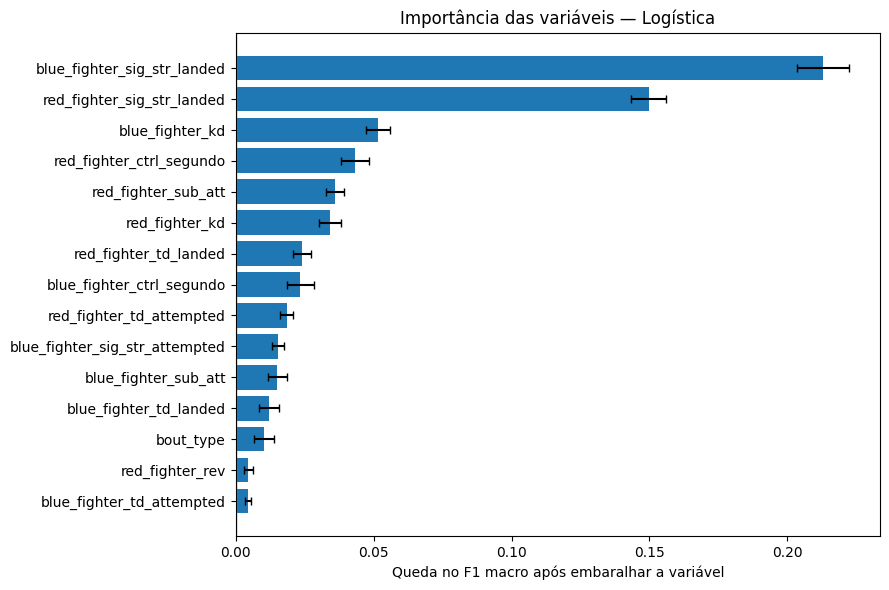


Importância por permutação — Random Forest


,feature,importancia_media,desvio_padrao
9,blue_fighter_sig_str_landed,0.0702,0.0089
1,red_fighter_sig_str_landed,0.0456,0.0066
8,blue_fighter_kd,0.0425,0.0030
5,red_fighter_sub_att,0.0327,0.0039
10,blue_fighter_sig_str_attempted,0.0291,0.0030
0,red_fighter_kd,0.0287,0.0055
15,blue_fighter_ctrl_segundo,0.0222,0.0036
7,red_fighter_ctrl_segundo,0.0177,0.0059
13,blue_fighter_sub_att,0.0160,0.0024
11,blue_fighter_td_landed,0.0094,0.0031


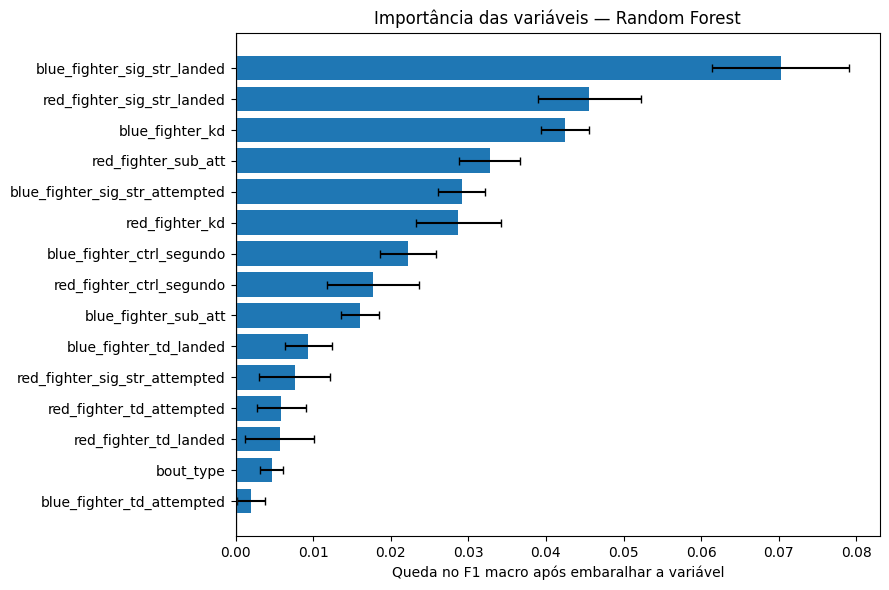

c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Importância por permutação — LightGBM


,feature,importancia_media,desvio_padrao
9,blue_fighter_sig_str_landed,0.1840,0.0109
1,red_fighter_sig_str_landed,0.1248,0.0082
5,red_fighter_sub_att,0.0357,0.0034
7,red_fighter_ctrl_segundo,0.0322,0.0073
8,blue_fighter_kd,0.0241,0.0037
0,red_fighter_kd,0.0232,0.0036
15,blue_fighter_ctrl_segundo,0.0198,0.0049
3,red_fighter_td_landed,0.0164,0.0048
13,blue_fighter_sub_att,0.0162,0.0035
17,bout_type,0.0050,0.0020


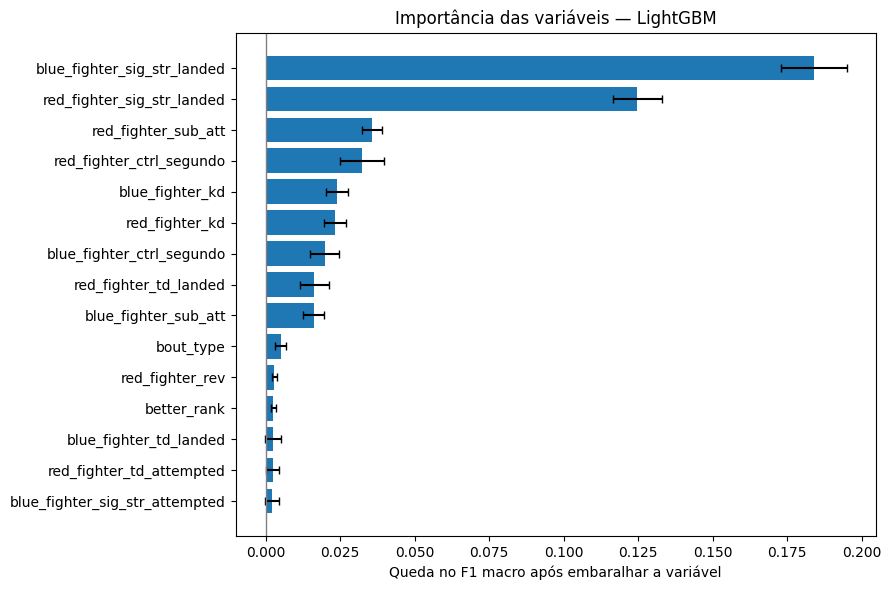

In [426]:
 
modelos_importancia = {
    **modelos_crua,
    "LightGBM": melhor_lgbm_crua,
}

importancias_por_modelo = {}

for nome, modelo in modelos_importancia.items():
    resultado = permutation_importance(
        modelo,
        teste_crua[features_crua],
        teste_crua["alvo_red_vence"],
        scoring="f1_macro",
        n_repeats=10,
        random_state=42,
        n_jobs=-1,
    )

    tabela = pd.DataFrame({
        "feature": features_crua,
        "importancia_media": resultado.importances_mean,
        "desvio_padrao": resultado.importances_std,
    }).sort_values("importancia_media", ascending=False)

    importancias_por_modelo[nome] = tabela

    print(f"\nImportância por permutação — {nome}")
    display(tabela.round(4))

    top = tabela.head(15).sort_values("importancia_media")

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(
        top["feature"],
        top["importancia_media"],
        xerr=top["desvio_padrao"],
        capsize=3,
    )
    ax.axvline(0, color="gray", linewidth=1)
    ax.set(
        title=f"Importância das variáveis — {nome}",
        xlabel="Queda no F1 macro após embaralhar a variável",
    )
    plt.tight_layout()
    plt.show()

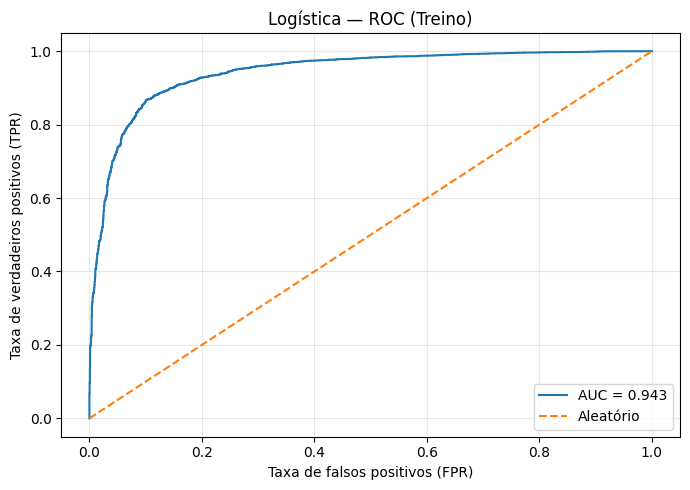

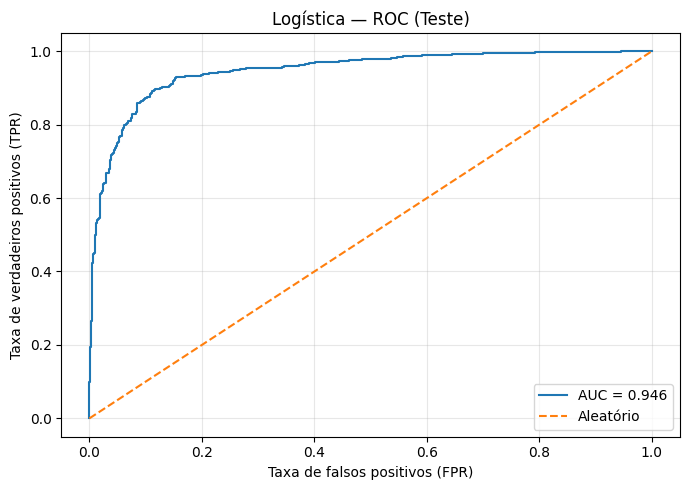

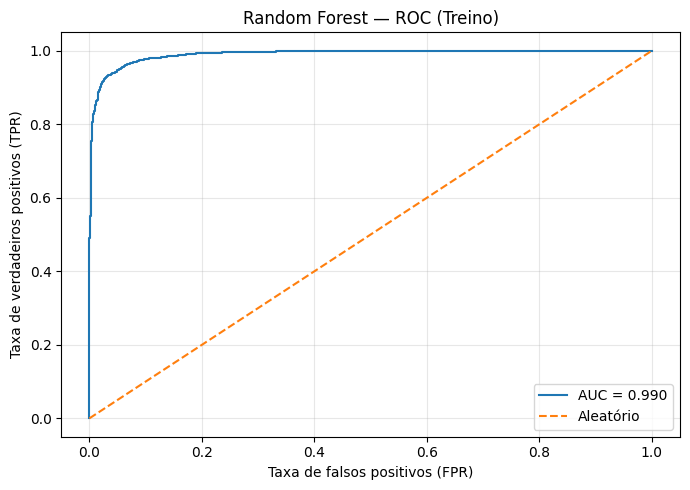

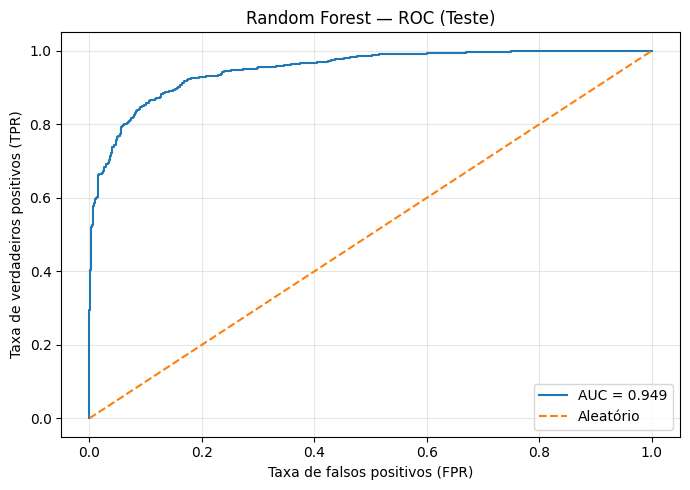

c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


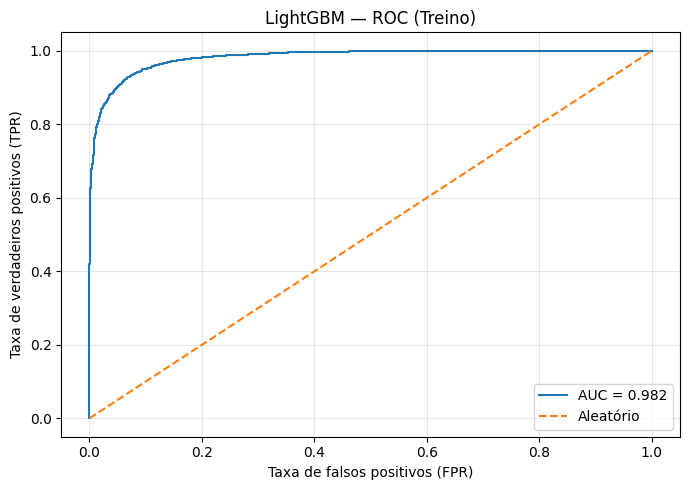

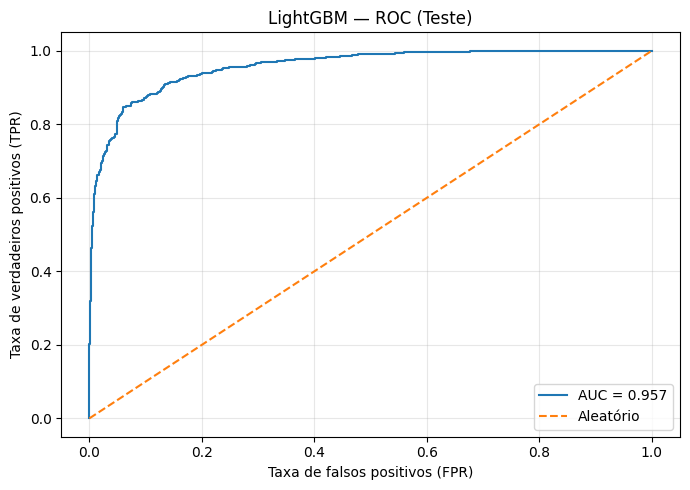

,modelo,auc_treino,auc_teste,diferenca
0,Logística,0.943,0.946,-0.004
1,Random Forest,0.990,0.949,0.041
2,LightGBM,0.982,0.957,0.026


In [427]:
def plot_roc_auc(y_true, y_score, title="Curva ROC"):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Aleatório")
    plt.xlabel("Taxa de falsos positivos (FPR)")
    plt.ylabel("Taxa de verdadeiros positivos (TPR)")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return auc


modelos_roc = {
    **modelos_crua,
    "LightGBM": melhor_lgbm_crua,
}

resultados_auc = []

for nome, modelo in modelos_roc.items():
    y_score_tr = modelo.predict_proba(
        treino_crua[features_crua]
    )[:, 1]

    y_score_te = modelo.predict_proba(
        teste_crua[features_crua]
    )[:, 1]

    auc_tr = plot_roc_auc(
        treino_crua["alvo_red_vence"],
        y_score_tr,
        title=f"{nome} — ROC (Treino)",
    )

    auc_te = plot_roc_auc(
        teste_crua["alvo_red_vence"],
        y_score_te,
        title=f"{nome} — ROC (Teste)",
    )

    resultados_auc.append({
        "modelo": nome,
        "auc_treino": auc_tr,
        "auc_teste": auc_te,
        "diferenca": auc_tr - auc_te,
    })

display(pd.DataFrame(resultados_auc).round(3))

<!-- ###### Resultados

O LightGBM apresentou a maior ROC-AUC no conjunto de teste (0,957). A regressão logística apresentou desempenho próximo (0,946), com menor discrepância entre treino e teste. A Random Forest apresentou a maior discrepância, sugerindo maior tendência ao sobreajuste. -->

##### Modelo - Base eriquecida

In [432]:
alvo = "alvo_red_vence"

# ============================================================
# 1. Divisão da base: 80% treino e 20% teste
# ============================================================

treino_enriquecida, teste_enriquecida = train_test_split(
    base_enriquecida,
    test_size=0.20,
    random_state=42,
    stratify=base_enriquecida[alvo],
)

# Excluir apenas das entradas; preservar a base original.
colunas_excluir = [
    alvo,
    "event_date",
    "red_fighter_id",
    "blue_fighter_id",
    "round",
    "red_fighter_result",
    "blue_fighter_result",
    "method",
    "bonus",
    "red_fighter_pts_mean",
    "blue_fighter_pts_mean",
]

X_train_enriquecida = treino_enriquecida.drop(
    columns=colunas_excluir,
    errors="ignore",
).copy()

X_test_enriquecida = teste_enriquecida.drop(
    columns=colunas_excluir,
    errors="ignore",
).copy()

y_train_enriquecida = treino_enriquecida[alvo].copy()
y_test_enriquecida = teste_enriquecida[alvo].copy()

features_enriquecida = X_train_enriquecida.columns.tolist()

# ============================================================
# 2. Separação dos tipos de entrada
# ============================================================

# Categorias: receberão OneHotEncoder
categoricas_candidatas = [
    "better_rank",
    "bout_type",
    "red_grupo_temporal",
    "blue_grupo_temporal",
    "red_cluster_dia",
    "blue_cluster_dia",
    "red_cluster_anterior_tecnico",
    "blue_cluster_anterior_tecnico",
]

categoricas_enriquecida = [
    c for c in categoricas_candidatas
    if c in features_enriquecida
]

# Indicadores: receberão conversão para 0/1
booleanas_candidatas = [
    f"{cor}_{campo}"
    for cor in ["red", "blue"]
    for campo in [
        "alterou_perfil_desde_ultima",
        "houve_transicao_ate_dia",
        "transicao_encontrada",
        "entrou_em_perfil_tecnico",
    ]
]

booleanas_enriquecida = list(dict.fromkeys(
    [
        c for c in booleanas_candidatas
        if c in features_enriquecida
    ]
    + X_train_enriquecida.select_dtypes(
        include="bool"
    ).columns.tolist()
))

booleanas_enriquecida = [
    c for c in booleanas_enriquecida
    if c not in categoricas_enriquecida
]

# Métricas e contagens: imputação e padronização
numericas_enriquecida_cols = [
    c
    for c in X_train_enriquecida.select_dtypes(
        include="number"
    ).columns
    if c not in categoricas_enriquecida + booleanas_enriquecida
]

# Evitar descarte silencioso de colunas sem tratamento definido
classificadas = set(
    categoricas_enriquecida
    + booleanas_enriquecida
    + numericas_enriquecida_cols
)

pendentes = [
    c for c in features_enriquecida
    if c not in classificadas
]

if pendentes:
    raise ValueError(
        f"Defina o tratamento ou exclua estas colunas: {pendentes}"
    )

# ============================================================
# 3. Funções de conversão usadas dentro do pipeline
# ============================================================

def converter_booleanos(X):
    tabela = pd.DataFrame(X).copy()

    mapa = {
        "true": 1.0,
        "false": 0.0,
        "1": 1.0,
        "0": 0.0,
        "1.0": 1.0,
        "0.0": 0.0,
    }

    for coluna in tabela.columns:
        original = tabela[coluna]

        convertido = (
            original.astype("string")
            .str.strip()
            .str.lower()
            .map(mapa)
        )

        invalidos = original.notna() & convertido.isna()

        if invalidos.any():
            raise ValueError(
                f"Valores inválidos em {coluna}: "
                f"{original.loc[invalidos].unique().tolist()}"
            )

        tabela[coluna] = convertido.astype(float)

    return tabela.to_numpy(dtype=float)


def converter_categorias(X):
    tabela = pd.DataFrame(X).astype("string")
    return tabela.astype(object).where(tabela.notna(), np.nan)

# ============================================================
# 4. Pré-processamento — apenas definição, sem fit
# ============================================================

preprocesse_enriquecida = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputacao", SimpleImputer(
                    strategy="median",
                    keep_empty_features=True,
                )),
                ("escala", StandardScaler()),
            ]),
            numericas_enriquecida_cols,
        ),
        (
            "bool",
            Pipeline([
                ("conversao", FunctionTransformer(
                    converter_booleanos,
                    feature_names_out="one-to-one",
                )),
                ("imputacao", SimpleImputer(
                    strategy="most_frequent",
                    keep_empty_features=True,
                )),
            ]),
            booleanas_enriquecida,
        ),
        (
            "cat",
            Pipeline([
                ("conversao", FunctionTransformer(
                    converter_categorias,
                    feature_names_out="one-to-one",
                )),
                ("imputacao", SimpleImputer(
                    strategy="constant",
                    fill_value="Sem informação",
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                )),
            ]),
            categoricas_enriquecida,
        ),
    ],
    remainder="drop",
)

print("Lutas no treino:", len(treino_enriquecida))
print("Lutas no teste:", len(teste_enriquecida))
print("\nOneHotEncoder:", categoricas_enriquecida)
print("\nIndicadores 0/1:", booleanas_enriquecida)
print("\nNuméricas:", numericas_enriquecida_cols)

Lutas no treino: 6864
Lutas no teste: 1717

OneHotEncoder: ['better_rank', 'bout_type', 'red_grupo_temporal', 'blue_grupo_temporal', 'red_cluster_dia', 'blue_cluster_dia', 'red_cluster_anterior_tecnico', 'blue_cluster_anterior_tecnico']

Indicadores 0/1: ['red_alterou_perfil_desde_ultima', 'red_houve_transicao_ate_dia', 'red_transicao_encontrada', 'blue_alterou_perfil_desde_ultima', 'blue_houve_transicao_ate_dia', 'blue_transicao_encontrada']

Numéricas: ['red_fighter_sig_str_body_pct', 'blue_fighter_sig_str_body_pct', 'red_fighter_sig_str_leg_pct', 'blue_fighter_sig_str_leg_pct', 'red_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_distance_pct', 'red_fighter_sig_str_clinch_pct', 'blue_fighter_sig_str_clinch_pct', 'time_seconds', 'red_odds', 'blue_odds', 'red_dec_odds', 'blue_dec_odds', 'red_sub_odds', 'blue_sub_odds', 'red_ko_odds', 'blue_ko_odds', 'diff_kd', 'diff_sig_str_pct', 'diff_td_pct', 'diff_sub_att', 'diff_rev', 'diff_ctrl', 'red_rank', 'blue_rank', 'qtd_particoes', 'te

In [429]:
classificadores_enriquecida = {
    "Logística": LogisticRegression(
        max_iter=2000,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    ),
}

modelos_enriquecida = {}
predicoes_enriquecida = {}
resultados_enriquecida = []

# 2. Treinamento e avaliação
for nome, classificador in classificadores_enriquecida.items():

    # Cada modelo recebe sua própria cópia do pré-processador.
    modelo = Pipeline([
        ("preprocessamento", clone(preprocesse_enriquecida)),
        ("classificador", clone(classificador)),
    ])

    # Imputação, escala e encoder são ajustados somente no treino.
    modelo.fit(
        X_train_enriquecida,
        y_train_enriquecida,
    )

    previsoes = modelo.predict(X_test_enriquecida)

    probabilidades = modelo.predict_proba(
        X_test_enriquecida
    )[:, 1]

    # Métricas no teste
    resultados_enriquecida.append({
        "modelo": nome,
        "acuracia": accuracy_score(
            y_test_enriquecida, previsoes
        ),
        "acuracia_balanceada": balanced_accuracy_score(
            y_test_enriquecida, previsoes
        ),
        "f1_macro": f1_score(
            y_test_enriquecida,
            previsoes,
            average="macro",
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_test_enriquecida, probabilidades
        ),
    })

    # Relatório por classe
    print(f"\nModelo: {nome}")

    print(classification_report(
        y_test_enriquecida,
        previsoes,
        labels=[0, 1],
        target_names=["Azul venceu", "Vermelho venceu"],
        zero_division=0,
    ))

    # Matriz: linhas = real; colunas = previsto
    matriz = confusion_matrix(
        y_test_enriquecida,
        previsoes,
        labels=[0, 1],
    )

    display(pd.DataFrame(
        matriz,
        index=["Real: azul venceu", "Real: vermelho venceu"],
        columns=[
            "Previsto: azul venceu",
            "Previsto: vermelho venceu",
        ],
    ))

    # Guardar pipelines treinados e previsões
    modelos_enriquecida[nome] = modelo

    predicoes_enriquecida[nome] = {
        "classe": previsoes,
        "probabilidade_red": probabilidades,
    }

# 3. Comparação dos resultados
avaliacao_enriquecida = pd.DataFrame(
    resultados_enriquecida
)

display(avaliacao_enriquecida.round(3))


Modelo: Logística
                 precision    recall  f1-score   support

    Azul venceu       0.85      0.84      0.85       617
Vermelho venceu       0.91      0.92      0.92      1100

       accuracy                           0.89      1717
      macro avg       0.88      0.88      0.88      1717
   weighted avg       0.89      0.89      0.89      1717



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,520,97
Real: vermelho venceu,89,1011



Modelo: Random Forest
                 precision    recall  f1-score   support

    Azul venceu       0.84      0.77      0.80       617
Vermelho venceu       0.88      0.92      0.90      1100

       accuracy                           0.86      1717
      macro avg       0.86      0.84      0.85      1717
   weighted avg       0.86      0.86      0.86      1717



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,474,143
Real: vermelho venceu,92,1008


,modelo,acuracia,acuracia_balanceada,f1_macro,roc_auc
0,Logística,0.892,0.881,0.882,0.952
1,Random Forest,0.863,0.842,0.848,0.941


<!-- ######
Com base nos resultados do modelo base iremos aplicar uma regularização e uma técninca de redução de complexidade para entendermos se conseguimos uma performance melhor -->

In [430]:
cv_ajustes = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

experimentos_regularizacao = {
    "Logística regularizada": (
        LogisticRegression(
            solver="liblinear",
            max_iter=3000,
            random_state=42,
        ),
        {
            "classificador__penalty": ["l1", "l2"],
            # Quanto menor C, maior a regularização
            "classificador__C": [0.01, 0.1, 1.0, 10.0],
        },
    ),
    "Random Forest regularizada": (
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=1,  # Paralelismo ficará no GridSearchCV
        ),
        {
            "classificador__max_depth": [10, None],
            "classificador__min_samples_leaf": [3, 10],
            "classificador__max_features": ["sqrt", 0.7],
        },
    ),
}

modelos_regularizados_enriquecida = {}
buscas_regularizacao = {}
resultados_cv_regularizacao = []

for nome, (classificador, parametros) in (
    experimentos_regularizacao.items()
):
    pipeline = Pipeline([
        ("preprocessamento", clone(preprocesse_enriquecida)),
        ("classificador", classificador),
    ])

    busca = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring={
            "f1_macro": "f1_macro",
            "roc_auc": "roc_auc",
        },
        refit="f1_macro",
        cv=cv_ajustes,
        n_jobs=-1,
        verbose=1,
        error_score="raise",
    )

    busca.fit(X_train_enriquecida, y_train_enriquecida)

    modelos_regularizados_enriquecida[nome] = (
        busca.best_estimator_
    )
    buscas_regularizacao[nome] = busca

    resultados_cv_regularizacao.append({
        "modelo": nome,
        "f1_macro_cv": busca.best_score_,
        "melhores_parametros": busca.best_params_,
    })

display(pd.DataFrame(resultados_cv_regularizacao))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,modelo,f1_macro_cv,melhores_parametros
0,Logística regularizada,0.877363,"{'classificador__C': 1.0, 'classificador__pena..."
1,Random Forest regularizada,0.877407,"{'classificador__max_depth': None, 'classifica..."


In [431]:
modelo_base_stepwise = modelos_enriquecida["Logística"]


def criar_pipeline_stepwise(colunas):
    pipeline = clone(modelo_base_stepwise)
    prep = pipeline.named_steps["preprocessamento"]

    # Adaptar as listas do pré-processador ao subconjunto.
    prep.set_params(transformers=[
        (
            nome,
            transformador,
            [c for c in originais if c in colunas],
        )
        for nome, transformador, originais in prep.transformers
    ])

    return pipeline


def avaliar_subconjunto(colunas): 
    return cross_val_score(
        criar_pipeline_stepwise(colunas),
        X_train_enriquecida[colunas],
        y_train_enriquecida,
        scoring="f1_macro",
        cv=cv_ajustes,
        n_jobs=-1,
        error_score="raise",
    ).mean()


features_stepwise = X_train_enriquecida.columns.tolist()
score_atual = avaliar_subconjunto(features_stepwise)
ganho_minimo = 0.001
historico_stepwise = []

print(f"F1 macro CV inicial: {score_atual:.4f}")

while len(features_stepwise) > 1:
    candidatos = []

    for coluna in features_stepwise:
        subconjunto = [
            c for c in features_stepwise if c != coluna
        ]

        score = avaliar_subconjunto(subconjunto)
        candidatos.append((score, coluna))

    melhor_score, coluna_remover = max(candidatos)

    if melhor_score - score_atual < ganho_minimo:
        break

    features_stepwise.remove(coluna_remover)
    score_atual = melhor_score

    historico_stepwise.append({
        "variavel_removida": coluna_remover,
        "features_restantes": len(features_stepwise),
        "f1_macro_cv": score_atual,
    })

    print(
        f"Removida: {coluna_remover} | "
        f"F1 macro CV: {score_atual:.4f}"
    )

modelo_stepwise_enriquecida = criar_pipeline_stepwise(
    features_stepwise
)

modelo_stepwise_enriquecida.fit(
    X_train_enriquecida[features_stepwise],
    y_train_enriquecida,
)

print("\nVariáveis mantidas:", features_stepwise)
display(pd.DataFrame(historico_stepwise))

F1 macro CV inicial: 0.8770
Removida: red_fighter_sig_str_clinch_pct | F1 macro CV: 0.8785

Variáveis mantidas: ['bout_type', 'red_fighter_sig_str_body_pct', 'blue_fighter_sig_str_body_pct', 'red_fighter_sig_str_leg_pct', 'blue_fighter_sig_str_leg_pct', 'red_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_distance_pct', 'blue_fighter_sig_str_clinch_pct', 'time_seconds', 'red_odds', 'blue_odds', 'red_dec_odds', 'blue_dec_odds', 'red_sub_odds', 'blue_sub_odds', 'red_ko_odds', 'blue_ko_odds', 'better_rank', 'diff_kd', 'diff_sig_str_pct', 'diff_td_pct', 'diff_sub_att', 'diff_rev', 'diff_ctrl', 'red_rank', 'blue_rank', 'qtd_particoes', 'tempo_total_min', 'red_cluster_dia', 'red_grupo_temporal', 'red_cluster_anterior_tecnico', 'red_alterou_perfil_desde_ultima', 'red_qtd_transicoes_ate_dia', 'red_houve_transicao_ate_dia', 'red_transicao_encontrada', 'blue_cluster_dia', 'blue_grupo_temporal', 'blue_cluster_anterior_tecnico', 'blue_alterou_perfil_desde_ultima', 'blue_qtd_transicoes_ate_dia

,variavel_removida,features_restantes,f1_macro_cv
0,red_fighter_sig_str_clinch_pct,60,0.878472


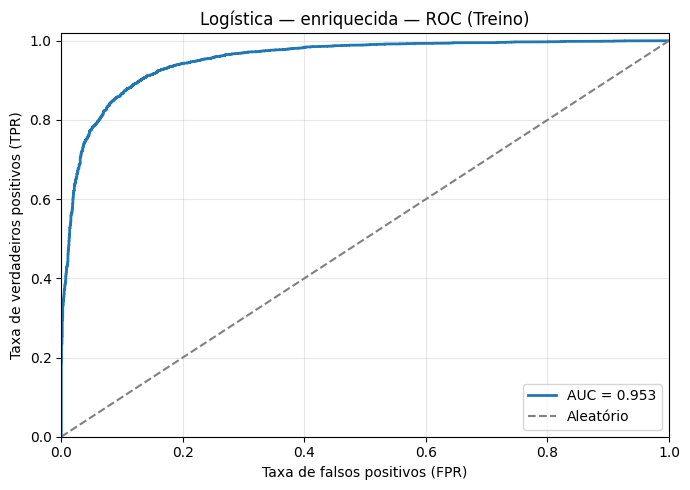

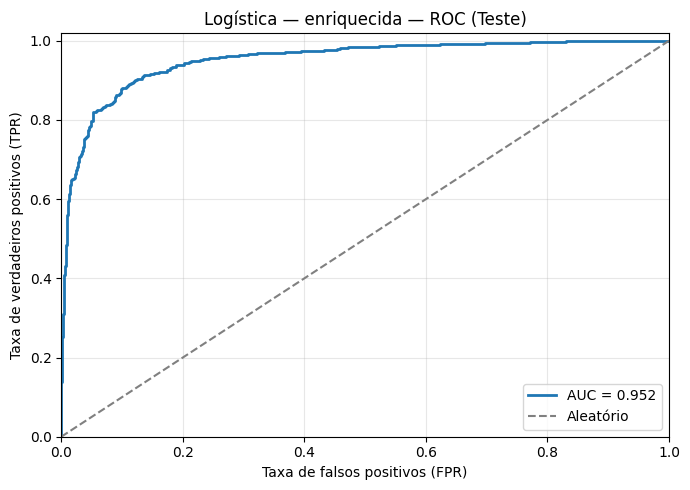

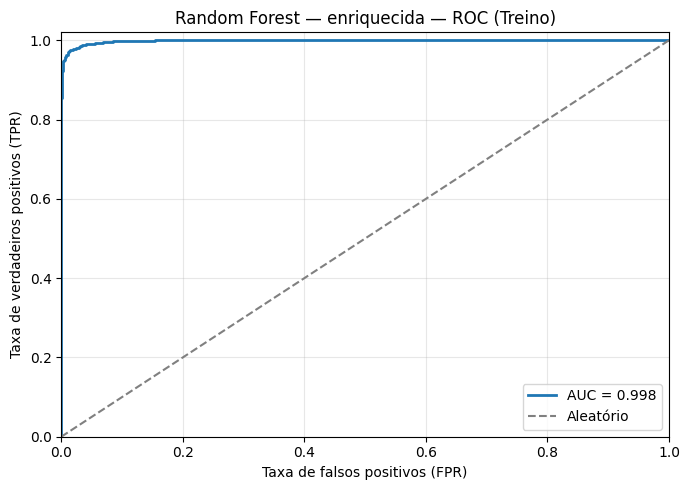

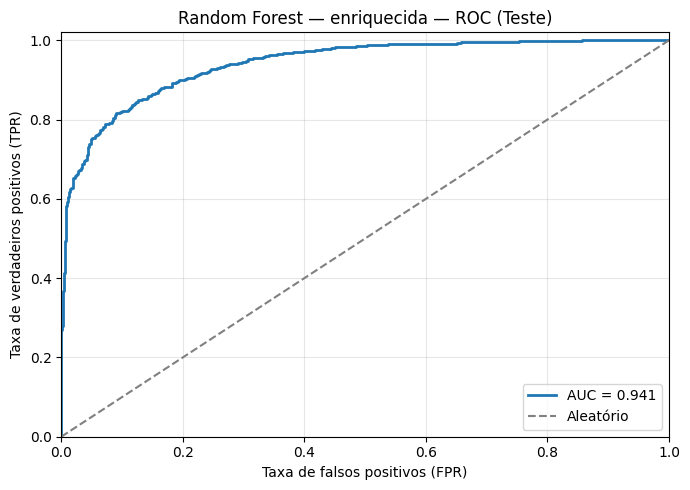

,modelo,auc_treino,auc_teste,diferenca
0,Logística,0.953,0.952,0.001
1,Random Forest,0.998,0.941,0.057


In [433]:
# ROC/AUC — modelos-base da enriquecida já treinados.
# Executar depois da célula que preenche modelos_enriquecida.
# Esta célula não reajusta modelos nem pré-processadores.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


def plot_roc_auc_enriquecida(y_true, y_score, title="Curva ROC"):
    fpr, tpr, _ = roc_curve(y_true, y_score, pos_label=1)
    auc = roc_auc_score(y_true, y_score)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}", linewidth=2)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatório")
    ax.set(
        xlabel="Taxa de falsos positivos (FPR)",
        ylabel="Taxa de verdadeiros positivos (TPR)",
        title=title,
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    return auc


resultados_auc_enriquecida = []

for nome, modelo in modelos_enriquecida.items():
    # Garantir que o pipeline corresponde à seleção de features atual.
    if list(modelo.feature_names_in_) != X_train_enriquecida.columns.tolist():
        raise ValueError(
            f"{nome}: as features mudaram desde o treinamento. "
            "Execute novamente a célula de treinamento da enriquecida."
        )

    y_score_tr = modelo.predict_proba(X_train_enriquecida)[:, 1]
    y_score_te = modelo.predict_proba(X_test_enriquecida)[:, 1]

    auc_tr = plot_roc_auc_enriquecida(
        y_train_enriquecida,
        y_score_tr,
        title=f"{nome} — enriquecida — ROC (Treino)",
    )
    auc_te = plot_roc_auc_enriquecida(
        y_test_enriquecida,
        y_score_te,
        title=f"{nome} — enriquecida — ROC (Teste)",
    )
    resultados_auc_enriquecida.append({
        "modelo": nome,
        "auc_treino": auc_tr,
        "auc_teste": auc_te,
        "diferenca": auc_tr - auc_te,
    })

avaliacao_auc_enriquecida = pd.DataFrame(resultados_auc_enriquecida)
display(avaliacao_auc_enriquecida.round(3))


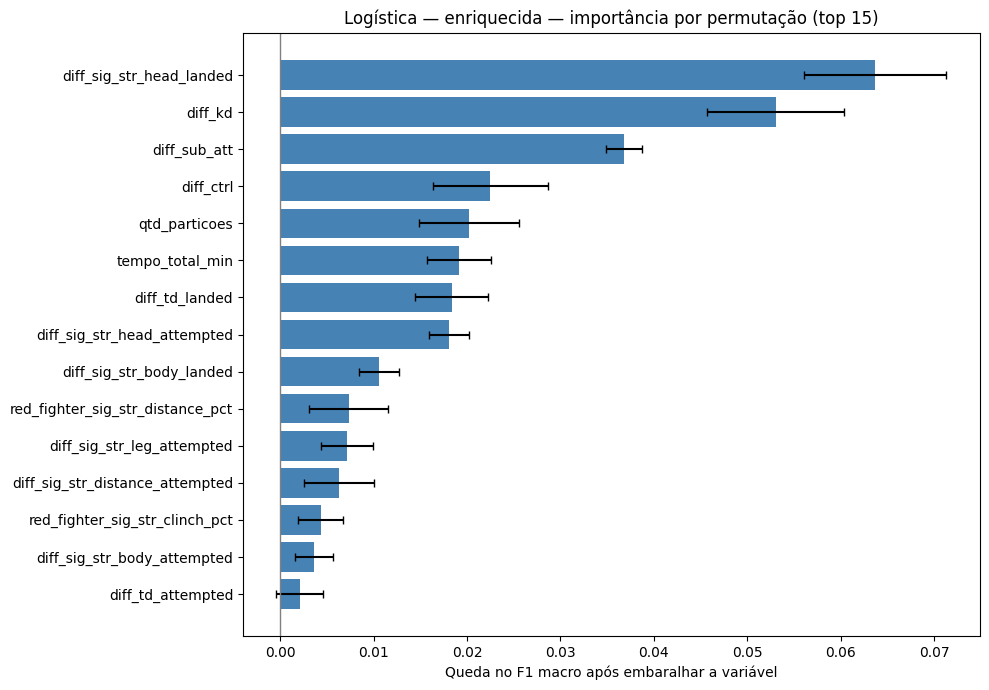

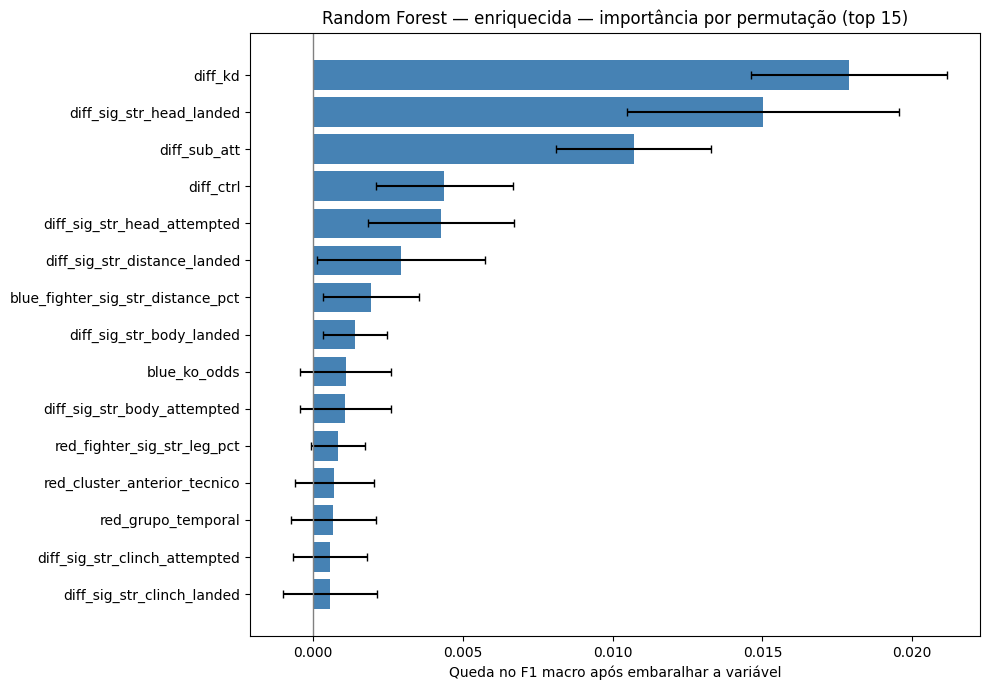

In [434]:
# Importância por permutação — pipelines já treinados da enriquecida.
# Mede a queda no F1 macro no teste ao embaralhar cada feature original.
# Uso descritivo: não selecionar novas features com base no teste.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

importancias_enriquecida = {}

for nome, modelo in modelos_enriquecida.items():
    if list(modelo.feature_names_in_) != X_test_enriquecida.columns.tolist():
        raise ValueError(
            f"{nome}: as features mudaram desde o treinamento. "
            "Execute novamente a célula de treinamento da enriquecida."
        )

    resultado = permutation_importance(
        modelo,
        X_test_enriquecida,
        y_test_enriquecida,
        scoring="f1_macro",
        n_repeats=10,
        random_state=42,
        n_jobs=1,  # A Random Forest já usa paralelismo internamente.
    )

    tabela = pd.DataFrame({
        "feature": X_test_enriquecida.columns,
        "importancia_media": resultado.importances_mean,
        "desvio_padrao": resultado.importances_std,
    }).sort_values("importancia_media", ascending=False)
    importancias_enriquecida[nome] = tabela

    top = tabela.head(15).sort_values("importancia_media")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(
        top["feature"],
        top["importancia_media"],
        xerr=top["desvio_padrao"],
        capsize=3,
        color="steelblue",
    )
    ax.axvline(0, color="gray", linewidth=1)
    ax.set(
        title=f"{nome} — enriquecida — importância por permutação (top 15)",
        xlabel="Queda no F1 macro após embaralhar a variável",
    )
    # Barras de erro: desvio entre embaralhamentos, não intervalo de confiança.
    # Features correlacionadas podem dividir importância entre si.
    fig.tight_layout()
    plt.show()


##### Modelo pré-luta: uma base com histórico, cadastro e clusters

Cada linha representa um confronto. O alvo é 1 para vitória do vermelho e 0 para vitória do azul. Uma única versão integra gold_fight_com_transicoes, gold_hist_clusterizado e gold_fighter. Resultados servem apenas para construir o alvo; as estatísticas do combate corrente não são copiadas para as entradas.

O histórico utiliza métricas anteriores ao dia da luta. Zeros marcados por flags de ausência são restaurados para NaN antes da imputação. O cadastro fornece idade na data, altura e alcance; totais atuais de carreira, peso e postura não entram diretamente. Altura e alcance são tratados como atributos estáveis.

Clusters e transições são os retratos temporais já construídos. A avaliação começa depois da calibração dos clusters e o teste contém as datas mais recentes. Nenhum dia é dividido entre treino e teste. Imputação, escala e OneHotEncoder são ajustados apenas no treino.

Protocolo: previsão sequencial antes de cada luta. O histórico de uma luta do teste pode incorporar resultados de datas anteriores desse mesmo período, nunca do próprio dia ou do futuro. Isso não equivale a prever todo o período de uma vez na data do corte.

Limitações herdadas: as taxas usam a duração calculada na engenharia de dados. O pipeline atual de clusters utiliza medidas do cadastro, incluindo peso sem histórico por data, e seus rótulos dependem desse tratamento anterior. Esse ponto deve ser revisto antes de afirmar uma validação histórica integral dos atributos usados nos clusters.


In [ ]:
ml_pre_luta = importlib.reload(ml_pre_luta)
fontes_necessarias_pre_luta = [
    "gold_fight_com_transicoes", "gold_hist_clusterizado",
    "gold_fighter", "data_fim_calibracao",
]
faltando_pre_luta = [
    nome for nome in fontes_necessarias_pre_luta if nome not in globals()
]
if faltando_pre_luta:
    raise ValueError(
        "Execute antes os clusters/transições. Faltam: "
        + ", ".join(faltando_pre_luta)
    )

lutas_pre_luta = gold_fight_com_transicoes.copy(deep=True)
hist_pre_luta = gold_hist_clusterizado.copy(deep=True)
cadastro_pre_luta = gold_fighter.copy(deep=True)

base_pre_luta, especificacao_pre_luta = ml_pre_luta.construir_base_pre_luta(
    lutas=lutas_pre_luta,
    hist=hist_pre_luta,
    cadastro=cadastro_pre_luta,
    apos_calibracao=data_fim_calibracao,
)
alvo_pre_luta = "alvo_red_vence"
features_pre_luta = (
    especificacao_pre_luta["numericas"]
    + especificacao_pre_luta["categoricas"]
)
print("Confrontos na base pré-luta:", len(base_pre_luta))
print("Período:", base_pre_luta["event_date"].min().date(),
      "até", base_pre_luta["event_date"].max().date())
print("Features numéricas:", len(especificacao_pre_luta["numericas"]))
print("Features categóricas:", len(especificacao_pre_luta["categoricas"]))


Confrontos na base pré-luta: 7175
Período: 2010-09-25 até 2026-06-27
Features numéricas: 46
Features categóricas: 5


In [441]:
# 2. Conferir as entradas e as ausências.
print("Numéricas:", especificacao_pre_luta["numericas"])
print("OneHotEncoder:", especificacao_pre_luta["categoricas"])
resumo_ausencias_pre_luta = pd.DataFrame({
    "ausentes": base_pre_luta[features_pre_luta].isna().sum(),
    "percentual": 100 * base_pre_luta[features_pre_luta].isna().mean(),
}).sort_values("percentual", ascending=False)
display(resumo_ausencias_pre_luta.loc[
    resumo_ausencias_pre_luta["ausentes"].gt(0)
].round(2))
display(base_pre_luta[alvo_pre_luta].value_counts().rename("lutas"))


Numéricas: ['red_qtd_lutas_anteriores', 'red_taxa_vitoria_anterior', 'red_dias_ultima_luta', 'red_fl_estreante', 'red_sig_str_min_antes', 'red_sig_str_recebidos_min_antes', 'red_td_15min_antes', 'red_td_tent_15min_antes', 'red_sub_15min_antes', 'red_rev_15min_antes', 'red_kd_15min_antes', 'red_ctrl_pct_antes', 'red_sig_str_acc_antes', 'red_str_def_antes', 'red_td_acc_antes', 'red_td_def_antes', 'red_sig_str_tent_min_antes', 'red_age_at_fight', 'red_height_cm', 'red_reach_cm', 'blue_qtd_lutas_anteriores', 'blue_taxa_vitoria_anterior', 'blue_dias_ultima_luta', 'blue_fl_estreante', 'blue_sig_str_min_antes', 'blue_sig_str_recebidos_min_antes', 'blue_td_15min_antes', 'blue_td_tent_15min_antes', 'blue_sub_15min_antes', 'blue_rev_15min_antes', 'blue_kd_15min_antes', 'blue_ctrl_pct_antes', 'blue_sig_str_acc_antes', 'blue_str_def_antes', 'blue_td_acc_antes', 'blue_td_def_antes', 'blue_sig_str_tent_min_antes', 'blue_age_at_fight', 'blue_height_cm', 'blue_reach_cm', 'red_alterou_perfil_desde_ulti

,ausentes,percentual
blue_cluster_anterior_tecnico,3847,53.62
red_cluster_anterior_tecnico,2817,39.26
blue_td_acc_antes,1933,26.94
blue_td_def_antes,1782,24.84
blue_taxa_vitoria_anterior,1331,18.55
blue_sig_str_acc_antes,1316,18.34
blue_sig_str_tent_min_antes,1311,18.27
blue_str_def_antes,1311,18.27
blue_ctrl_pct_antes,1311,18.27
blue_kd_15min_antes,1311,18.27


alvo_red_vence
1    4154
0    3021
Name: lutas, dtype: int64

##### Divisão temporal e tamanho do conjunto de teste

Nesta execução, a fonte contém **8.736 lutas**. Após manter somente confrontos com vitória e derrota complementares, restam **8.581 lutas**. A avaliação pré-luta considera apenas datas posteriores à calibração dos clusters, encerrada em **15/09/2010**, resultando em **7.175 lutas elegíveis**.

A divisão é cronológica: as datas mais antigas são usadas no treinamento e aproximadamente 20% das datas mais recentes são reservadas para teste. Todas as lutas de um mesmo dia permanecem no mesmo conjunto. Por esse motivo, a proporção de linhas não precisa ser exatamente 80%/20%.

| Conjunto | Quantidade de lutas | Período |
|---|---:|---|
| Treino | 5.686 | Datas anteriores a 29/07/2023 |
| Teste | 1.489 | De 29/07/2023 a 27/06/2026 |
| Total elegível | 7.175 | Após a calibração dos clusters |

As **1.489 lutas** apresentadas no resumo correspondem somente ao **conjunto de teste**, que não foi utilizado para ajustar os classificadores. As demais **5.686 lutas** foram utilizadas para treinamento. Assim, as métricas e a contagem de acertos avaliam previsões em confrontos posteriores ao período de ajuste.

Essas quantidades correspondem à execução atual e devem ser atualizadas caso a fonte de dados, o período de calibração ou a divisão temporal sejam alterados.


In [442]:
# 3. Divisão cronológica por datas inteiras.
treino_pre_luta, teste_pre_luta, data_corte_pre_luta = (
    ml_pre_luta.dividir_temporal(base_pre_luta, fracao_teste=0.20)
)
X_train_pre_luta = treino_pre_luta[features_pre_luta].copy()
X_test_pre_luta = teste_pre_luta[features_pre_luta].copy()
y_train_pre_luta = treino_pre_luta[alvo_pre_luta].copy()
y_test_pre_luta = teste_pre_luta[alvo_pre_luta].copy()

print("Data de corte:", data_corte_pre_luta.date())
print("Treino:", len(treino_pre_luta), "lutas |",
      treino_pre_luta["event_date"].min().date(), "até",
      treino_pre_luta["event_date"].max().date())
print("Teste:", len(teste_pre_luta), "lutas |",
      teste_pre_luta["event_date"].min().date(), "até",
      teste_pre_luta["event_date"].max().date())
assert treino_pre_luta["event_date"].max() < teste_pre_luta["event_date"].min()


Data de corte: 2023-07-29
Treino: 5686 lutas | 2010-09-25 até 2023-07-22
Teste: 1489 lutas | 2023-07-29 até 2026-06-27


In [443]:
# 4. Uma base integrada; classificadores iniciais sobre as mesmas lutas.
# A referência majoritária usa somente a frequência das classes no treino.
# Cada modelo ajusta seu próprio pipeline apenas no conjunto de treino.
avaliacao_pre_luta, modelos_pre_luta, predicoes_pre_luta = (
    ml_pre_luta.treinar_modelos_pre_luta(
        treino_pre_luta, teste_pre_luta, especificacao_pre_luta
    )
)
display(avaliacao_pre_luta.round(4))


,modelo,acuracia,acuracia_balanceada,f1_macro,roc_auc,log_loss,brier
0,Referência majoritária,0.5628,0.5000,0.3601,0.5000,0.6861,0.2465
1,Logística,0.6125,0.5841,0.5743,0.6435,0.6537,0.2310
2,Random Forest,0.6172,0.5809,0.5595,0.6477,0.6550,0.2315


In [444]:
# 5. Matrizes e probabilidades dos confrontos no período de teste.
from sklearn.metrics import confusion_matrix, classification_report

previsoes_confrontos_pre_luta = teste_pre_luta[
    ["id_luta_pre_luta", "event_date", "red_fighter_id",
     "blue_fighter_id", alvo_pre_luta]
].copy()
for nome, modelo in modelos_pre_luta.items():
    previsoes = modelo.predict(X_test_pre_luta)
    indice_red = list(modelo.classes_).index(1)
    prob_red = modelo.predict_proba(X_test_pre_luta)[:, indice_red]
    previsoes_confrontos_pre_luta[f"prob_red_{nome}"] = prob_red

    print(f"\nPré-luta — {nome}")
    print(classification_report(
        y_test_pre_luta, previsoes, labels=[0, 1],
        target_names=["Azul venceu", "Vermelho venceu"], zero_division=0,
    ))
    display(pd.DataFrame(
        confusion_matrix(y_test_pre_luta, previsoes, labels=[0, 1]),
        index=["Real: azul venceu", "Real: vermelho venceu"],
        columns=["Previsto: azul venceu", "Previsto: vermelho venceu"],
    ))
display(previsoes_confrontos_pre_luta.head(10))



Pré-luta — Referência majoritária
                 precision    recall  f1-score   support

    Azul venceu       0.00      0.00      0.00       651
Vermelho venceu       0.56      1.00      0.72       838

       accuracy                           0.56      1489
      macro avg       0.28      0.50      0.36      1489
   weighted avg       0.32      0.56      0.41      1489



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,0,651
Real: vermelho venceu,0,838



Pré-luta — Logística
                 precision    recall  f1-score   support

    Azul venceu       0.59      0.36      0.45       651
Vermelho venceu       0.62      0.81      0.70       838

       accuracy                           0.61      1489
      macro avg       0.61      0.58      0.57      1489
   weighted avg       0.61      0.61      0.59      1489



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,233,418
Real: vermelho venceu,159,679



Pré-luta — Random Forest
                 precision    recall  f1-score   support

    Azul venceu       0.64      0.29      0.40       651
Vermelho venceu       0.61      0.87      0.72       838

       accuracy                           0.62      1489
      macro avg       0.62      0.58      0.56      1489
   weighted avg       0.62      0.62      0.58      1489



,Previsto: azul venceu,Previsto: vermelho venceu
Real: azul venceu,190,461
Real: vermelho venceu,109,729


,id_luta_pre_luta,event_date,red_fighter_id,blue_fighter_id,alvo_red_vence,prob_red_Referência majoritária,prob_red_Logística,prob_red_Random Forest
5686,1502,2023-07-29,077e3ace32b72be9,65cdf4ec31143d86,1,0.583187,0.505069,0.609846
5687,1503,2023-07-29,d3df1add9d9a7efb,ab943cd2c3c17825,1,0.583187,0.587290,0.474314
5688,1504,2023-07-29,029eaff01e6bb8f0,9e8f6c728eb01124,0,0.583187,0.630359,0.638641
5689,1505,2023-07-29,01641ba5df0c69b0,b27a1fcb56a3035a,1,0.583187,0.408986,0.571098
5690,1506,2023-07-29,a845f0735bc67405,65db4065e2bc107d,1,0.583187,0.640890,0.594788
5691,1507,2023-07-29,99df7d0a2a08a8a8,e5549c82bfb5582d,0,0.583187,0.570010,0.565699
5692,1508,2023-07-29,4aa58269d0664b5b,681399317dbf4701,0,0.583187,0.565148,0.544332
5693,1509,2023-07-29,c58f51dedb310998,3a46b268013afede,0,0.583187,0.469462,0.522820
5694,1510,2023-07-29,f29a6350c69f4a33,b1e5bcaad32a3cac,1,0.583187,0.794423,0.665759
5695,1511,2023-07-29,9d83f6da776ff7d6,972c456ff38b2015,1,0.583187,0.636140,0.579240


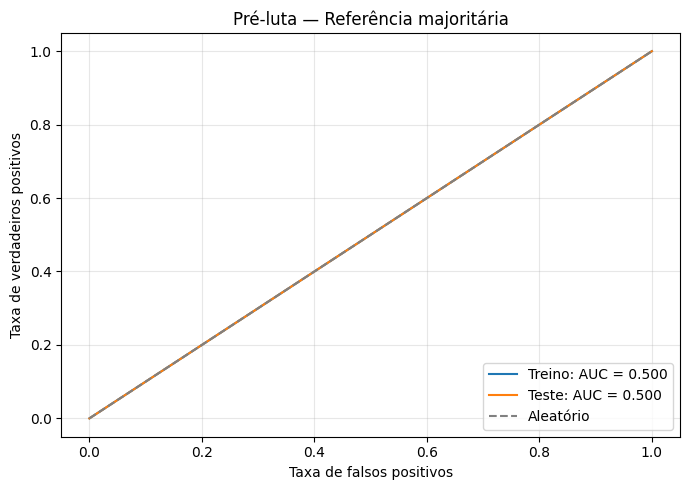

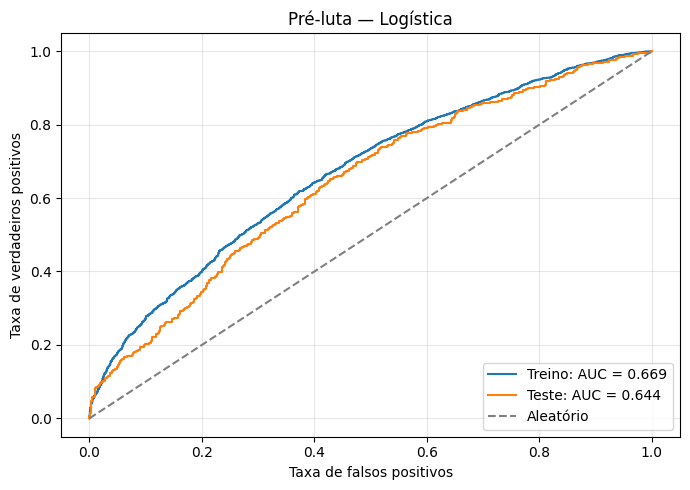

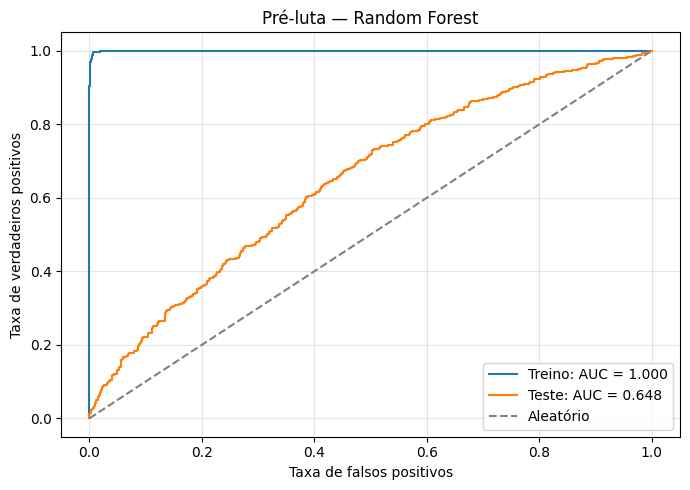

,modelo,auc_treino,auc_teste,diferenca
0,Referência majoritária,0.5000,0.5000,0.0000
1,Logística,0.6695,0.6435,0.0260
2,Random Forest,0.9996,0.6477,0.3519


In [ ]:
resultados_auc_pre_luta = []
for nome, modelo in modelos_pre_luta.items():
    indice_red = list(modelo.classes_).index(1)
    prob_treino = modelo.predict_proba(X_train_pre_luta)[:, indice_red]
    prob_teste = modelo.predict_proba(X_test_pre_luta)[:, indice_red]
    auc_treino = roc_auc_score(y_train_pre_luta, prob_treino)
    auc_teste = roc_auc_score(y_test_pre_luta, prob_teste)

    fig, ax = plt.subplots(figsize=(7, 5))
    for rotulo, reais, probabilidades in [
        ("Treino", y_train_pre_luta, prob_treino),
        ("Teste", y_test_pre_luta, prob_teste),
    ]:
        fpr, tpr, _ = roc_curve(reais, probabilidades, pos_label=1)
        auc = roc_auc_score(reais, probabilidades)
        ax.plot(fpr, tpr, label=f"{rotulo}: AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
    ax.set(title=f"Pré-luta — {nome}",
           xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    resultados_auc_pre_luta.append({
        "modelo": nome, "auc_treino": auc_treino,
        "auc_teste": auc_teste, "diferenca": auc_treino - auc_teste,
    })
display(pd.DataFrame(resultados_auc_pre_luta).round(4))


In [450]:
# 7. Quem tem maior chance de vencer?
# Usar os confrontos do teste, com histórico/cadastro/clusters já preparados.
modelo_chances = modelos_pre_luta["Logística"]

# Classe 0 = azul venceu; classe 1 = vermelho venceu.
probabilidades = modelo_chances.predict_proba(X_test_pre_luta)
prob_red = probabilidades[:, list(modelo_chances.classes_).index(1)]
prob_blue = probabilidades[:, list(modelo_chances.classes_).index(0)]

# Os nomes servem apenas para apresentar os resultados.
cadastro_nomes = cadastro_pre_luta.copy()
cadastro_nomes["fighter_id"] = (
    cadastro_nomes["fighter_id"].astype("string").str.strip()
)
nomes_lutadores = cadastro_nomes.set_index("fighter_id")["fighter_name"]
ids_red = teste_pre_luta["red_fighter_id"]
ids_blue = teste_pre_luta["blue_fighter_id"]

chances_pre_luta = pd.DataFrame({
    "data": teste_pre_luta["event_date"],
    "vermelho": ids_red.map(nomes_lutadores).fillna(ids_red),
    "azul": ids_blue.map(nomes_lutadores).fillna(ids_blue),
    "chance_vermelho_pct": prob_red * 100,
    "chance_azul_pct": prob_blue * 100,
})
chances_pre_luta["favorito"] = np.where(
    prob_red > prob_blue,
    chances_pre_luta["vermelho"],
    np.where(prob_blue > prob_red, chances_pre_luta["azul"], "Sem favorito"),
)
# Resultado observado: usado apenas para comparar com a previsão.
chances_pre_luta["resultado_real"] = np.where(
    teste_pre_luta["alvo_red_vence"].eq(1),
    chances_pre_luta["vermelho"],
    chances_pre_luta["azul"],
)
display(chances_pre_luta.round(2).head(10))

# Resumo de todas as lutas, não apenas das dez exibidas acima.
total_lutas = len(chances_pre_luta)
acertos = int(
    chances_pre_luta["favorito"].eq(chances_pre_luta["resultado_real"]).sum()
)
sem_favorito = int(chances_pre_luta["favorito"].eq("Sem favorito").sum())
erros = total_lutas - acertos - sem_favorito

resumo_chances_pre_luta = pd.DataFrame([{
    "lutas_avaliadas": total_lutas,
    "acertos": acertos,
    "erros": erros,
    "sem_favorito": sem_favorito,
    "acerto_pct": 100 * acertos / total_lutas if total_lutas else np.nan,
}])
display(resumo_chances_pre_luta.round(2))


,data,vermelho,azul,chance_vermelho_pct,chance_azul_pct,favorito,resultado_real
5686,2023-07-29,CJ Vergara,Vinicius Salvador,50.51,49.49,CJ Vergara,CJ Vergara
5687,2023-07-29,Derrick Lewis,Marcos Rogerio de Lima,58.73,41.27,Derrick Lewis,Derrick Lewis
5688,2023-07-29,Dustin Poirier,Justin Gaethje,63.04,36.96,Dustin Poirier,Justin Gaethje
5689,2023-07-29,Gabriel Bonfim,Trevin Giles,40.90,59.10,Trevin Giles,Gabriel Bonfim
5690,2023-07-29,Jake Matthews,Darrius Flowers,64.09,35.91,Jake Matthews,Jake Matthews
5691,2023-07-29,Jan Blachowicz,Alex Pereira,57.00,43.00,Jan Blachowicz,Alex Pereira
5692,2023-07-29,Matthew Semelsberger,Uros Medic,56.51,43.49,Matthew Semelsberger,Uros Medic
5693,2023-07-29,Michael Chiesa,Kevin Holland,46.95,53.05,Kevin Holland,Kevin Holland
5694,2023-07-29,Miranda Maverick,Priscila Cachoeira,79.44,20.56,Miranda Maverick,Miranda Maverick
5695,2023-07-29,Roman Kopylov,Claudio Ribeiro,63.61,36.39,Roman Kopylov,Roman Kopylov


,lutas_avaliadas,acertos,erros,sem_favorito,acerto_pct
0,1489,912,577,0,61.25
